## 0. Project Overview

### 0.1 Project Definition

- **Objective:** Build and validate a single harmonised **GCC panel** (`country`, `year`) that combines **resource dependence**, **economic structure**, **export diversification**, **innovation**, and **AI readiness** with **GDP context**—so downstream work can use one consistent file (`merged_dataset.csv`) and optional subsets without re-merging sources.
- **Business value:** Supports evidence-based comparison across **Saudi Arabia, United Arab Emirates, Qatar, Kuwait, Oman, and Bahrain** for research and policy narratives on diversification and transition (PostOil / FY Lab context).

### 0.2 Fundamental analysis (5W1H) — Updated

| Question | What to capture |
| :--- | :--- |
| **What?** | **Observation:** Each row is a unique **country × year** panel. **Variables:** WDI economic structure and resource dependence (e.g., `oil_rents_gdp`, `fuel_exports_pct`, `services_gdp`, `manufacturing_gdp`, `exports_gdp`, `imports_gdp`, `trade_openness_gdp`), GDP levels (`gdp`, `gdp_per_capita`), UNCTAD export concentration (`export_concentration`), **international tourism receipts** (`tourism_receipts_pct_exports`, `tourism_receipts_usd`), WIPO GII (`innovation_index`, `innovation_rank`), Oxford Insights AI Readiness (`ai_readiness`, `ai_readiness_rank`, all pillar columns), and select governance/implementation subcomponents. Data may be **% of GDP/exports**, **US$**, or **index scores/ranks**; not all variables are present for every year. |
| **Who?** | Primary sources: **World Bank** (WDI, Databank), **UNCTAD** (UNCTADstat), **Oxford Insights** (Government AI Readiness Reports), **WIPO** (Global Innovation Index). Some indices (notably AI readiness) involve **manual extraction** of indicator scores from published PDF tables, introducing added transcription/coding risk. |
| **When?** | **Data frequency/coverage:** WDI economic series — annual (full available history per country/variable). **Export concentration:** annual for most (~1990s onward). **AI readiness:** available for 2023–2025 (point-in-time, not annual time series). **Innovation index/rank:** 2025 composite (represents current edition, source-years may vary). |
| **Where?** | **Geography:** Six **GCC** countries: Bahrain, Kuwait, Oman, Qatar, Saudi Arabia, United Arab Emirates. **Data location:** Primary harmonized dataset at `datasets/merged_dataset.csv`; supporting data in SQLite DB at `datasets/postoil.db` (tables: `wdi_core`, `export_concentration`, `ai_readiness`, `innovation`, `tourism`). |
| **How?** | Sources are acquired (machine- or manually-extracted), then **tidied** (long-form), columns **renamed** for clarity, and features **selected** and **panel-merged** via a controlled **outer join** on `(country, year)`. Fixed column order is enforced, and all data validation (coverage, missingness, duplicates, schema, summary stats) happens in this notebook. Outer join is used so variables missing for certain years/countries remain as **NaN**, preserving maximum comparative power and surfacing reporting gaps. |
| **Why?** | The merged panel enables robust inter-country/year comparison of **diversification, innovation, and readiness** for economic transition across the GCC. The sources are internationally recognized and designed for comparability, but users must note: composite indices reflect **snapshots and methodological changes**, not continuous trends; variable availability is uneven; and manual data transcription can introduce human error. All limitations and update cadence are documented for downstream users. |

**Unknowns (documented gaps):** exact **publication/update cadence** for each vendor; **full pillar coverage** for AI readiness in every report year; **which underlying years** feed the GII composite in detail; any **future revisions** to back-series WDI values.


## 1. Imports

In [305]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data Validation

In [306]:
data = pd.read_csv("../datasets/merged_dataset.csv")
data.head()

,country,year,oil_rents_gdp,fuel_exports_pct,services_gdp,manufacturing_gdp,exports_gdp,imports_gdp,trade_openness_gdp,export_concentration,...,ai_readiness_rank,government_pillar,technology_sector_pillar,data_infrastructure_pillar,policy_capacity,ai_infrastructure,governance,public_sector_adoption,development_diffusion,resilience
0,Bahrain,1970,NaN,77.872151,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Bahrain,1971,NaN,81.414530,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Bahrain,1972,NaN,78.281501,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Bahrain,1973,NaN,80.622534,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Bahrain,1974,NaN,84.476909,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [307]:
data.tail(10)

,country,year,oil_rents_gdp,fuel_exports_pct,services_gdp,manufacturing_gdp,exports_gdp,imports_gdp,trade_openness_gdp,export_concentration,...,ai_readiness_rank,government_pillar,technology_sector_pillar,data_infrastructure_pillar,policy_capacity,ai_infrastructure,governance,public_sector_adoption,development_diffusion,resilience
354,United Arab Emirates,2016,11.080756,31.558975,59.384273,9.041228,94.474753,70.920266,165.395019,0.229,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
355,United Arab Emirates,2017,13.498573,35.998238,57.834028,9.135064,94.737396,70.739146,165.476542,0.232,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
356,United Arab Emirates,2018,17.098995,68.538174,53.550372,8.723038,90.842958,63.904047,154.747005,0.246,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
357,United Arab Emirates,2019,15.681592,77.838727,55.798403,8.842905,93.302309,70.519844,163.822153,0.253,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
358,United Arab Emirates,2020,10.494098,71.434332,58.715446,8.992077,98.072468,83.219421,181.291888,0.227,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
359,United Arab Emirates,2021,15.673095,70.321985,53.728465,8.772373,100.642574,82.266781,182.909355,0.242,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,United Arab Emirates,2022,NaN,73.144077,49.925804,8.544355,102.051989,83.689672,185.741661,0.299,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,United Arab Emirates,2023,NaN,68.202873,53.835192,9.458613,106.846139,92.198840,199.044979,0.280,...,18.0,78.32,56.67,76.28,NaN,NaN,NaN,NaN,NaN,NaN
362,United Arab Emirates,2024,NaN,NaN,54.901295,9.373633,NaN,NaN,NaN,0.282,...,NaN,83.89,59.20,83.89,NaN,NaN,NaN,NaN,NaN,NaN
363,United Arab Emirates,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.0,NaN,NaN,NaN,73.0,73.77,72.5,97.27,57.34,43.15


In [308]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 364 entries, 0 to 363
Data columns (total 29 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       364 non-null    str    
 1   year                          364 non-null    int64  
 2   oil_rents_gdp                 295 non-null    float64
 3   fuel_exports_pct              261 non-null    float64
 4   services_gdp                  200 non-null    float64
 5   manufacturing_gdp             219 non-null    float64
 6   exports_gdp                   270 non-null    float64
 7   imports_gdp                   270 non-null    float64
 8   trade_openness_gdp            270 non-null    float64
 9   export_concentration          180 non-null    float64
 10  tourism_receipts_pct_exports  100 non-null    float64
 11  tourism_receipts_usd          126 non-null    float64
 12  exports_usd                   270 non-null    float64
 13  imports_usd     

In [309]:
data.shape


(364, 29)

In [310]:
data.isna().sum()

country                           0
year                              0
oil_rents_gdp                    69
fuel_exports_pct                103
services_gdp                    164
manufacturing_gdp               145
exports_gdp                      94
imports_gdp                      94
trade_openness_gdp               94
export_concentration            184
tourism_receipts_pct_exports    264
tourism_receipts_usd            238
exports_usd                      94
imports_usd                      94
gdp                               6
gdp_per_capita                    6
innovation_index                358
innovation_rank                 358
ai_readiness                    346
ai_readiness_rank               352
government_pillar               352
technology_sector_pillar        352
data_infrastructure_pillar      352
policy_capacity                 358
ai_infrastructure               358
governance                      358
public_sector_adoption          358
development_diffusion       

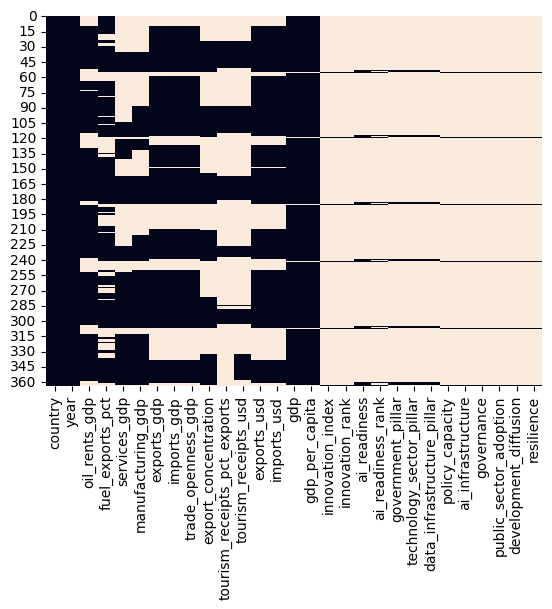

In [311]:
sns.heatmap(data.isna(), cbar=False)
plt.show()


In [312]:
data.describe()

,year,oil_rents_gdp,fuel_exports_pct,services_gdp,manufacturing_gdp,exports_gdp,imports_gdp,trade_openness_gdp,export_concentration,tourism_receipts_pct_exports,...,ai_readiness_rank,government_pillar,technology_sector_pillar,data_infrastructure_pillar,policy_capacity,ai_infrastructure,governance,public_sector_adoption,development_diffusion,resilience
count,364.000000,295.000000,261.000000,200.000000,219.000000,270.000000,270.000000,270.000000,180.000000,100.000000,...,12.000000,12.000000,12.000000,12.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
mean,1994.983516,33.419603,75.953309,44.848205,9.495796,60.833566,42.523848,103.357414,0.510306,6.151340,...,44.666667,66.210000,45.245833,76.224167,69.250000,58.870000,73.390000,75.751667,45.890000,44.611667
std,17.849532,14.833162,27.516820,11.144956,5.347967,18.382429,18.803136,33.157124,0.144350,5.177401,...,21.726956,15.448573,7.771413,5.204391,23.321128,9.018481,12.993986,17.134885,9.913377,7.394956
min,1960.000000,6.695589,0.000372,15.817289,0.100000,16.902039,11.900000,47.533159,0.227000,0.507691,...,15.000000,38.140000,36.930000,69.760000,35.000000,47.220000,52.630000,51.430000,30.190000,38.010000
25%,1980.000000,22.921845,73.683183,38.088730,7.497683,48.938160,28.554236,84.381335,0.387000,2.216866,...,26.500000,55.092500,38.857500,71.105000,53.125000,54.470000,72.125000,64.865000,41.352500,39.485000
50%,1995.000000,31.778024,85.165791,45.742774,8.805943,59.623961,37.962283,93.268172,0.531000,4.131525,...,49.000000,69.625000,42.800000,76.545000,76.750000,57.995000,72.500000,77.185000,46.520000,42.120000
75%,2010.000000,41.943539,92.099043,52.211101,10.492526,72.096510,51.033617,116.357331,0.628250,10.773833,...,57.250000,78.417500,50.422500,80.242500,86.500000,61.707500,76.250000,87.307500,52.985000,47.597500
max,2025.000000,87.085239,193.036704,87.730061,36.763018,115.323709,125.710915,220.867369,0.800000,20.185176,...,83.000000,83.890000,59.200000,83.890000,92.000000,73.770000,93.210000,97.270000,57.340000,57.390000


In [313]:
data[data["year"] >= 2022]

,country,year,oil_rents_gdp,fuel_exports_pct,services_gdp,manufacturing_gdp,exports_gdp,imports_gdp,trade_openness_gdp,export_concentration,...,ai_readiness_rank,government_pillar,technology_sector_pillar,data_infrastructure_pillar,policy_capacity,ai_infrastructure,governance,public_sector_adoption,development_diffusion,resilience
52,Bahrain,2022,NaN,0.042613,49.241139,20.935089,95.961365,71.179876,167.141241,0.362,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
53,Bahrain,2023,NaN,0.252931,51.944953,20.129788,87.351144,70.096711,157.447855,0.365,...,56.0,57.96,39.24,71.19,NaN,NaN,NaN,NaN,NaN,NaN
54,Bahrain,2024,NaN,0.000372,53.186144,19.909373,87.674996,70.143497,157.818492,0.356,...,NaN,45.62,37.61,79.76,NaN,NaN,NaN,NaN,NaN,NaN
55,Bahrain,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,48.0,NaN,NaN,NaN,46.5,58.04,72.50,83.37,48.50,49.08
116,Kuwait,2022,NaN,96.038261,44.820981,7.874358,60.449306,30.471105,90.920412,0.648,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
117,Kuwait,2023,NaN,95.516437,52.073901,7.551629,57.730151,38.349638,96.079788,0.571,...,69.0,38.14,40.58,70.85,NaN,NaN,NaN,NaN,NaN,NaN
118,Kuwait,2024,NaN,90.732149,55.854414,7.998218,NaN,NaN,NaN,0.297,...,NaN,46.49,36.93,70.36,NaN,NaN,NaN,NaN,NaN,NaN
119,Kuwait,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,83.0,NaN,NaN,NaN,35.0,53.31,52.63,51.43,30.19,38.01
182,Oman,2022,NaN,74.038398,42.326177,10.520522,63.250502,42.494507,105.745009,0.320,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
183,Oman,2023,NaN,74.191384,45.304038,9.349046,61.584343,44.862388,106.446731,0.318,...,50.0,69.35,37.71,69.76,NaN,NaN,NaN,NaN,NaN,NaN


In [314]:
data.duplicated(["country", "year"]).sum()

np.int64(0)

In [315]:
data.groupby("country")["year"].agg(["min", "max", "count"])

,min,max,count
country,,,
Bahrain,1970,2025,56
Kuwait,1962,2025,64
Oman,1960,2025,66
Qatar,1970,2025,56
Saudi Arabia,1960,2025,66
United Arab Emirates,1970,2025,56


In [316]:
data["year"].unique()

array([1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980,
       1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991,
       1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002,
       2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013,
       2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024,
       2025, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1960, 1961])

In [317]:
data["export_concentration"].describe()

count    180.000000
mean       0.510306
std        0.144350
min        0.227000
25%        0.387000
50%        0.531000
75%        0.628250
max        0.800000
Name: export_concentration, dtype: float64

In [318]:
data["country"].unique()

<StringArray>
['Bahrain', 'Kuwait', 'Oman', 'Qatar', 'Saudi Arabia', 'United Arab Emirates']
Length: 6, dtype: str

### Summary (post–data validation)

### Findings

- **Panel integrity:** One row per `(country, year)`; **no duplicate keys** — suitable master panel.
- **Geography:** Six GCC countries as expected.
- **Time coverage:** WDI and UNCTAD provide long annual series; **innovation** (GII) and **AI readiness** are **sparse** by design (snapshot / edition years), so many cells are **NaN** after the outer merge.
- **Missingness:** Heatmap and `isna().sum()` show **structured** gaps (blocks by source and period), not random noise.
- **Sanity:** `describe()` and spot checks (e.g. `export_concentration`, `year >= 2022`) support plausible ranges for a first QA pass.
- **Workflow:** If upstream extracts or the merge pipeline change, refresh `merged_dataset.csv` and re-run §2 so this validation matches the current panel.

### Decisions moving forward

- **No global row deletion** on the merged file — preserves the long macro history.
- **`merged_dataset.csv` unchanged** for upstream fidelity; **analysis-specific conventions** (e.g. visualization masks) live in this notebook and are documented in §3.1.
- **EDA** continues in **§3** (Block A macro/UNCTAD; Block B innovation snapshot; Block C AI readiness later).
- **Block A presentation:** **§3.1a** = configurable **focus** window on `macro_win` (often **2000 onward** for a contemporary read); **§3.1b** = **full year span** on `macro_win_full` for long-run context. Correlation matrices are **separate** per window (see §3.1 Summary).

### Integrated narrative

See **§3.1 Summary — Block A (Macro/UNCTAD): Sharp takeaways** for validation + Block A synthesis (focus vs full span, trade insights, correlation caveats) and the Bahrain/Kuwait fuel-export plotting convention.


---

# 3. Exploratory Data Analysis

In [319]:
data.columns

Index(['country', 'year', 'oil_rents_gdp', 'fuel_exports_pct', 'services_gdp',
       'manufacturing_gdp', 'exports_gdp', 'imports_gdp', 'trade_openness_gdp',
       'export_concentration', 'tourism_receipts_pct_exports',
       'tourism_receipts_usd', 'exports_usd', 'imports_usd', 'gdp',
       'gdp_per_capita', 'innovation_index', 'innovation_rank', 'ai_readiness',
       'ai_readiness_rank', 'government_pillar', 'technology_sector_pillar',
       'data_infrastructure_pillar', 'policy_capacity', 'ai_infrastructure',
       'governance', 'public_sector_adoption', 'development_diffusion',
       'resilience'],
      dtype='str')

In [320]:
ID_COLS = ["country", "year"]

In [321]:
# Block A — annual / dense macro + UNCTAD (time-series EDA)
COLS_MACRO = [
    "oil_rents_gdp",
    "fuel_exports_pct",
    "services_gdp",
    "manufacturing_gdp",
    "exports_gdp",
    "imports_gdp",
    "trade_openness_gdp",
    "export_concentration",
    "tourism_receipts_pct_exports",
    "tourism_receipts_usd",
    "exports_usd",
    "imports_usd",
    "gdp",
    "gdp_per_capita",
]

# Optional subgroups (same Block A; use if plots split levels vs shares)
COLS_RESOURCE = ["oil_rents_gdp", "fuel_exports_pct"]
COLS_STRUCTURE = ["services_gdp", "manufacturing_gdp"]
COLS_TRADE_SHARES = ["exports_gdp", "imports_gdp", "trade_openness_gdp"]
COLS_DIVERSIFICATION = ["export_concentration"]
COLS_TOURISM = ["tourism_receipts_pct_exports", "tourism_receipts_usd"]
COLS_TRADE_SCALE = ["exports_usd", "imports_usd"]
COLS_GDP_CONTEXT = ["gdp", "gdp_per_capita"]


In [322]:
# Block B — WIPO GII snapshot (sparse)
COLS_INNOVATION = ["innovation_index", "innovation_rank"]

In [323]:
# Block C — Oxford AI readiness snapshot + pillars (sparse)
COLS_AI_HEADLINE = ["ai_readiness", "ai_readiness_rank"]
COLS_AI_PILLARS = [
    "government_pillar",
    "technology_sector_pillar",
    "data_infrastructure_pillar",
    "policy_capacity",
    "ai_infrastructure",
    "governance",
    "public_sector_adoption",
    "development_diffusion",
    "resilience",
]
COLS_AI = COLS_AI_HEADLINE + COLS_AI_PILLARS

In [324]:
# Convenience: all feature columns (no keys)
COLS_ALL_FEATURES = COLS_MACRO + COLS_INNOVATION + COLS_AI

In [325]:
# Optional: dict for iteration / reporting
BLOCKS = {
    "macro": COLS_MACRO,
    "innovation": COLS_INNOVATION,
    "ai": COLS_AI,
}

In [326]:
# Subsets

macro_panel = data[ID_COLS + COLS_MACRO].copy()
innovation_panel = data[ID_COLS + COLS_INNOVATION].copy()
ai_panel = data[ID_COLS + COLS_AI].copy()

### 3.1 Block A — Macro and UNCTAD


In [327]:
# =============================================================================
# 3.1a  FOCUS WINDOW  - edit YEAR_START and YEAR_END only here
# =============================================================================
YEAR_START, YEAR_END = 2000, 2025

macro_panel["year"] = macro_panel["year"].astype(int)
macro_win = macro_panel.loc[macro_panel["year"].between(YEAR_START, YEAR_END)].copy()

print(f"macro_win   ->  {YEAR_START}-{YEAR_END}  ({len(macro_win):,} rows)")


macro_win   ->  2000-2025  (156 rows)


In [328]:
# =============================================================================
# 3.1  HELPERS + FULL SPAN  (`macro_win_full`)
# =============================================================================
cols_shares = COLS_RESOURCE + COLS_STRUCTURE
cols_trade_shares = COLS_TRADE_SHARES

YEAR_FULL_START = int(macro_panel["year"].min())
YEAR_FULL_END = int(macro_panel["year"].max())
macro_win_full = macro_panel.copy()

FUEL_MASK_MIN_PCT = 5.0
FUEL_MASK_COUNTRIES = ["Bahrain", "Kuwait"]


def apply_fuel_mask_for_display(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    m = out["country"].isin(FUEL_MASK_COUNTRIES) & (out["fuel_exports_pct"] < FUEL_MASK_MIN_PCT)
    out.loc[m, "fuel_exports_pct"] = np.nan
    return out


def add_trade_derived(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    denom = out["imports_usd"].replace(0, np.nan)
    out["export_import_ratio"] = out["exports_usd"] / denom
    out["log10_exports_usd"] = np.log10(out["exports_usd"].where(out["exports_usd"] > 0))
    out["log10_imports_usd"] = np.log10(out["imports_usd"].where(out["imports_usd"] > 0))
    return out


def line_by_country(df, value_col, suptitle=None):
    countries = sorted(df["country"].unique())
    n = len(countries)
    ncols = 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3.0 * nrows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, countries):
        sub = df[df["country"] == c].sort_values("year")
        ax.plot(sub["year"], sub[value_col], marker=".", ms=3, lw=1)
        ax.set_title(c, fontsize=9)
        ax.grid(True, ls=":", lw=0.5, alpha=0.6)
    for ax in axes[n:]:
        ax.set_visible(False)
    fig.suptitle(suptitle or value_col, fontsize=11)
    plt.tight_layout()
    plt.show()


print(f"macro_win_full ->  {YEAR_FULL_START}-{YEAR_FULL_END}  ({len(macro_win_full):,} rows)")
# Optional QA: data.loc[data["country"].isin(FUEL_MASK_COUNTRIES), ["country", "year", "fuel_exports_pct"]].sort_values(["country", "year"])


macro_win_full ->  1960-2025  (364 rows)


#### 3.1a Focus — line charts


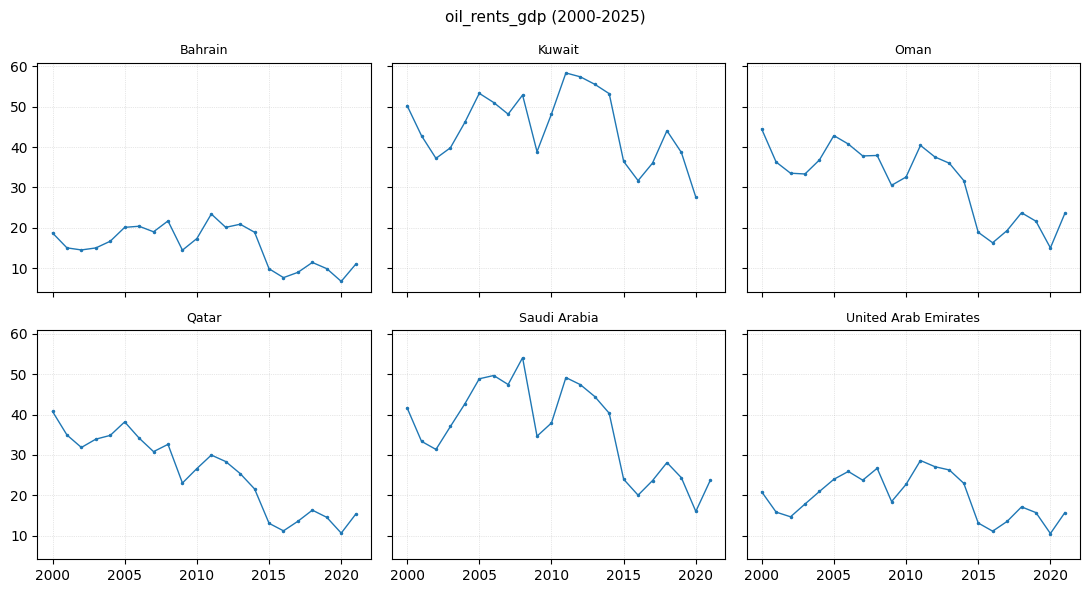

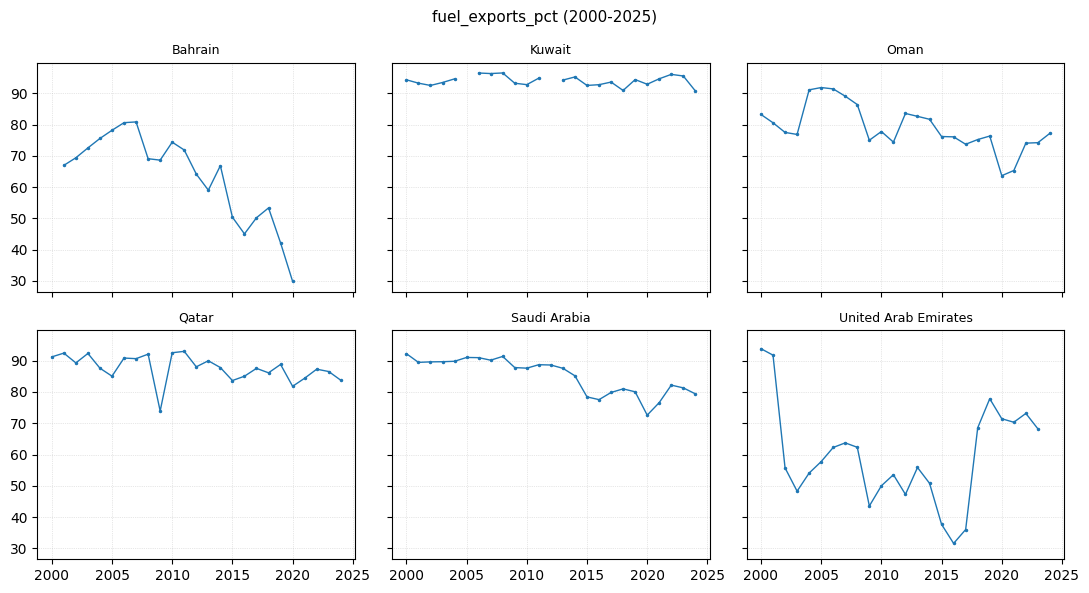

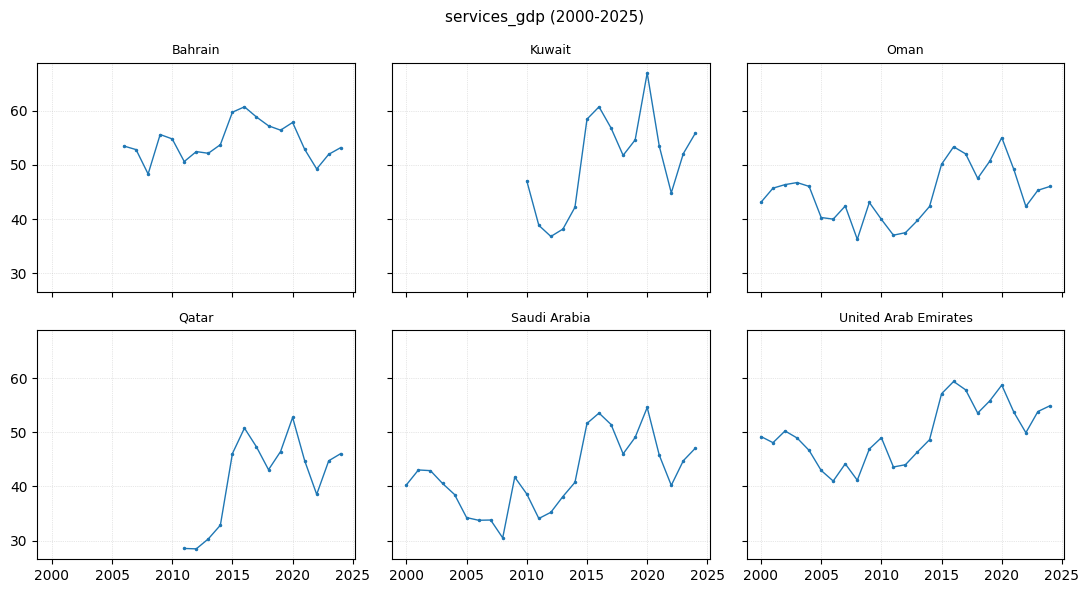

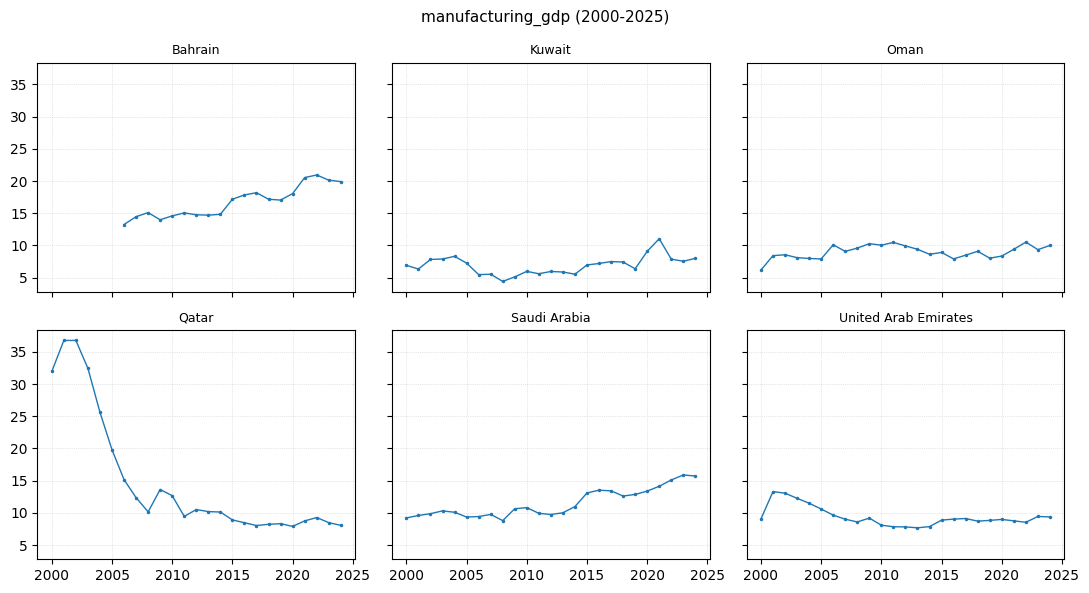

In [329]:
# Shares of GDP (WDI); fuel_exports_pct uses display mask only
for col in cols_shares:
    df_plot = apply_fuel_mask_for_display(macro_win) if col == "fuel_exports_pct" else macro_win
    line_by_country(df_plot, col, suptitle=f"{col} ({YEAR_START}-{YEAR_END})")


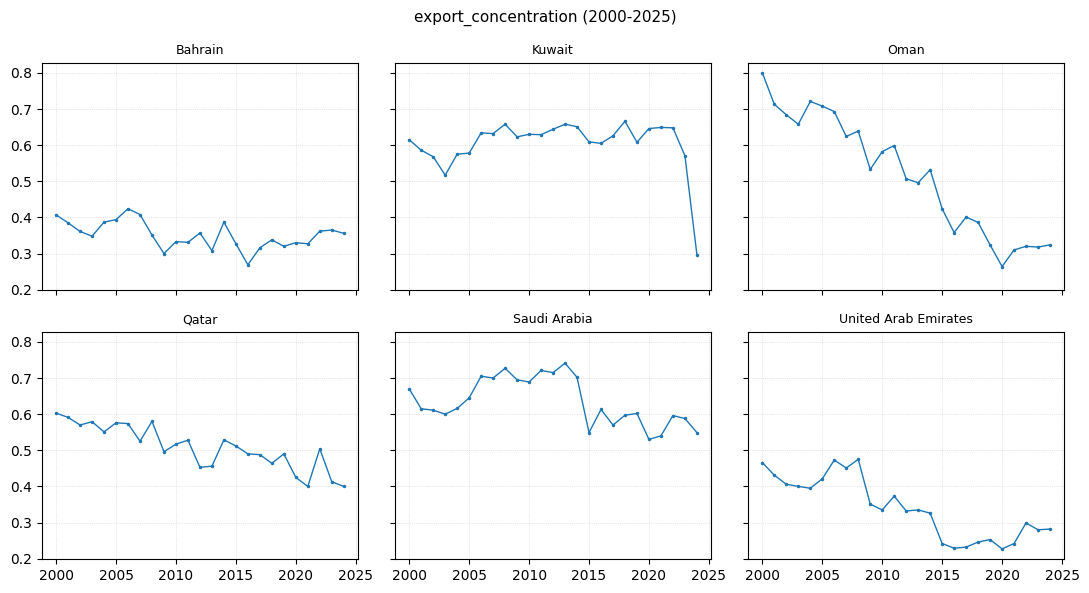

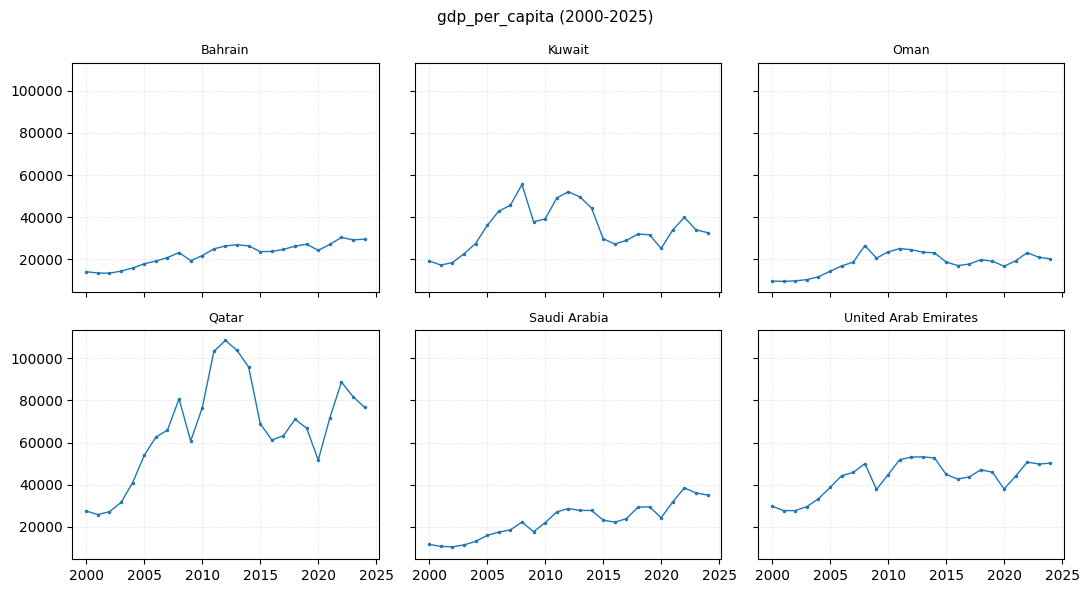

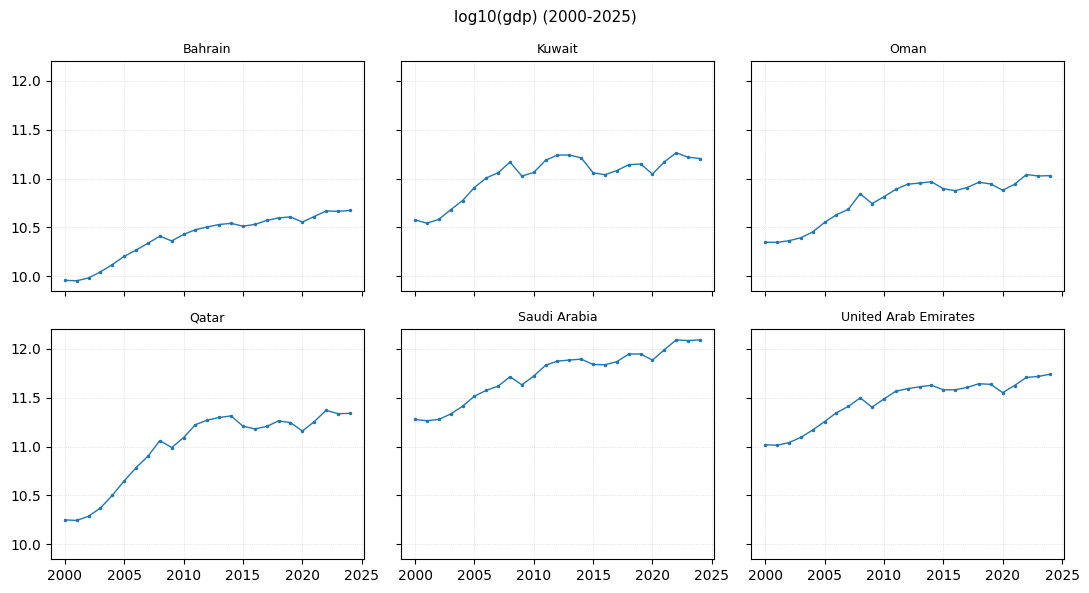

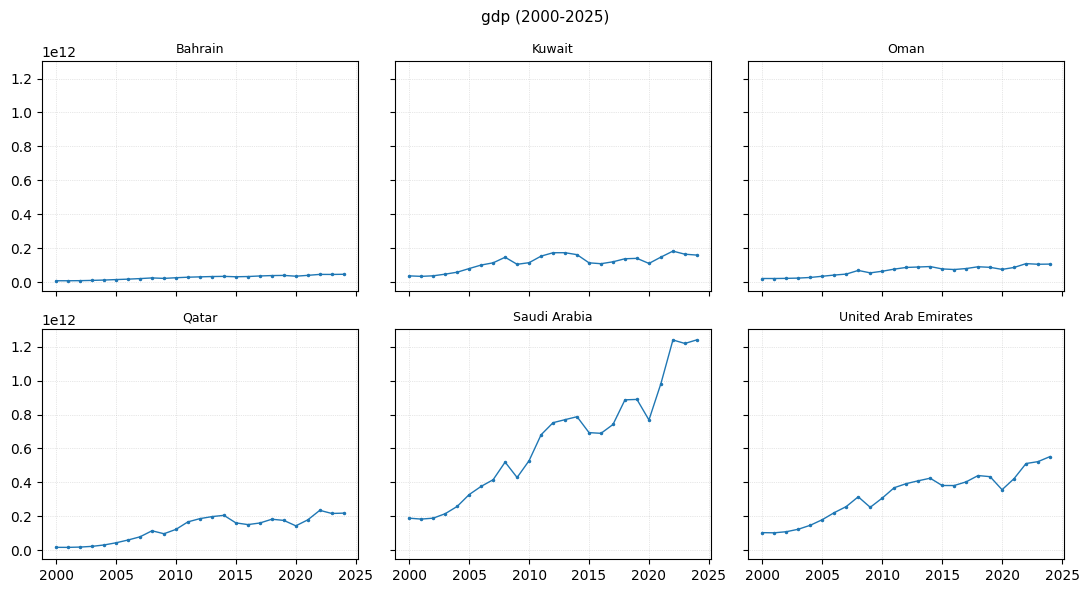

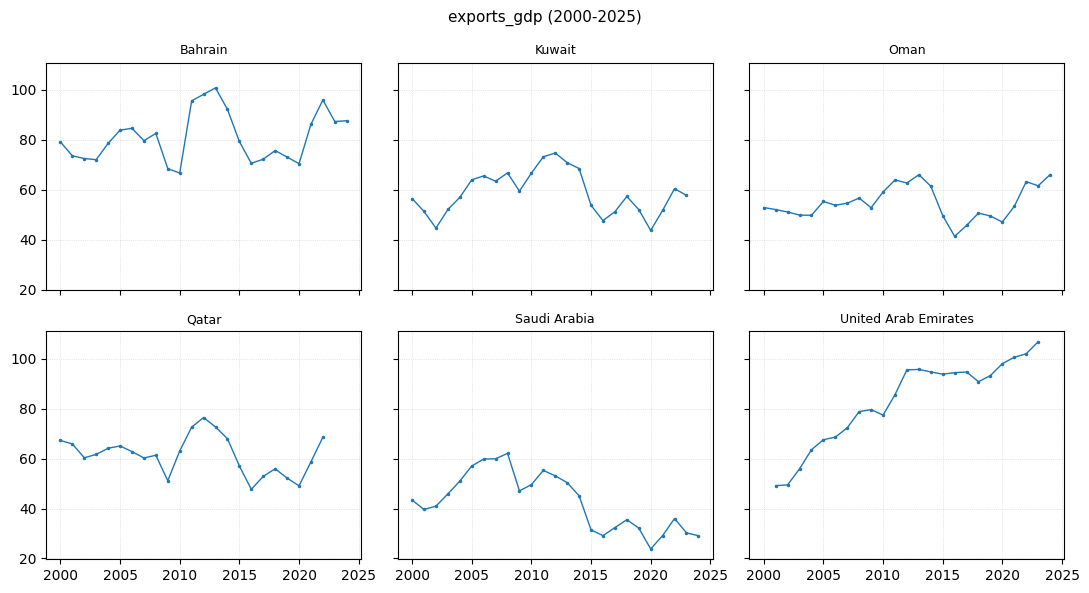

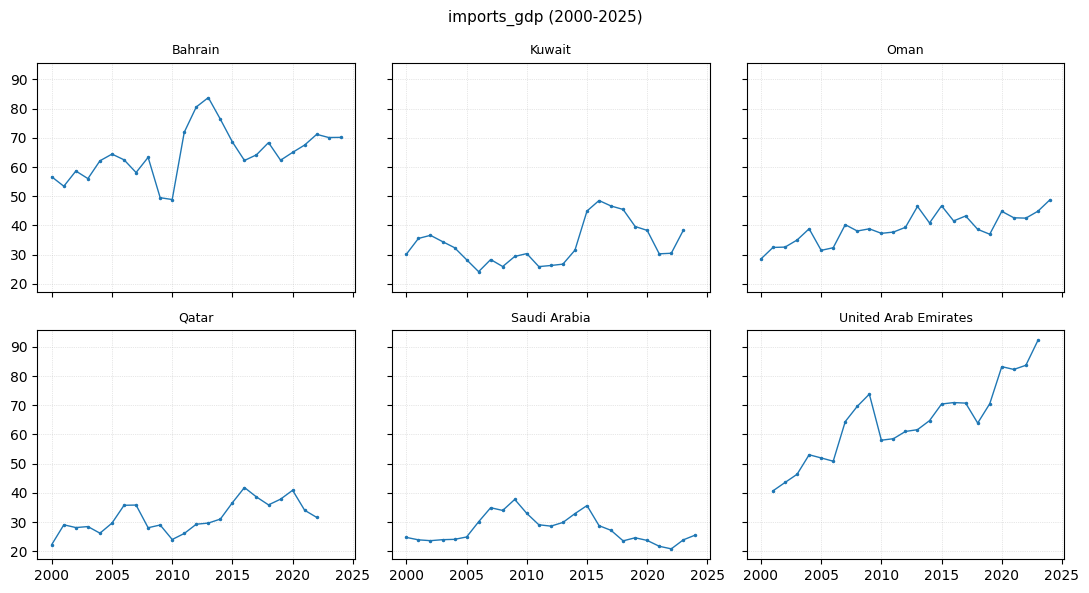

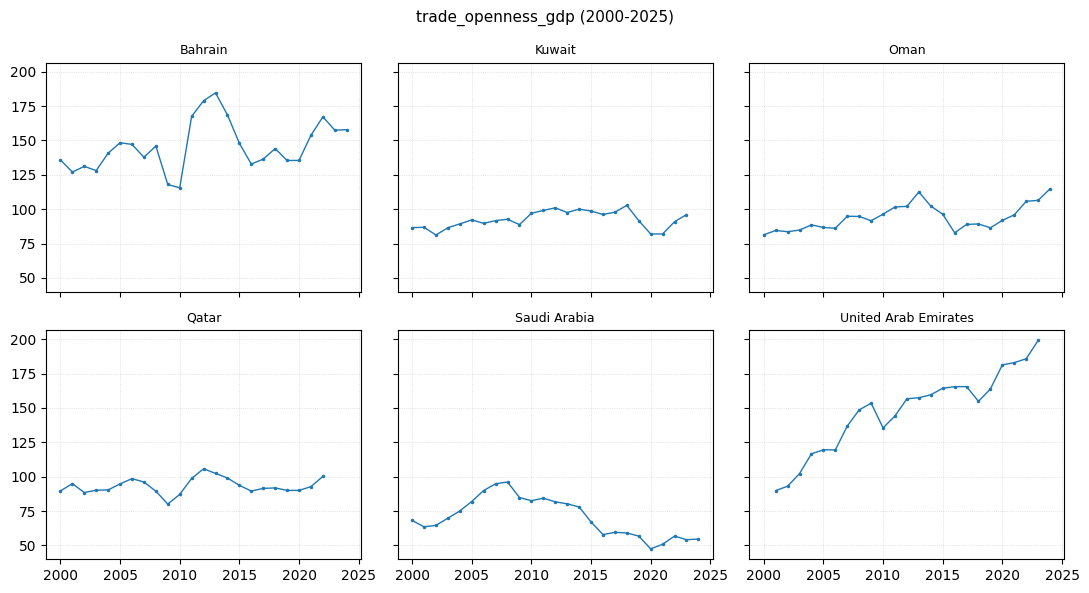

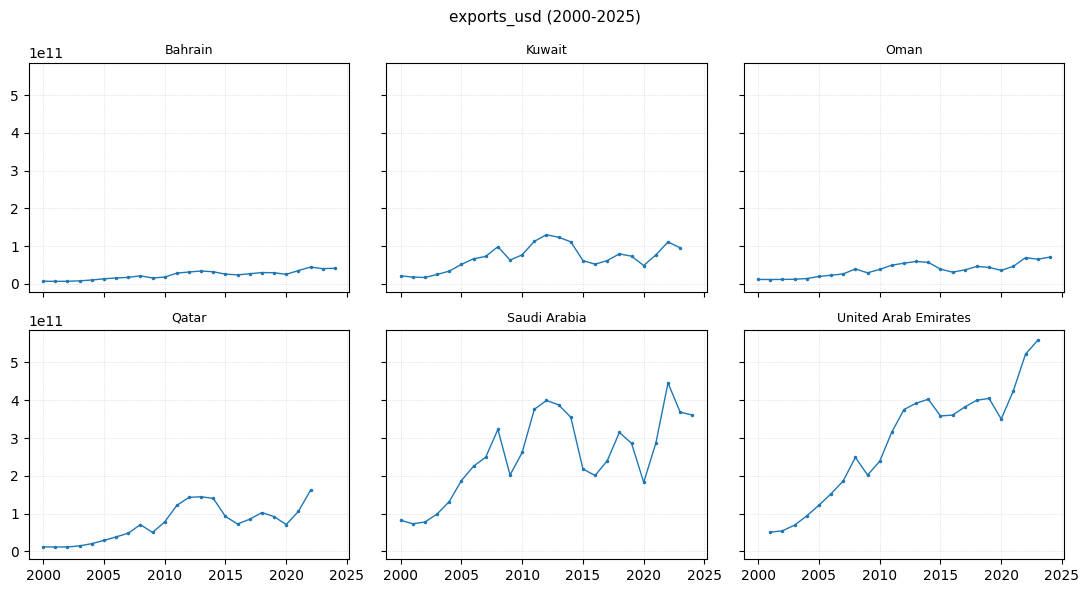

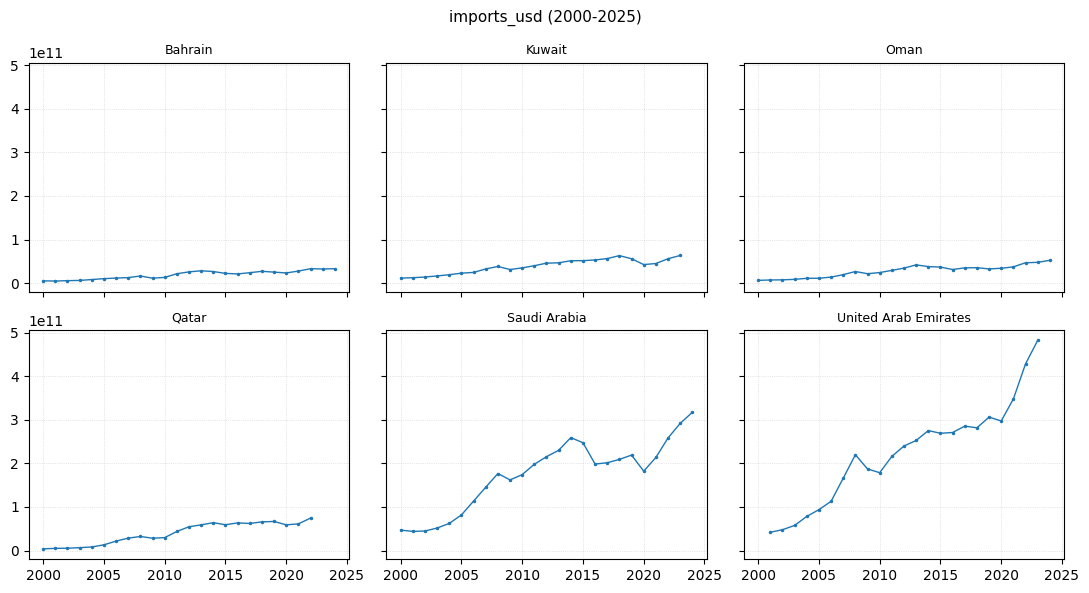

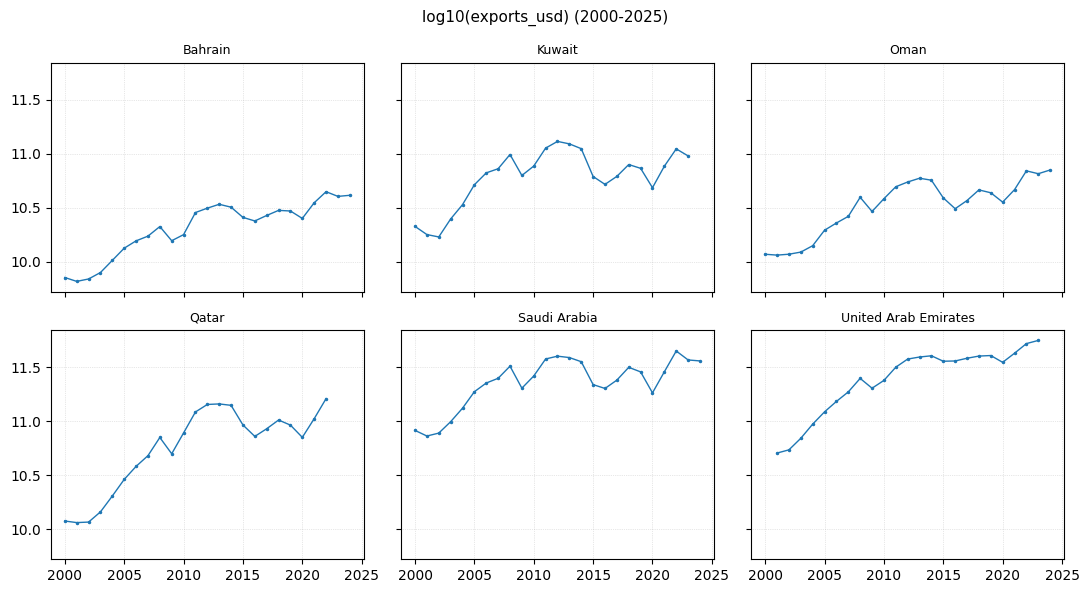

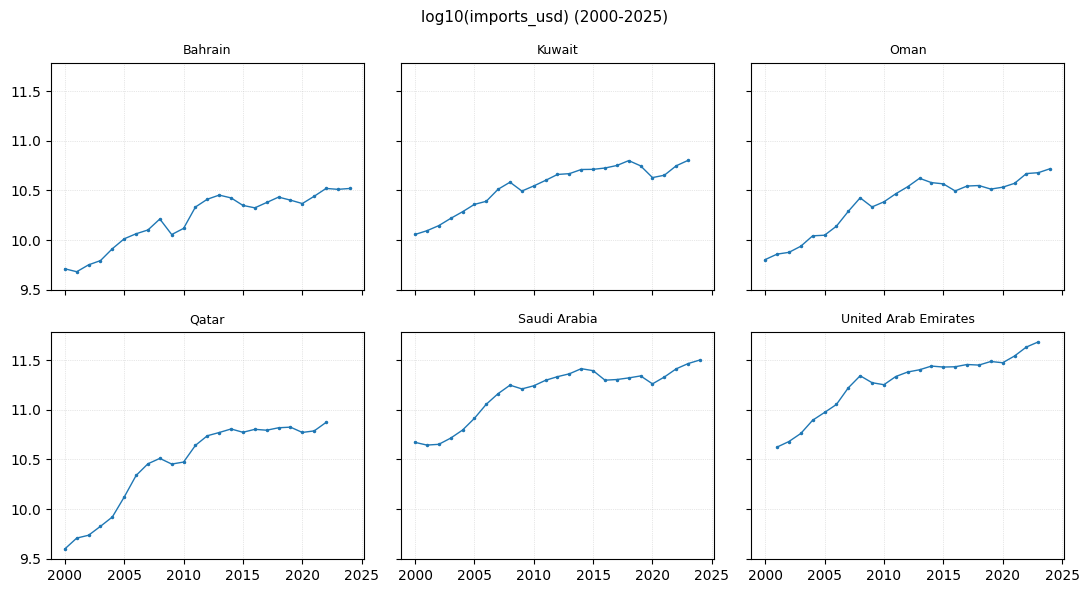

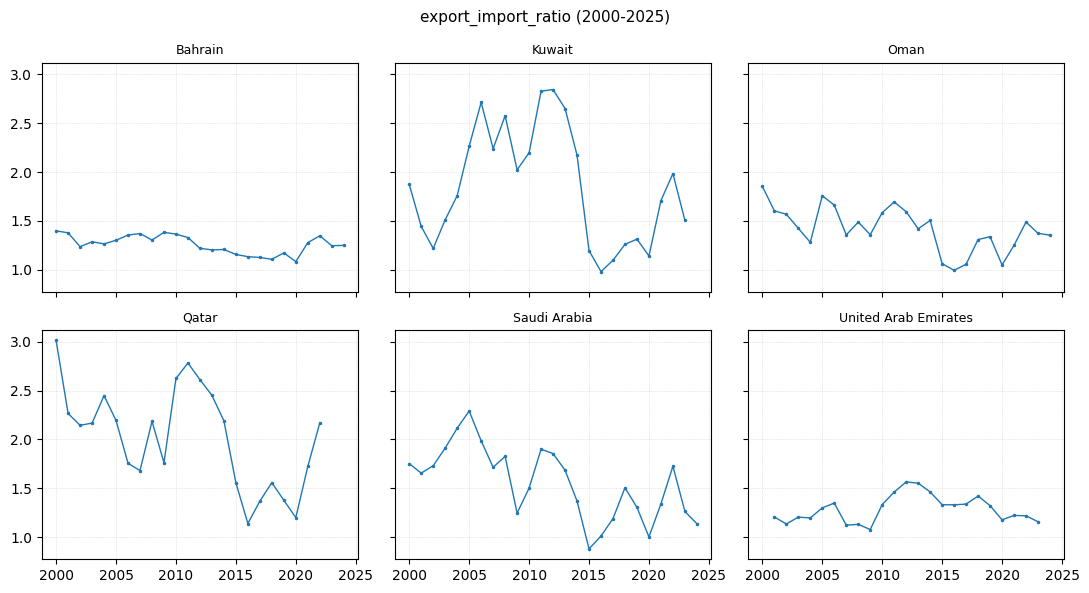

In [330]:
# UNCTAD export concentration + GDP context
line_by_country(macro_win, "export_concentration", suptitle=f"export_concentration ({YEAR_START}-{YEAR_END})")
line_by_country(macro_win, "gdp_per_capita", suptitle=f"gdp_per_capita ({YEAR_START}-{YEAR_END})")
macro_win_log = macro_win.assign(log10_gdp=np.log10(macro_win["gdp"].where(macro_win["gdp"] > 0)))
line_by_country(macro_win_log, "log10_gdp", suptitle=f"log10(gdp) ({YEAR_START}-{YEAR_END})")
line_by_country(macro_win, "gdp", suptitle=f"gdp ({YEAR_START}-{YEAR_END})")

# Trade structure (% GDP)
for col in cols_trade_shares:
    line_by_country(macro_win, col, suptitle=f"{col} ({YEAR_START}-{YEAR_END})")

# Trade scale context (USD raw first)
line_by_country(macro_win, "exports_usd", suptitle=f"exports_usd ({YEAR_START}-{YEAR_END})")
line_by_country(macro_win, "imports_usd", suptitle=f"imports_usd ({YEAR_START}-{YEAR_END})")

# Complementary readability view (log scale)
macro_win_trade = add_trade_derived(macro_win)
line_by_country(macro_win_trade, "log10_exports_usd", suptitle=f"log10(exports_usd) ({YEAR_START}-{YEAR_END})")
line_by_country(macro_win_trade, "log10_imports_usd", suptitle=f"log10(imports_usd) ({YEAR_START}-{YEAR_END})")
line_by_country(macro_win_trade, "export_import_ratio", suptitle=f"export_import_ratio ({YEAR_START}-{YEAR_END})")


In [331]:
_focus_cols = cols_shares + cols_trade_shares + ["export_concentration", "gdp_per_capita", "exports_usd", "imports_usd"]
_f = macro_win[_focus_cols]
print("Focus - shape:", _f.shape, "| pairwise-complete:", _f.dropna().shape)


Focus - shape: (156, 11) | pairwise-complete: (102, 11)


#### 3.1a Focus — correlation matrix


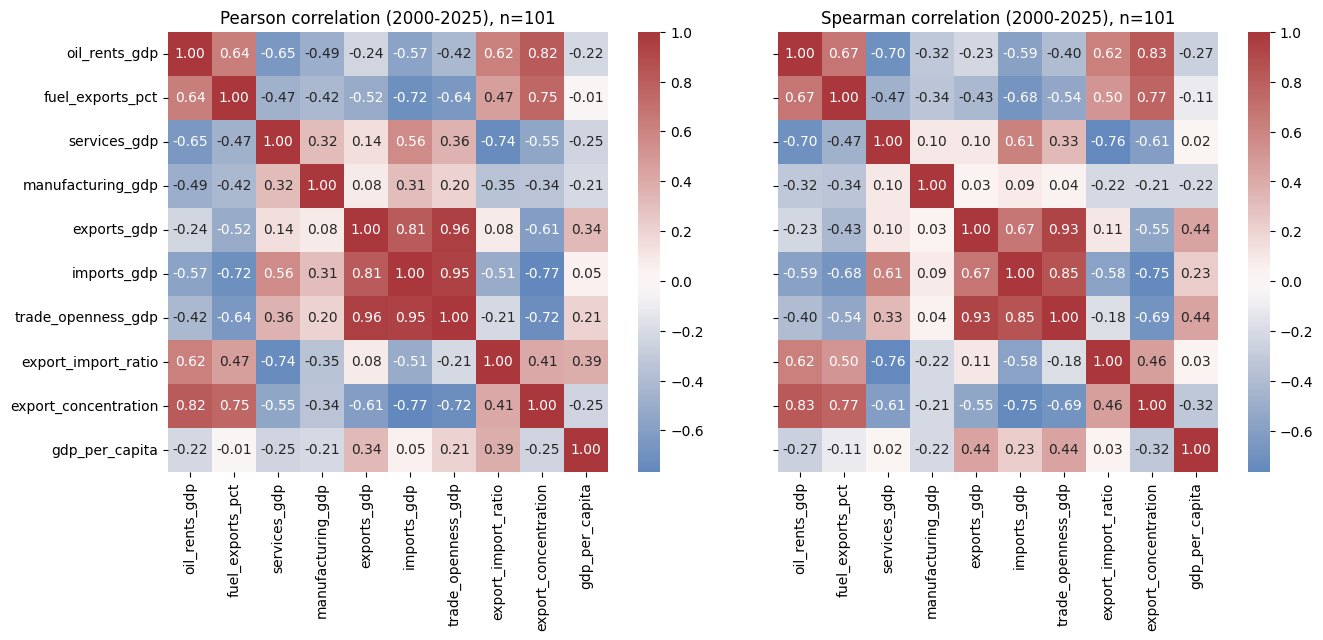

In [332]:
macro_corr = add_trade_derived(apply_fuel_mask_for_display(macro_win))
corr_cols = cols_shares + cols_trade_shares + ["export_import_ratio", "export_concentration", "gdp_per_capita"]
corr_df = macro_corr[corr_cols].dropna()
if len(corr_df) > 15:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
    sns.heatmap(
        corr_df.corr(method="pearson"),
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        square=True,
        ax=axes[0],
    )
    axes[0].set_title(f"Pearson correlation ({YEAR_START}-{YEAR_END}), n={len(corr_df)}")
    sns.heatmap(
        corr_df.corr(method="spearman"),
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        square=True,
        ax=axes[1],
    )
    axes[1].set_title(f"Spearman correlation ({YEAR_START}-{YEAR_END}), n={len(corr_df)}")
    plt.tight_layout()
    plt.show()
else:
    print(f"Too few complete rows for heatmap (n={len(corr_df)}).")


#### 3.1b Full span — line charts

Uses **`macro_win_full`** (`YEAR_FULL_START`-`YEAR_FULL_END` from the helpers cell).


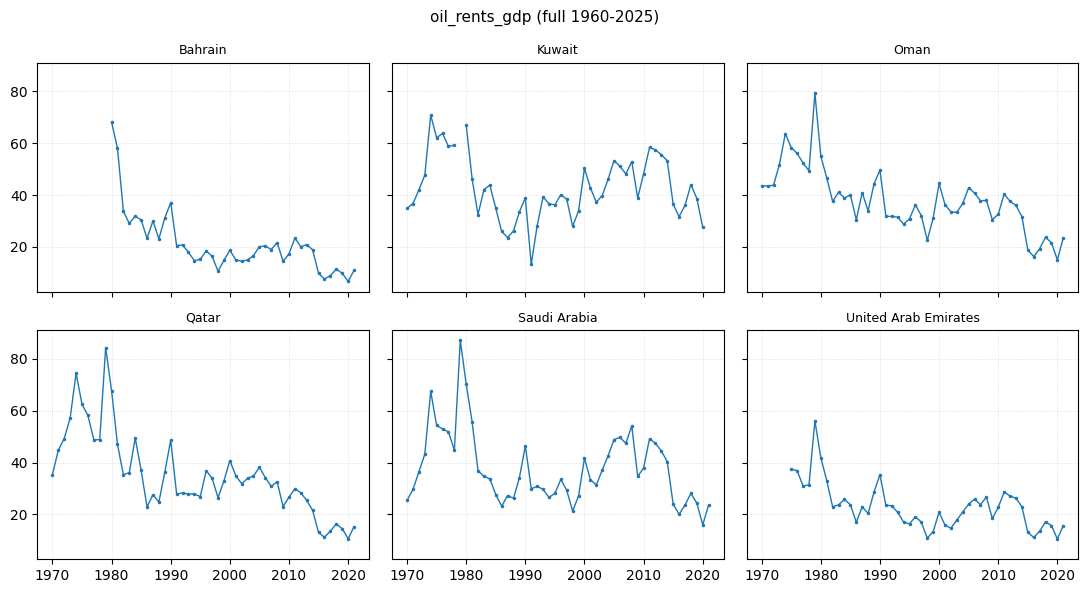

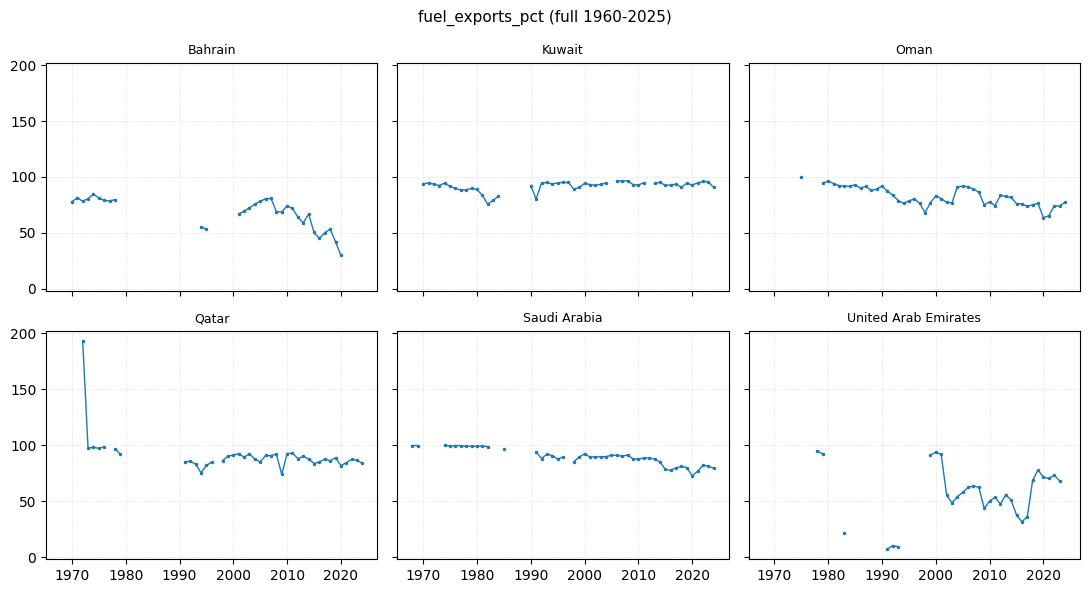

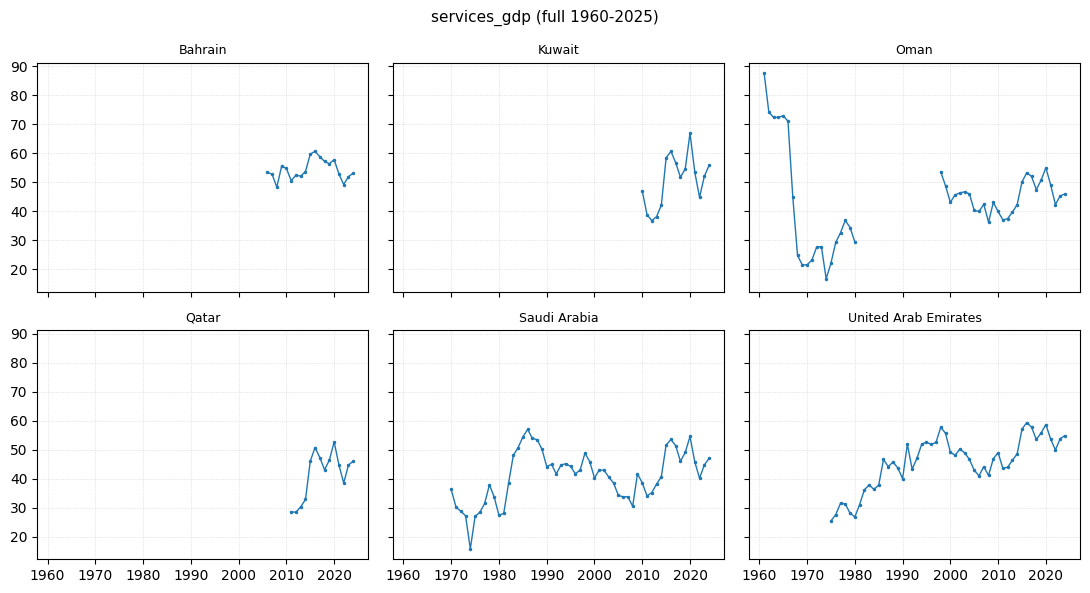

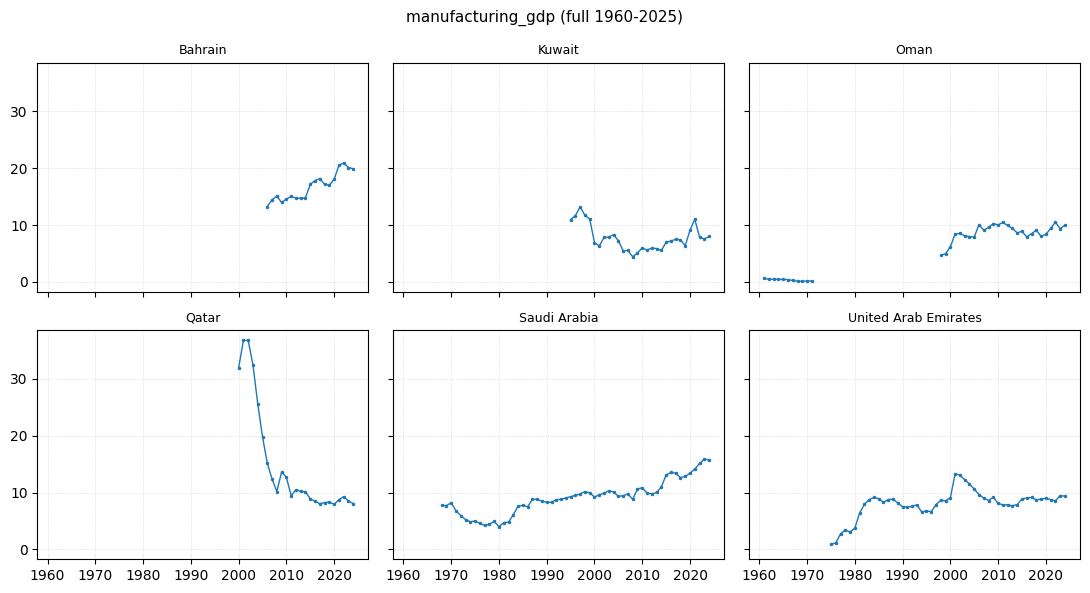

In [333]:
for col in cols_shares:
    df_plot = apply_fuel_mask_for_display(macro_win_full) if col == "fuel_exports_pct" else macro_win_full
    line_by_country(
        df_plot,
        col,
        suptitle=f"{col} (full {YEAR_FULL_START}-{YEAR_FULL_END})",
    )


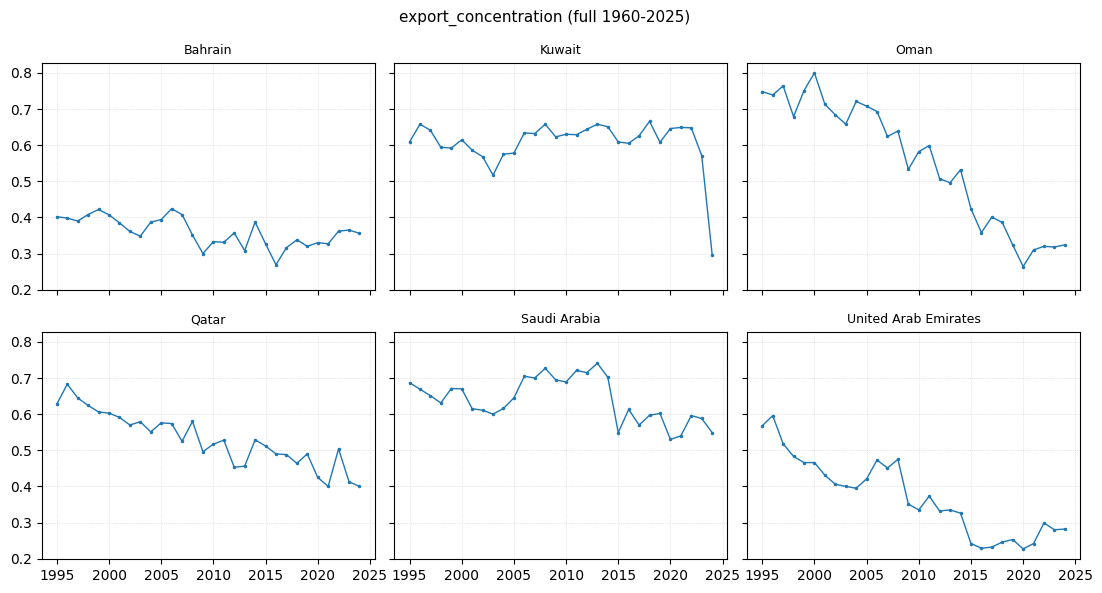

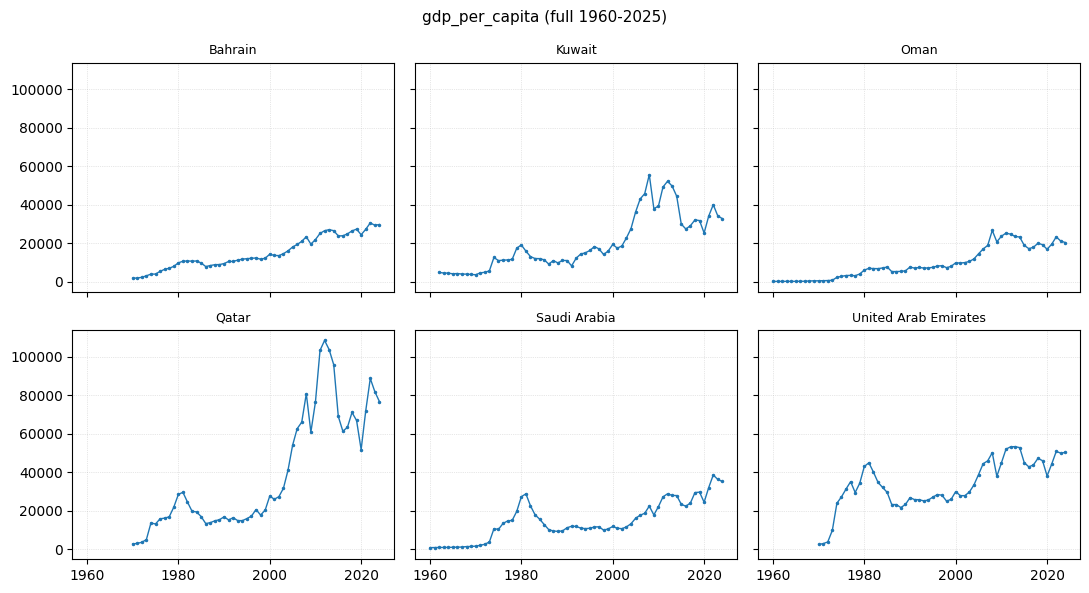

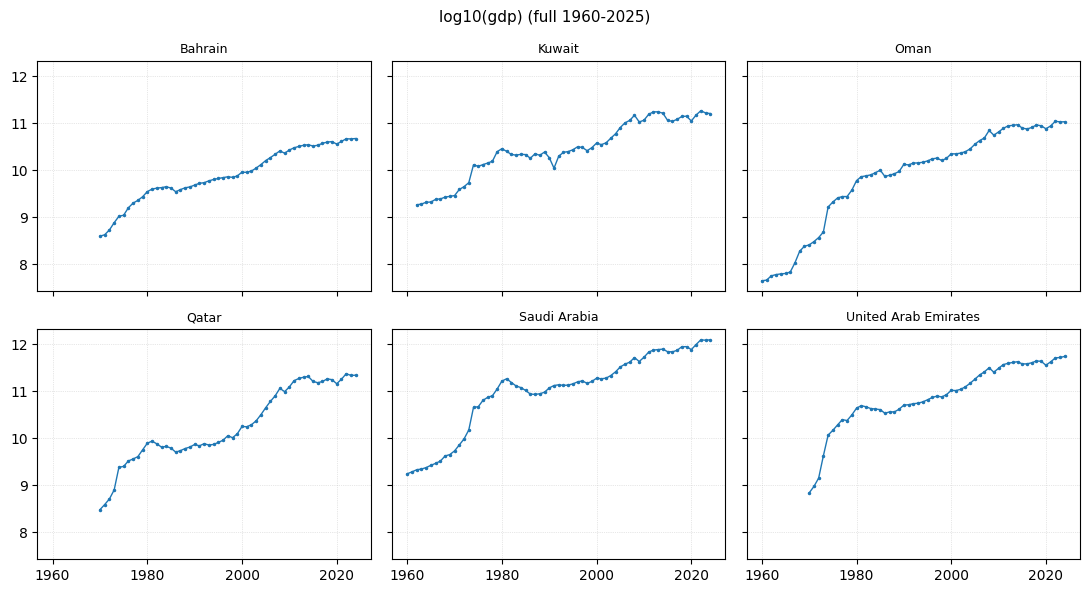

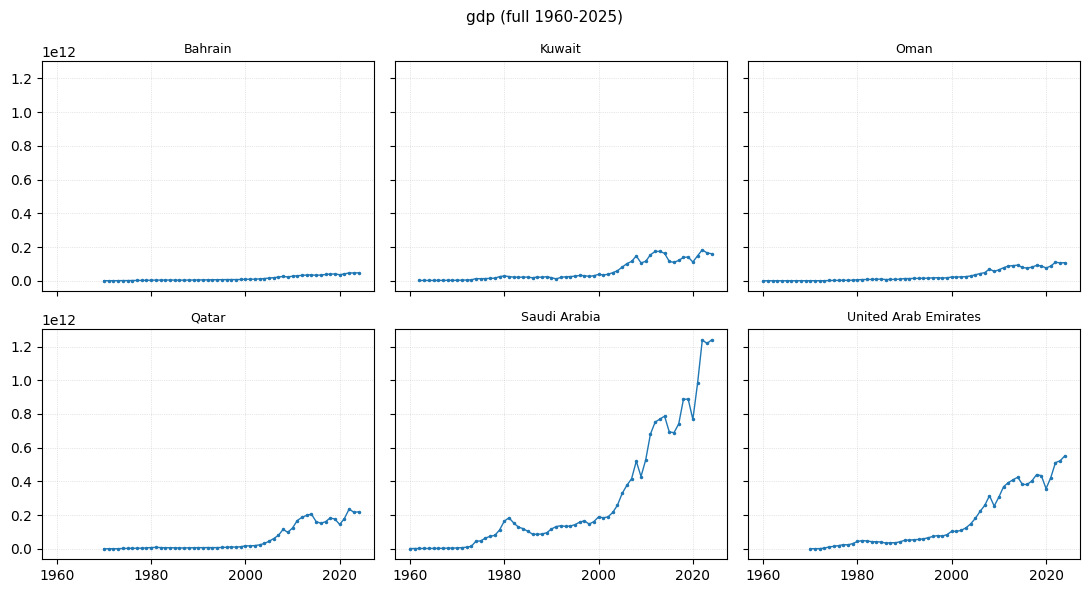

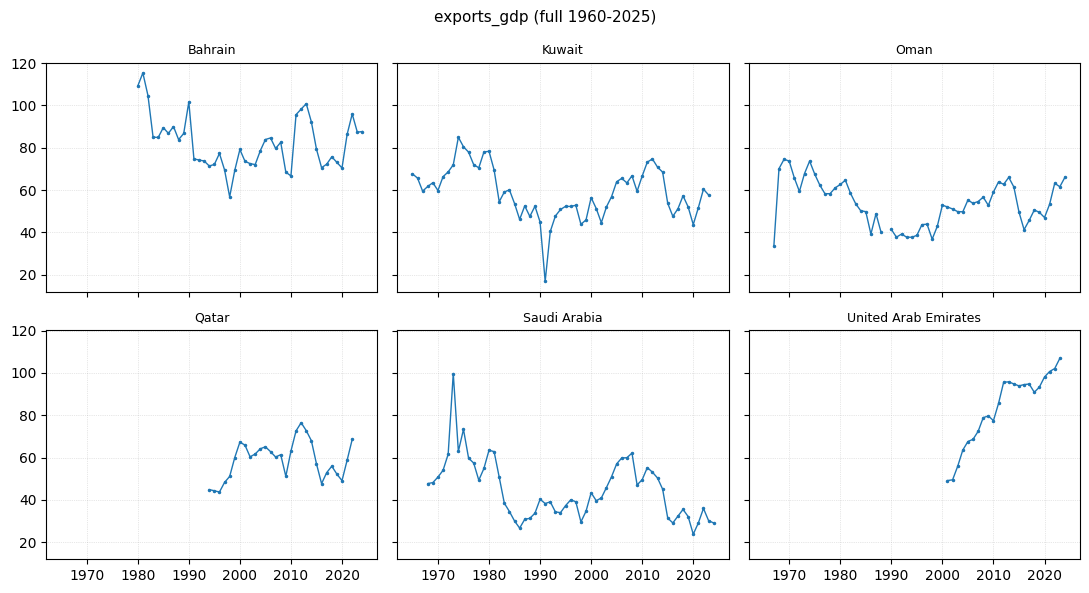

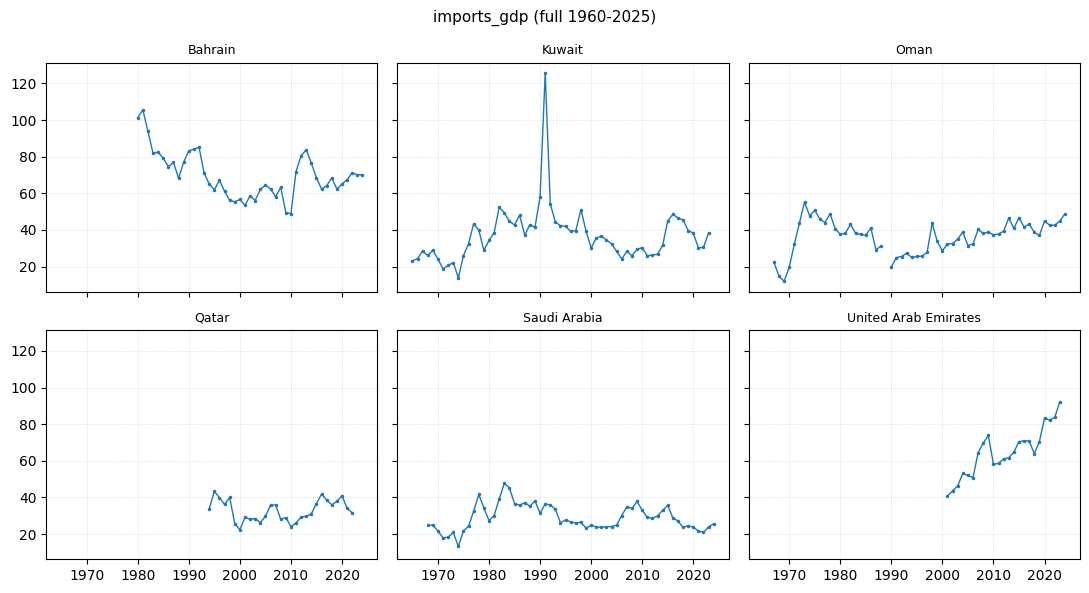

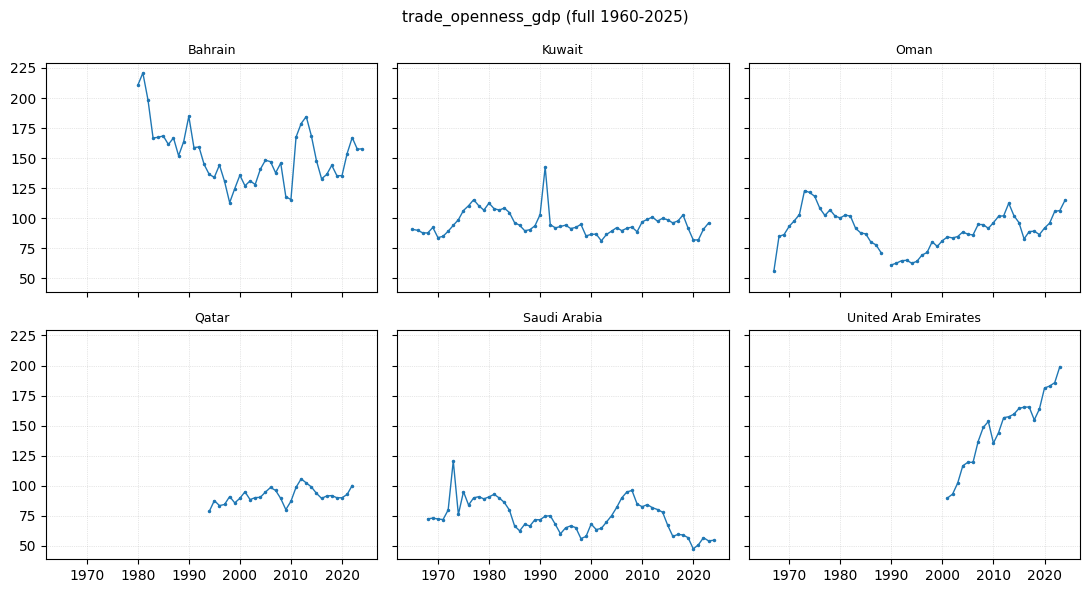

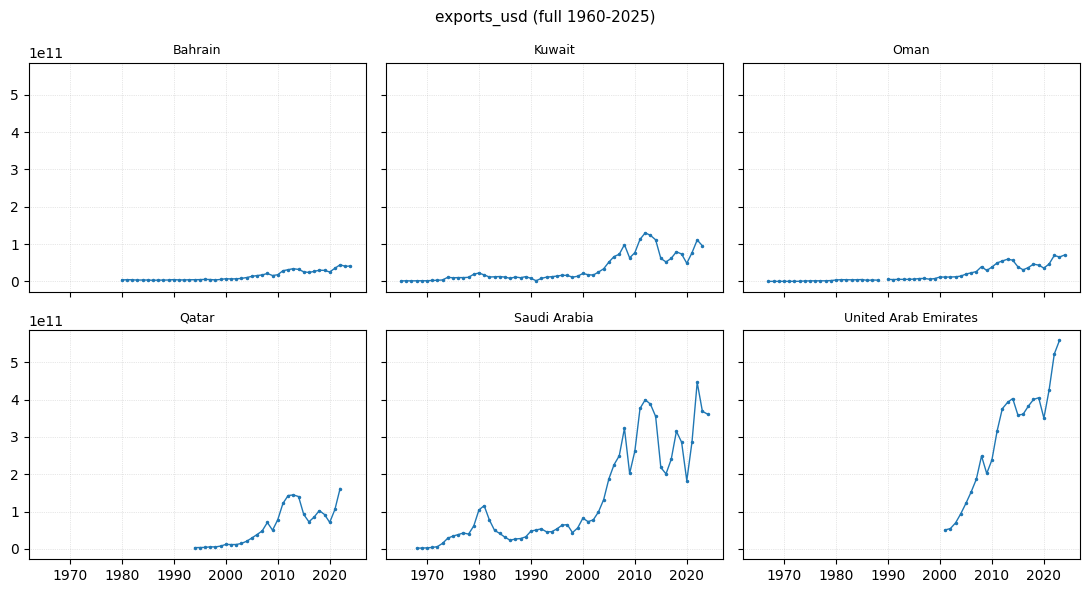

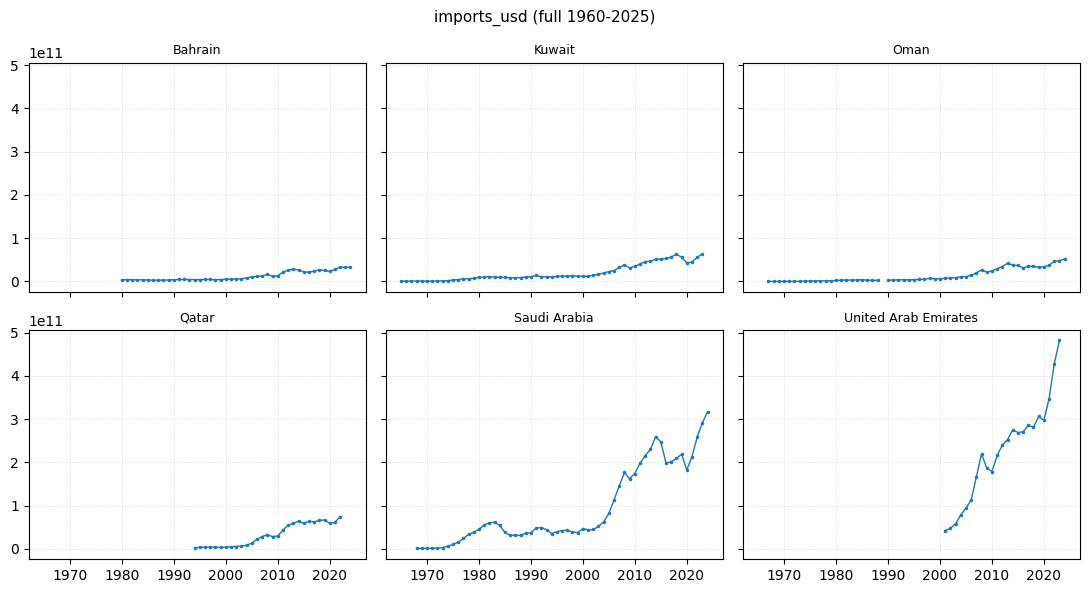

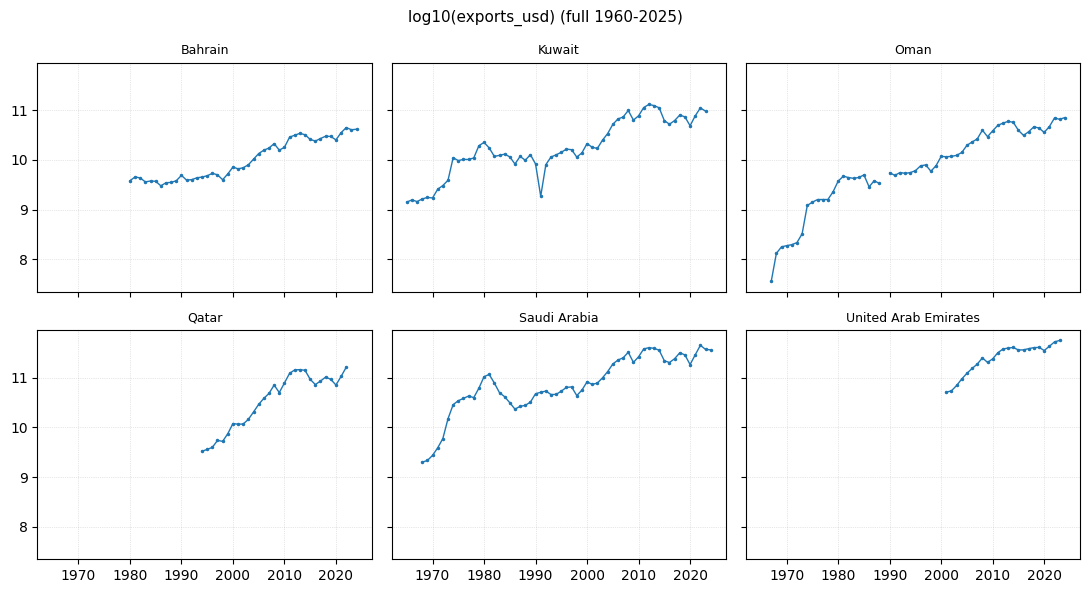

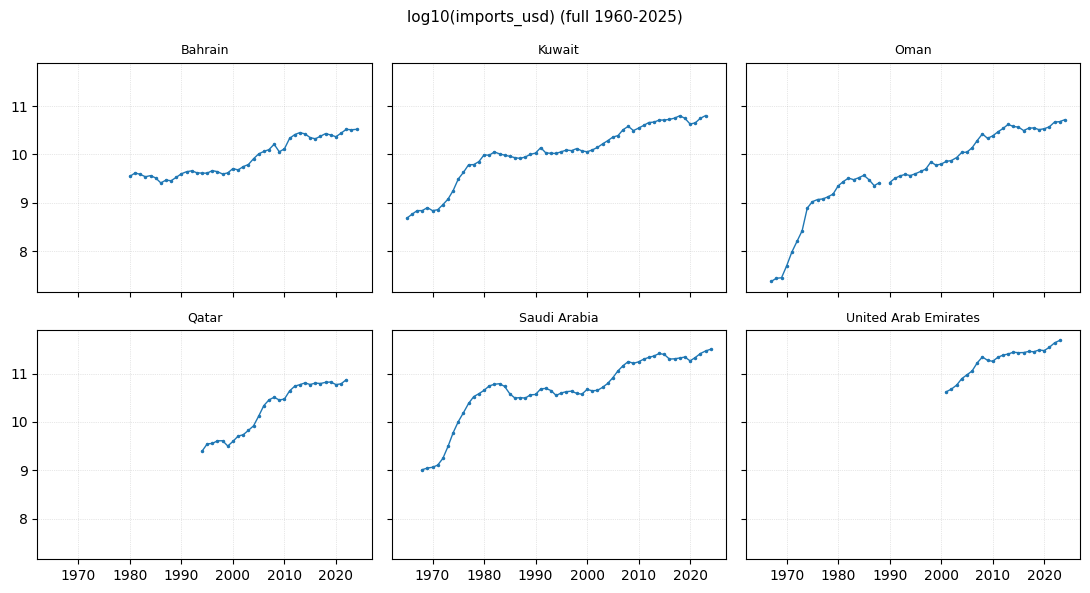

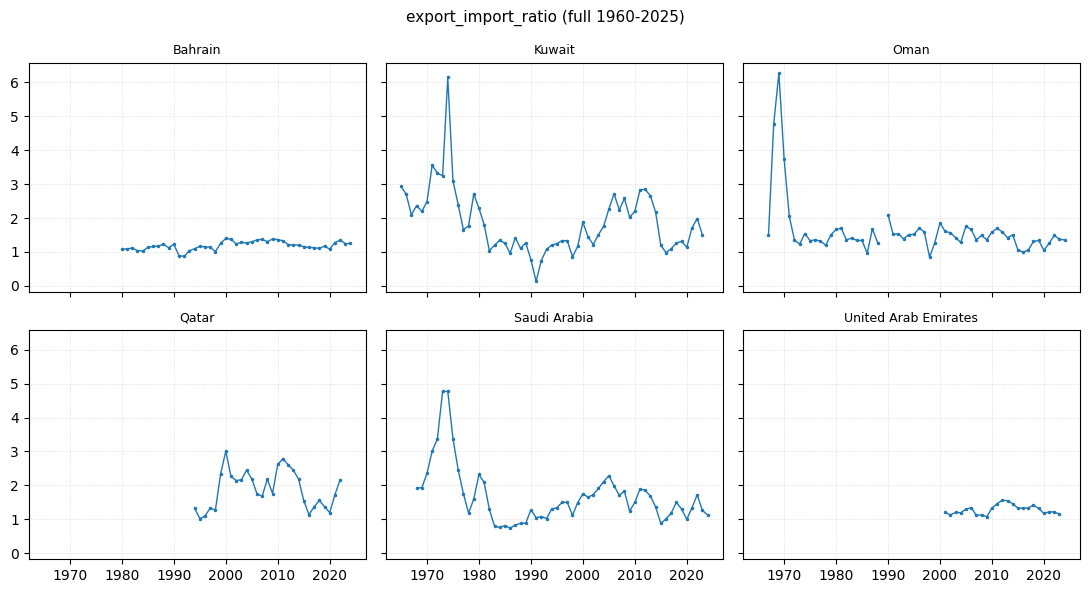

In [334]:
line_by_country(macro_win_full, "export_concentration", suptitle=f"export_concentration (full {YEAR_FULL_START}-{YEAR_FULL_END})")
line_by_country(macro_win_full, "gdp_per_capita", suptitle=f"gdp_per_capita (full {YEAR_FULL_START}-{YEAR_FULL_END})")
macro_full_log = macro_win_full.assign(log10_gdp=np.log10(macro_win_full["gdp"].where(macro_win_full["gdp"] > 0)))
line_by_country(macro_full_log, "log10_gdp", suptitle=f"log10(gdp) (full {YEAR_FULL_START}-{YEAR_FULL_END})")
line_by_country(macro_win_full, "gdp", suptitle=f"gdp (full {YEAR_FULL_START}-{YEAR_FULL_END})")

# Trade structure (% GDP)
for col in cols_trade_shares:
    line_by_country(macro_win_full, col, suptitle=f"{col} (full {YEAR_FULL_START}-{YEAR_FULL_END})")

# Trade scale context (USD raw first)
line_by_country(macro_win_full, "exports_usd", suptitle=f"exports_usd (full {YEAR_FULL_START}-{YEAR_FULL_END})")
line_by_country(macro_win_full, "imports_usd", suptitle=f"imports_usd (full {YEAR_FULL_START}-{YEAR_FULL_END})")

# Complementary readability view (log scale)
macro_full_trade = add_trade_derived(macro_win_full)
line_by_country(macro_full_trade, "log10_exports_usd", suptitle=f"log10(exports_usd) (full {YEAR_FULL_START}-{YEAR_FULL_END})")
line_by_country(macro_full_trade, "log10_imports_usd", suptitle=f"log10(imports_usd) (full {YEAR_FULL_START}-{YEAR_FULL_END})")
line_by_country(macro_full_trade, "export_import_ratio", suptitle=f"export_import_ratio (full {YEAR_FULL_START}-{YEAR_FULL_END})")


#### 3.1b Full span — correlation matrix

Same columns as 3.1a; own pairwise-complete **n**.


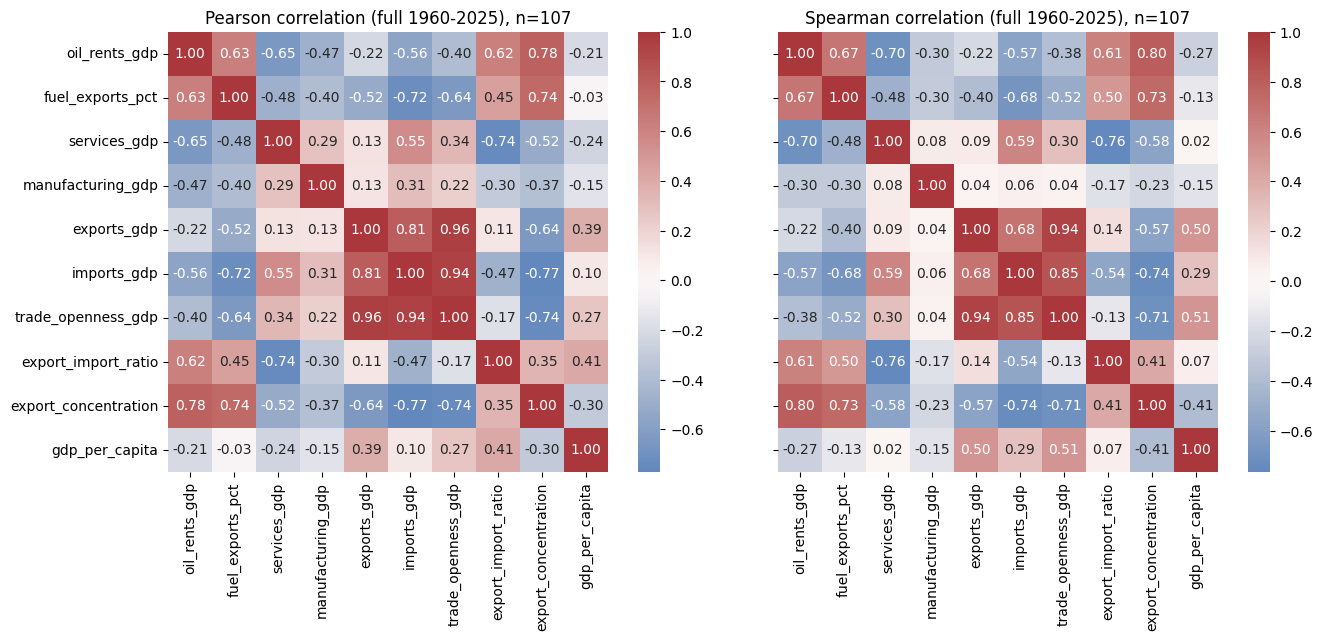

In [335]:
macro_corr_full = add_trade_derived(apply_fuel_mask_for_display(macro_win_full))
corr_cols = cols_shares + cols_trade_shares + ["export_import_ratio", "export_concentration", "gdp_per_capita"]
corr_df_full = macro_corr_full[corr_cols].dropna()
if len(corr_df_full) > 15:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
    sns.heatmap(
        corr_df_full.corr(method="pearson"),
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        square=True,
        ax=axes[0],
    )
    axes[0].set_title(f"Pearson correlation (full {YEAR_FULL_START}-{YEAR_FULL_END}), n={len(corr_df_full)}")
    sns.heatmap(
        corr_df_full.corr(method="spearman"),
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        square=True,
        ax=axes[1],
    )
    axes[1].set_title(f"Spearman correlation (full {YEAR_FULL_START}-{YEAR_FULL_END}), n={len(corr_df_full)}")
    plt.tight_layout()
    plt.show()
else:
    print("Too few complete rows for full-span heatmap:", len(corr_df_full))


#### 3.1c Tourism receipts (WDI) — focus window

**Why this view.** International tourism receipts directly probe a *non-hydrocarbon* export channel that is increasingly central in GCC narratives (Vision 2030, UAE post-oil pivot, Bahrain services hub).

**Two indicators (paired view).**
- `tourism_receipts_pct_exports` — share of total exports coming from international tourism (**diversification angle**).
- `tourism_receipts_usd` — absolute receipts in current US$ (**scale angle**, plotted on log10 for readability).

**Coverage caveats (must read alongside the charts).**
- **United Arab Emirates** has only the **USD level** series in this WDI extract; the **% of exports** series is fully missing in WDI for UAE. To keep UAE visible on the share chart, we use a **derived effective share** `tourism_pct_exports_eff = tourism_receipts_usd / exports_usd × 100` whenever `tourism_receipts_pct_exports` is missing — clearly labeled and consistent with the cross-block lens in §3.4.
- **Qatar** and **Saudi Arabia** have shorter coverage on the % series (Qatar from ~2011, Saudi Arabia mostly 2010-2020).
- **All countries** end around **2020-2023** in this extract — no GCC tourism values for **2025**.
- Series reflects published WDI revisions; pandemic year **2020** is a strong negative outlier in most series.

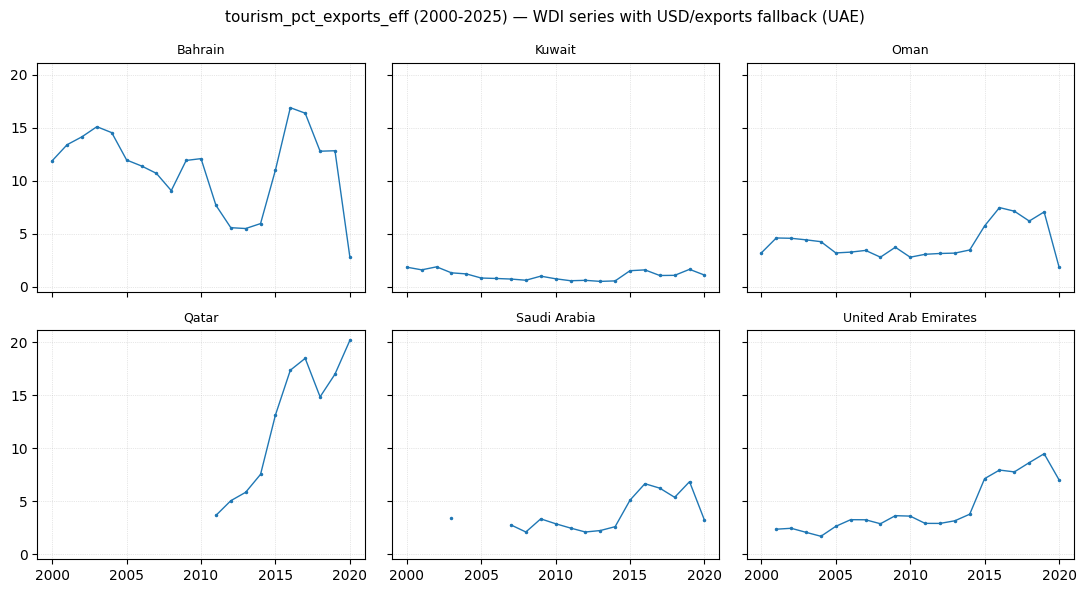

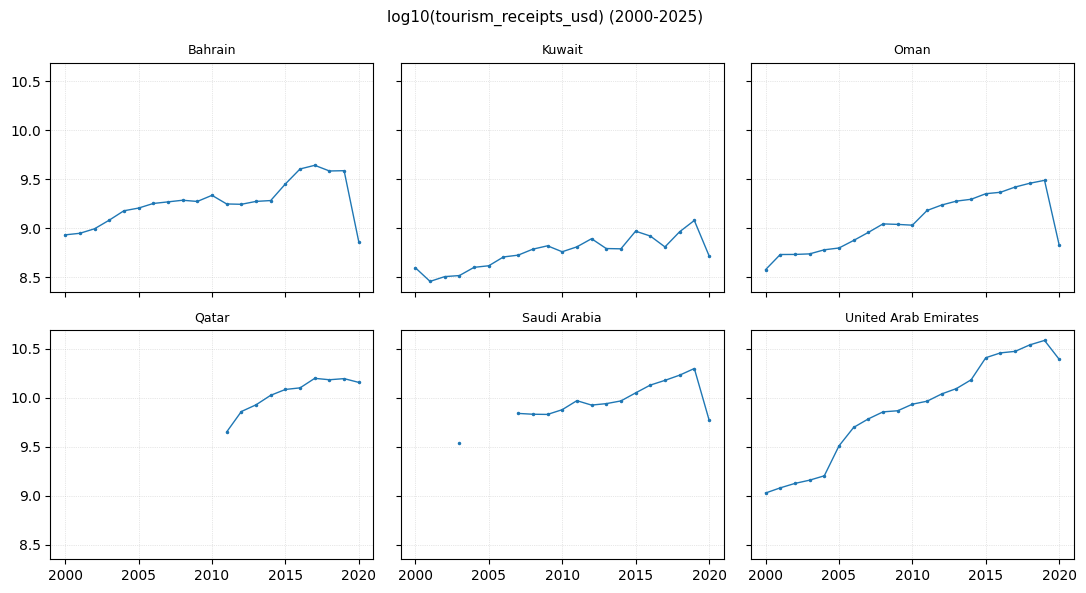

Tourism coverage / latest available value by country (focus window):


,years_with_pct,last_year_pct,last_pct,years_with_usd,last_year_usd,last_usd
country,,,,,,
Bahrain,21,2020.0,2.819280,21,2020,7.240000e+08
Kuwait,21,2020.0,1.105103,21,2020,5.240000e+08
Oman,21,2020.0,1.874404,21,2020,6.690000e+08
Qatar,10,2020.0,20.185176,10,2020,1.431800e+10
Saudi Arabia,15,2020.0,3.223965,15,2020,5.960000e+09
United Arab Emirates,0,NaN,NaN,21,2020,2.461540e+10


In [336]:
# §3.1c — Tourism receipts trajectories (focus window)

tourism_view = macro_win.copy()
tourism_view["log10_tourism_usd"] = np.log10(
    tourism_view["tourism_receipts_usd"].where(tourism_view["tourism_receipts_usd"] > 0)
)

# Derived effective share: WDI series first, USD/exports fallback when missing (e.g. UAE).
tourism_view["tourism_pct_exports_eff"] = tourism_view["tourism_receipts_pct_exports"]
_fallback = (
    tourism_view["tourism_pct_exports_eff"].isna()
    & tourism_view["tourism_receipts_usd"].notna()
    & tourism_view["exports_usd"].notna()
    & (tourism_view["exports_usd"] > 0)
)
tourism_view.loc[_fallback, "tourism_pct_exports_eff"] = (
    tourism_view.loc[_fallback, "tourism_receipts_usd"]
    / tourism_view.loc[_fallback, "exports_usd"]
    * 100.0
)

line_by_country(
    tourism_view,
    "tourism_pct_exports_eff",
    suptitle=f"tourism_pct_exports_eff ({YEAR_START}-{YEAR_END}) — WDI series with USD/exports fallback (UAE)",
)

line_by_country(
    tourism_view,
    "log10_tourism_usd",
    suptitle=f"log10(tourism_receipts_usd) ({YEAR_START}-{YEAR_END})",
)

# Quick numeric summary by country for the focus window
tourism_summary = (
    tourism_view.groupby("country")
    .agg(
        years_with_pct=("tourism_receipts_pct_exports", lambda s: int(s.notna().sum())),
        last_year_pct=(
            "tourism_receipts_pct_exports",
            lambda s: int(tourism_view.loc[s.dropna().index, "year"].max()) if s.notna().any() else None,
        ),
        last_pct=("tourism_receipts_pct_exports", lambda s: float(s.dropna().iloc[-1]) if s.notna().any() else None),
        years_with_usd=("tourism_receipts_usd", lambda s: int(s.notna().sum())),
        last_year_usd=(
            "tourism_receipts_usd",
            lambda s: int(tourism_view.loc[s.dropna().index, "year"].max()) if s.notna().any() else None,
        ),
        last_usd=("tourism_receipts_usd", lambda s: float(s.dropna().iloc[-1]) if s.notna().any() else None),
    )
)
print("Tourism coverage / latest available value by country (focus window):")
display(tourism_summary)

### 3.1 Summary — Block A (Macro/UNCTAD): Sharp takeaways

**Transition signal from structure, not income alone.** GCC countries with lower export concentration and broader trade integration generally look closer to a transition-ready profile than peers with concentrated export baskets.

**Country pattern is stable.** Cross-country gaps are larger than short-run year-to-year movements in the focus window, so the current picture is mostly structural rather than cyclical.

**Policy reading.** In a PostOil framing, reducing concentration risk and improving tradable-sector depth is at least as important as growing aggregate GDP.

**Tourism receipts (§3.1c).** Adds a non-hydrocarbon export angle to Block A.

- **Effective share of exports** (`tourism_pct_exports_eff`, WDI + USD/exports fallback for UAE): **Bahrain** is structurally high but volatile (10–17% in 2000s, dropping to ~3% in 2020); **Qatar** shows the **most dramatic climb** (≈3.6% in 2011 → ~20% in 2020); **Saudi Arabia** ramps gradually from ~2% to ~7% over 2010–2019; **Oman** sits 3–7%; **Kuwait** is structurally **lowest** (~1%); **UAE** with the derived series stays around 5–8%.
- **Absolute USD level** (log10): all GCC trend upward with a sharp **2020 pandemic dip**. **UAE is the clear leader in absolute receipts** (~38 B$ peak), an order of magnitude above Bahrain (~4 B$); **Saudi Arabia** is second in level, **Qatar** rises strongly, **Oman/Bahrain/Kuwait** stay smaller in scale.
- Series ends around 2020–2023 in this WDI extract (no 2025 value for any GCC country).

**Correlation panels.** Heatmaps show **Pearson** (linear association) and **Spearman** (rank / monotone association) side by side on the same columns and sample size. Variables are **Block A macro / trade / UNCTAD fields only** — the GII (`innovation_index`) is analyzed in **§3.2** and in cross-block views.

**Limits.** Correlations are descriptive, windows are short for some series, and missingness differs by indicator.


### 3.2 Block B — Innovation (WIPO Global Innovation Index)

**Source:** GII technical dataset (2025 edition in this extract). **Variables:** `innovation_index` (score) and `innovation_rank` (lower = better).

**What the 2025 score is:** The **2025 Global Innovation Index** value is a **composite** built from the **most recent available inputs**, **mainly covering 2022–2024**, not a single calendar-year measurement. The **`year`** column in the merged panel reflects the **report edition** (here aligned with **2025**), not a claim that the headline score equals “innovation in 2025” like an annual national account.

**This block:** (1) table of available scores/ranks, (2) **horizontal bar chart** of scores by country, (3) **rank vs score** sanity plot, (4) **optional exploratory scatter** linking GII to **2023** `gdp_per_capita` and **`export_concentration`** as **context only** (different years and concepts — captions on the figures; **not causal** with **n = 6**).


In [337]:
gii = innovation_panel.dropna(subset=["innovation_index"]).copy()
if gii.empty:
    gii_year = None
    print("No innovation_index rows in innovation_panel — check merged_dataset.csv")
else:
    gii_year = int(gii["year"].iloc[0])
    display_cols = ["country", "year", "innovation_index", "innovation_rank"]
    display(gii[display_cols].sort_values("innovation_rank"))
    print("GII edition year in panel:", gii_year)



,country,year,innovation_index,innovation_rank
363,United Arab Emirates,2025,44.154489,30.0
307,Saudi Arabia,2025,36.044819,46.0
241,Qatar,2025,34.561768,48.0
55,Bahrain,2025,30.015766,62.0
185,Oman,2025,28.649098,69.0
119,Kuwait,2025,28.214302,73.0


GII edition year in panel: 2025


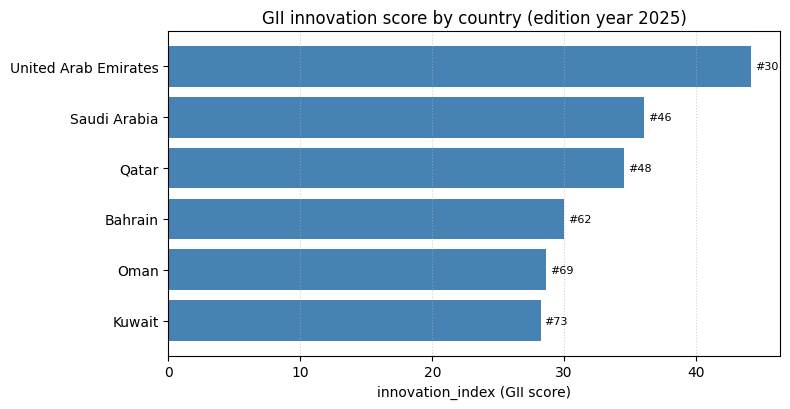

In [338]:
if not gii.empty:
    fig, ax = plt.subplots(figsize=(8, 4.2))
    gg = gii.sort_values("innovation_index")
    ax.barh(gg["country"], gg["innovation_index"], color="steelblue")
    for i, (_, r) in enumerate(gg.iterrows()):
        ax.text(r["innovation_index"] + 0.3, i, f"#{int(r['innovation_rank'])}", va="center", fontsize=8)
    ax.set_xlabel("innovation_index (GII score)")
    ax.set_title(f"GII innovation score by country (edition year {gii_year})")
    ax.grid(True, axis="x", ls=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


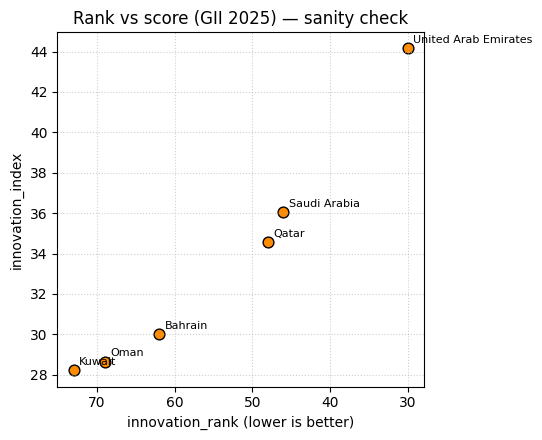

In [339]:
if not gii.empty:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.scatter(gii["innovation_rank"], gii["innovation_index"], s=60, color="darkorange", edgecolor="k")
    for _, r in gii.iterrows():
        ax.annotate(r["country"], (r["innovation_rank"], r["innovation_index"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.invert_xaxis()
    ax.set_xlabel("innovation_rank (lower is better)")
    ax.set_ylabel("innovation_index")
    ax.set_title(f"Rank vs score (GII {gii_year}) — sanity check")
    ax.grid(True, ls=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


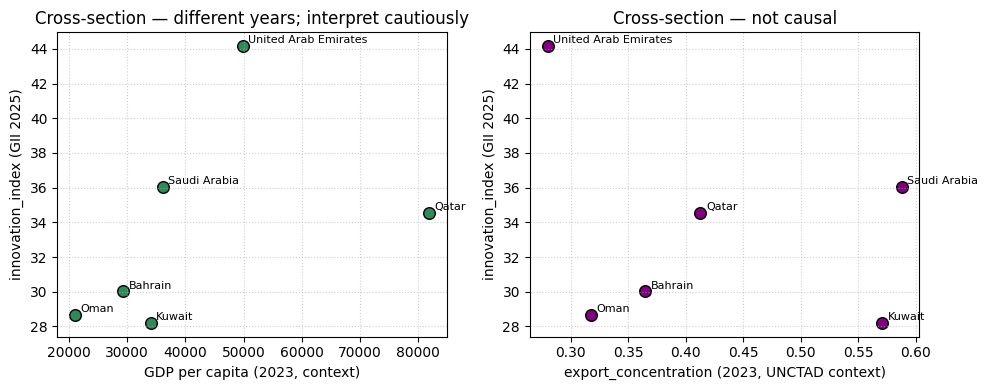

In [340]:
# Exploratory only: GII edition vs 2023 macro context (not same-year causal claim)
if not gii.empty:
    ctx = data[data["year"] == 2023][["country", "gdp_per_capita", "export_concentration"]].rename(
        columns={"gdp_per_capita": "gdp_pc_2023", "export_concentration": "expconc_2023"}
    )
    mb = gii.merge(ctx, on="country", how="left")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].scatter(mb["gdp_pc_2023"], mb["innovation_index"], s=70, color="seagreen", edgecolor="k")
    for _, r in mb.iterrows():
        axes[0].annotate(r["country"], (r["gdp_pc_2023"], r["innovation_index"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
    axes[0].set_xlabel("GDP per capita (2023, context)")
    axes[0].set_ylabel(f"innovation_index (GII {gii_year})")
    axes[0].set_title("Cross-section — different years; interpret cautiously")
    axes[0].grid(True, ls=":", alpha=0.6)

    axes[1].scatter(mb["expconc_2023"], mb["innovation_index"], s=70, color="purple", edgecolor="k")
    for _, r in mb.iterrows():
        axes[1].annotate(r["country"], (r["expconc_2023"], r["innovation_index"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
    axes[1].set_xlabel("export_concentration (2023, UNCTAD context)")
    axes[1].set_ylabel(f"innovation_index (GII {gii_year})")
    axes[1].set_title("Cross-section — not causal")
    axes[1].grid(True, ls=":", alpha=0.6)

    plt.tight_layout()
    plt.show()


### 3.2 Summary — Block B (GII): Sharp takeaways

**Innovation leaders are clear.** The GCC innovation ranking is not flat: UAE and Saudi Arabia sit at the top, while others cluster in a middle/lower tier.

**Interpretation matters.** GII is a composite index (2025 edition in this extract), so it should be read as system performance, not as a single-year flow outcome.

**Transition reading.** Stronger innovation performance is consistent with countries that combine capability building and diversification momentum.

**Limits.** Single-edition cross-section here; no causal claim or trend identification from this block alone.



### 3.3 Block C — AI readiness (Oxford Insights)

**Headline score (plots):** Bar length uses the **row-mean of pillar scores**—2023–24: mean of the three legacy pillars; 2025: mean of the six 2025 pillars—applied consistently across editions.

**Scope:** AI readiness source only (Oxford extract). No cross-block synthesis plots here.

**What exists in this extract:**
- **2023–24:** `ai_readiness` equals the mean of the **three legacy pillars** (government / technology sector / data infrastructure) in this CSV.
- **2025:** `ai_readiness` / `total_score` is **blank** in `ai_readiness.csv`, but the **same rule** applies: headline-style bar uses the **mean of the six 2025 pillars**; **`#rank`** is shown when present.

**Plotting rule:** horizontal bar = **pillar mean score** on x; **`#global_rank`** next to the bar when the rank column exists.


In [341]:
ai = ai_panel.copy()
ai_cols_any = COLS_AI_HEADLINE + COLS_AI_PILLARS
ai = ai[ai[ai_cols_any].notna().any(axis=1)].copy()

if ai.empty:
    ai_2023 = pd.DataFrame()
    ai_2024 = pd.DataFrame()
    ai_2025 = pd.DataFrame()
    print("No AI readiness rows in ai_panel — check merged_dataset.csv")
else:
    ai["year"] = ai["year"].astype(int)
    ai_2023 = ai[ai["year"] == 2023].copy()
    ai_2024 = ai[ai["year"] == 2024].copy()
    ai_2025 = ai[ai["year"] == 2025].copy()

    print("AI rows by year:")
    print(ai.groupby("year")["country"].count())

    if not ai_2024.empty:
        display(ai_2024[[
            "country", "year", "ai_readiness",
            "government_pillar", "technology_sector_pillar", "data_infrastructure_pillar",
        ]].sort_values("ai_readiness", ascending=False))

    if not ai_2023.empty:
        display(ai_2023[[
            "country", "year", "ai_readiness", "ai_readiness_rank",
            "government_pillar", "technology_sector_pillar", "data_infrastructure_pillar",
        ]].sort_values("ai_readiness_rank"))

    if not ai_2025.empty:
        display(ai_2025[[
            "country", "year", "ai_readiness_rank",
            "policy_capacity", "ai_infrastructure", "governance",
            "public_sector_adoption", "development_diffusion", "resilience",
        ]].sort_values("ai_readiness_rank"))

# Pillar groups by Oxford report vintage (row-mean recovers `ai_readiness` for 2023–24 in this extract)
LEGACY_AI_PILLARS = ["government_pillar", "technology_sector_pillar", "data_infrastructure_pillar"]
PILLARS_2025_AI = [
    "policy_capacity", "ai_infrastructure", "governance",
    "public_sector_adoption", "development_diffusion", "resilience",
]


AI rows by year:
year
2023    6
2024    6
2025    6
Name: country, dtype: int64


,country,year,ai_readiness,government_pillar,technology_sector_pillar,data_infrastructure_pillar
362,United Arab Emirates,2024,75.66,83.89,59.20,83.89
306,Saudi Arabia,2024,72.36,80.72,52.92,83.43
240,Qatar,2024,68.22,76.07,46.90,81.69
184,Oman,2024,62.91,69.61,41.29,77.84
54,Bahrain,2024,54.33,45.62,37.61,79.76
118,Kuwait,2024,51.26,46.49,36.93,70.36


,country,year,ai_readiness,ai_readiness_rank,government_pillar,technology_sector_pillar,data_infrastructure_pillar
361,United Arab Emirates,2023,70.42,18.0,78.32,56.67,76.28
305,Saudi Arabia,2023,67.04,29.0,78.71,49.59,72.83
239,Qatar,2023,63.59,34.0,69.64,44.31,76.81
183,Oman,2023,58.94,50.0,69.35,37.71,69.76
53,Bahrain,2023,56.13,56.0,57.96,39.24,71.19
117,Kuwait,2023,49.86,69.0,38.14,40.58,70.85


,country,year,ai_readiness_rank,policy_capacity,ai_infrastructure,governance,public_sector_adoption,development_diffusion,resilience
307,Saudi Arabia,2025,15.0,92.0,62.93,93.21,88.62,54.48,57.39
363,United Arab Emirates,2025,19.0,73.0,73.77,72.50,97.27,57.34,43.15
55,Bahrain,2025,48.0,46.5,58.04,72.50,83.37,48.50,49.08
241,Qatar,2025,54.0,80.5,57.95,77.50,62.82,44.54,38.95
185,Oman,2025,61.0,88.5,47.22,72.00,71.00,40.29,41.09
119,Kuwait,2025,83.0,35.0,53.31,52.63,51.43,30.19,38.01


max |ai_readiness − mean(legacy pillars)| (2023): 0.003333
max |ai_readiness − mean(legacy pillars)| (2024): 0.003333


,country,year,ai_readiness,mean_pillars
0,Bahrain,2023,56.13,56.130000
1,Kuwait,2023,49.86,49.856667
2,Oman,2023,58.94,58.940000
3,Qatar,2023,63.59,63.586667
4,Saudi Arabia,2023,67.04,67.043333
5,United Arab Emirates,2023,70.42,70.423333
6,Bahrain,2024,54.33,54.330000
7,Kuwait,2024,51.26,51.260000
8,Oman,2024,62.91,62.913333
9,Qatar,2024,68.22,68.220000


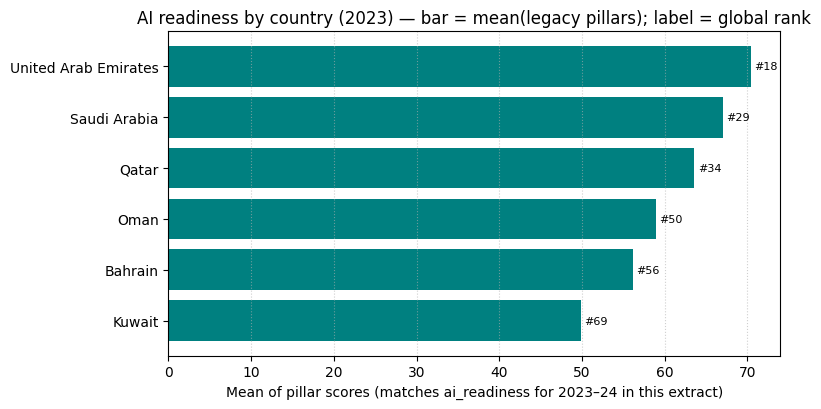

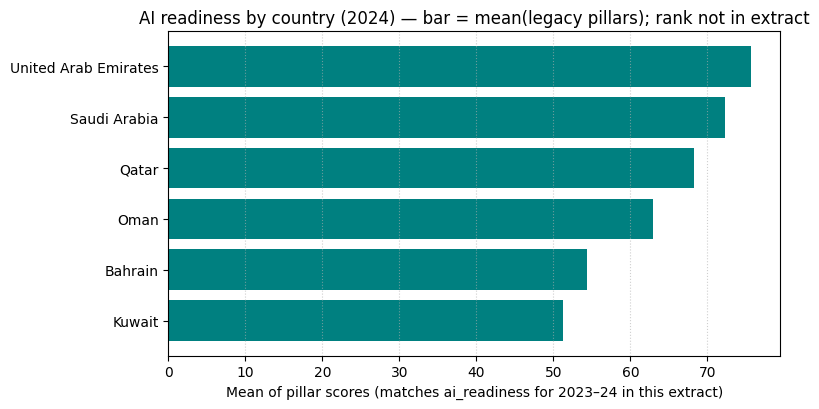

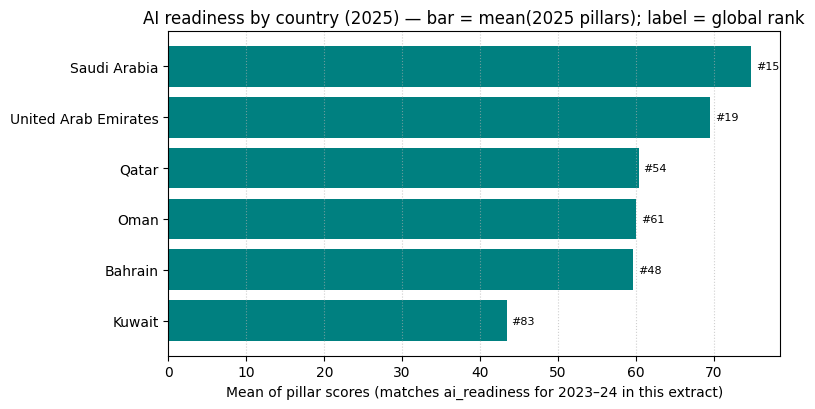

In [342]:
def _ai_pillar_mean(df, pillar_cols):
    return df[pillar_cols].mean(axis=1, skipna=True)


def plot_ai_score_bars_with_rank(
    df,
    year_label: str,
    rank_col="ai_readiness_rank",
    score_col="pillar_mean_score",
    xlabel=None,
    title=None,
):
    if df.empty or score_col not in df.columns:
        return
    fig, ax = plt.subplots(figsize=(8, 4.2))
    dd = df.dropna(subset=[score_col]).sort_values(score_col)
    if dd.empty:
        return
    ax.barh(dd["country"], dd[score_col], color="teal")

    pad = max(dd[score_col].max() - dd[score_col].min(), 1.0) * 0.02
    show_rank = bool(rank_col) and rank_col in dd.columns
    for i, (_, r) in enumerate(dd.iterrows()):
        if show_rank and pd.notna(r.get(rank_col)):
            ax.text(r[score_col] + pad, i, f"#{int(r[rank_col])}", va="center", fontsize=8)

    ax.set_xlabel(xlabel or "Mean of pillar scores")
    ax.set_title(title or f"AI readiness by country ({year_label})")
    ax.grid(True, axis="x", ls=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


# Sanity check: pillar row-mean matches published headline for 2023–24 (same construction as 2025 when total_score is missing)
_chk_parts = []
for _yr, _df in [(2023, ai_2023), (2024, ai_2024)]:
    if _df.empty or "ai_readiness" not in _df.columns:
        continue
    if not all(c in _df.columns for c in LEGACY_AI_PILLARS):
        continue
    _pm = _ai_pillar_mean(_df, LEGACY_AI_PILLARS)
    _chk_parts.append(
        _df.assign(year=_yr, mean_pillars=_pm)[["country", "year", "ai_readiness", "mean_pillars"]]
    )
    _mx = (_df["ai_readiness"] - _pm).abs().max()
    print(f"max |ai_readiness − mean(legacy pillars)| ({_yr}): {_mx:.6f}")
if _chk_parts:
    display(pd.concat(_chk_parts, ignore_index=True))

_xlabel_all = "Mean of pillar scores (matches ai_readiness for 2023–24 in this extract)"


def _with_pillar_mean(df, pillar_cols):
    out = df.copy()
    out["pillar_mean_score"] = _ai_pillar_mean(out, pillar_cols)
    return out


# Chronological: same bar grammar for 2023 → 2024 → 2025
if not ai_2023.empty:
    plot_ai_score_bars_with_rank(
        _with_pillar_mean(ai_2023, LEGACY_AI_PILLARS),
        "2023",
        rank_col="ai_readiness_rank",
        score_col="pillar_mean_score",
        xlabel=_xlabel_all,
        title="AI readiness by country (2023) — bar = mean(legacy pillars); label = global rank",
    )

if not ai_2024.empty:
    plot_ai_score_bars_with_rank(
        _with_pillar_mean(ai_2024, LEGACY_AI_PILLARS),
        "2024",
        rank_col=None,
        score_col="pillar_mean_score",
        xlabel=_xlabel_all,
        title="AI readiness by country (2024) — bar = mean(legacy pillars); rank not in extract",
    )

if not ai_2025.empty and all(c in ai_2025.columns for c in PILLARS_2025_AI):
    plot_ai_score_bars_with_rank(
        _with_pillar_mean(ai_2025, PILLARS_2025_AI),
        "2025",
        rank_col="ai_readiness_rank",
        score_col="pillar_mean_score",
        xlabel=_xlabel_all,
        title="AI readiness by country (2025) — bar = mean(2025 pillars); label = global rank",
    )


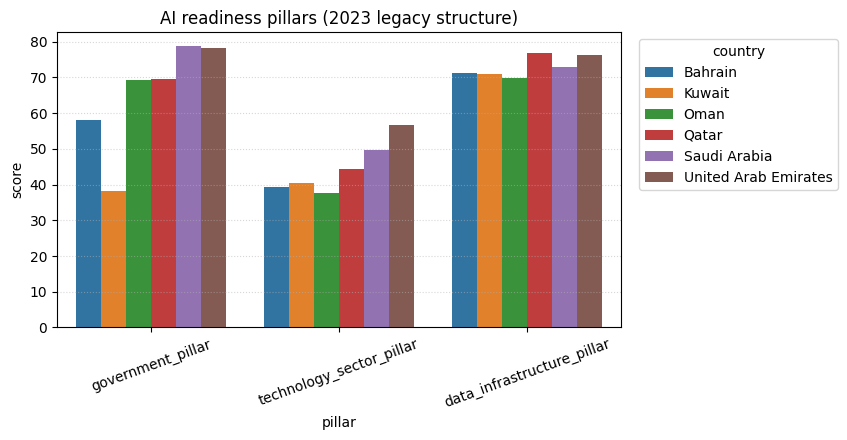

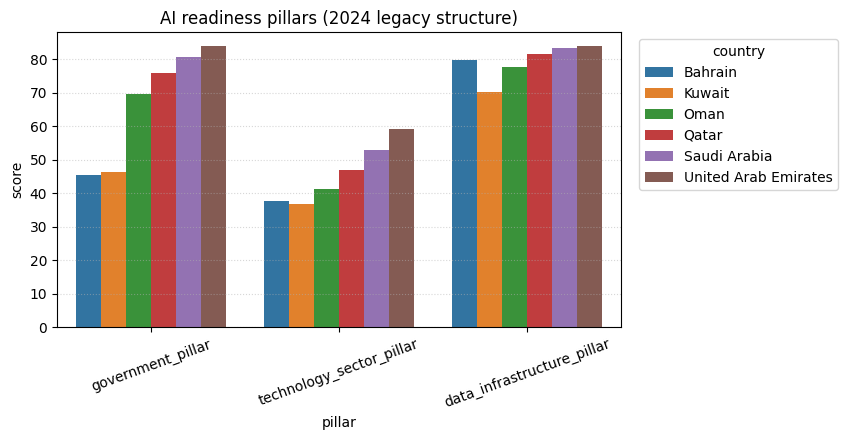

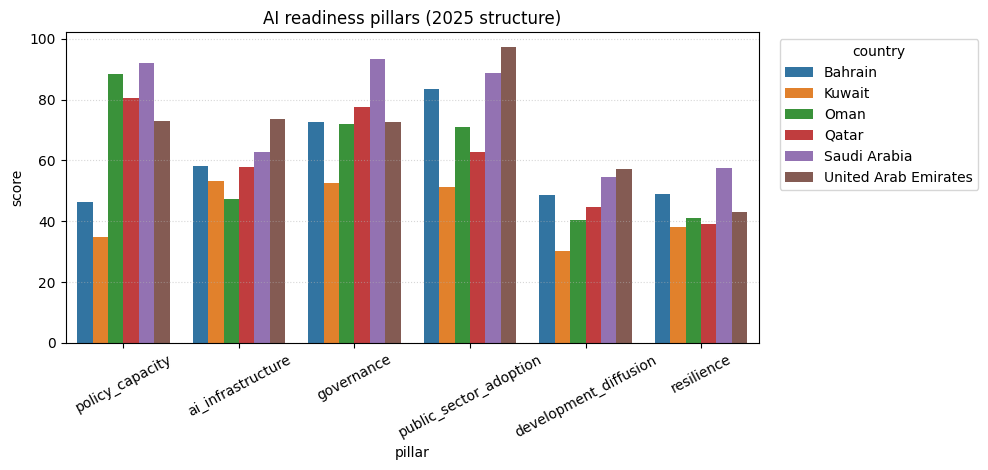

In [343]:
legacy_cols = LEGACY_AI_PILLARS
pillars_2025 = PILLARS_2025_AI

if not ai_2023.empty:
    long3 = ai_2023[["country"] + legacy_cols].melt(id_vars="country", var_name="pillar", value_name="score")
    fig, ax = plt.subplots(figsize=(8.6, 4.5))
    sns.barplot(data=long3, x="pillar", y="score", hue="country", ax=ax)
    ax.set_title("AI readiness pillars (2023 legacy structure)")
    ax.set_xlabel("pillar")
    ax.set_ylabel("score")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, axis="y", ls=":", alpha=0.5)
    ax.legend(title="country", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

if not ai_2024.empty:
    long4 = ai_2024[["country"] + legacy_cols].melt(id_vars="country", var_name="pillar", value_name="score")
    fig, ax = plt.subplots(figsize=(8.6, 4.5))
    sns.barplot(data=long4, x="pillar", y="score", hue="country", ax=ax)
    ax.set_title("AI readiness pillars (2024 legacy structure)")
    ax.set_xlabel("pillar")
    ax.set_ylabel("score")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, axis="y", ls=":", alpha=0.5)
    ax.legend(title="country", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

if not ai_2025.empty:
    long5 = ai_2025[["country"] + pillars_2025].melt(id_vars="country", var_name="pillar", value_name="score")
    fig, ax = plt.subplots(figsize=(10, 4.8))
    sns.barplot(data=long5, x="pillar", y="score", hue="country", ax=ax)
    ax.set_title("AI readiness pillars (2025 structure)")
    ax.set_xlabel("pillar")
    ax.set_ylabel("score")
    ax.tick_params(axis="x", rotation=28)
    ax.grid(True, axis="y", ls=":", alpha=0.5)
    ax.legend(title="country", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


### 3.3 Summary — Block C (Oxford AI readiness): Sharp takeaways

**Capability gap is the core result.** GCC countries show a clear readiness gradient rather than convergence, with leaders consistently ahead across pillars.

**Pillar-level diagnostics are more useful than headline rank.** The most actionable differences come from policy capacity, technology/infrastructure, governance, and diffusion dimensions.

**Transition reading.** AI readiness behaves like institutional and ecosystem capacity, i.e., a bridge between economic structure and innovation outcomes.

**Limits.** Short time span and mixed pillar schemas across vintages; use for directional diagnosis, not for causal trend claims.



### 3.4 Cross-block comparisons (GCC): What does this say about transition?

**Guiding question.** What do cross-block patterns say about **GCC transition readiness** beyond income levels?

**Design rule (strict availability).**
- **Macro ↔ Oxford AI** plots use **2023-2024 same-row data only** (2025 GCC rows have no WDI macro in this merge).
- **Innovation (GII) ↔ Oxford AI** is a **2025 same-row** view (both available in 2025 rows).
- **Lagged A↔B** plots (macro 2024 vs GII 2025) are **exploratory only** and focus on stronger-coverage macro variables: GDP per capita, **log10(GDP)**, export concentration, oil rents, and manufacturing.

**Why trade openness is not in lagged A↔B.** `trade_openness_gdp` coverage is too patchy for GCC in recent rows of this merged extract (especially 2024, while 2025 macro is absent). To keep conclusions sharp, the lagged openness-vs-GII scatter is intentionally excluded from the main set.

**Oxford AI scalar on y.**
- 2023-2024: `ai_readiness` (equivalent to the legacy pillar mean up to rounding).
- 2025: mean of six 2025 Oxford pillars (`policy_capacity`, `ai_infrastructure`, `governance`, `public_sector_adoption`, `development_diffusion`, `resilience`).

**Interpretation guardrails.** Six countries only; descriptive visuals, not causal inference.


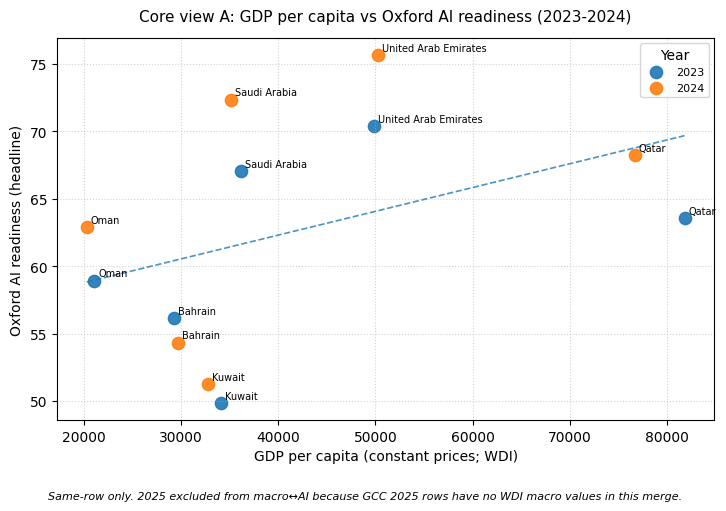

n = 12


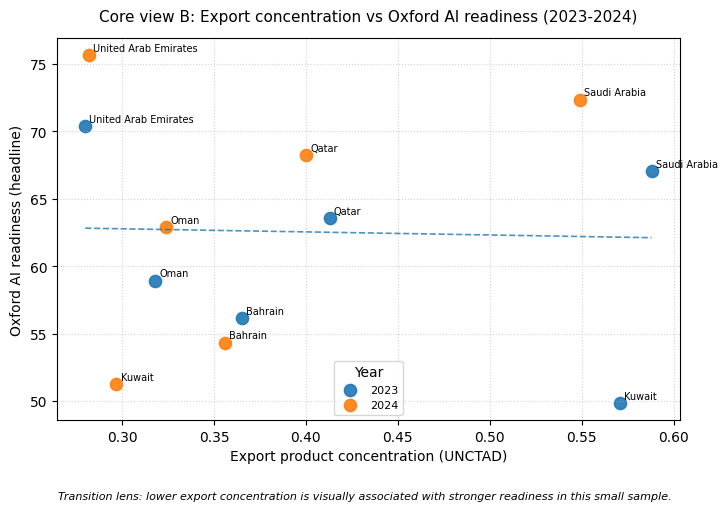

n = 12


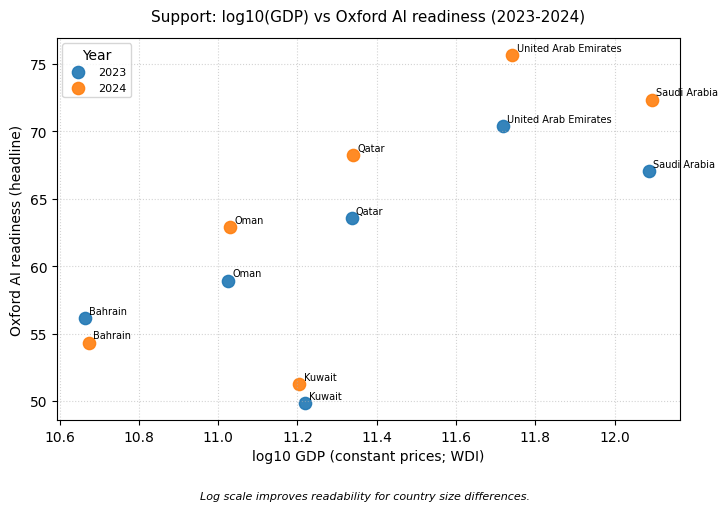

n = 12


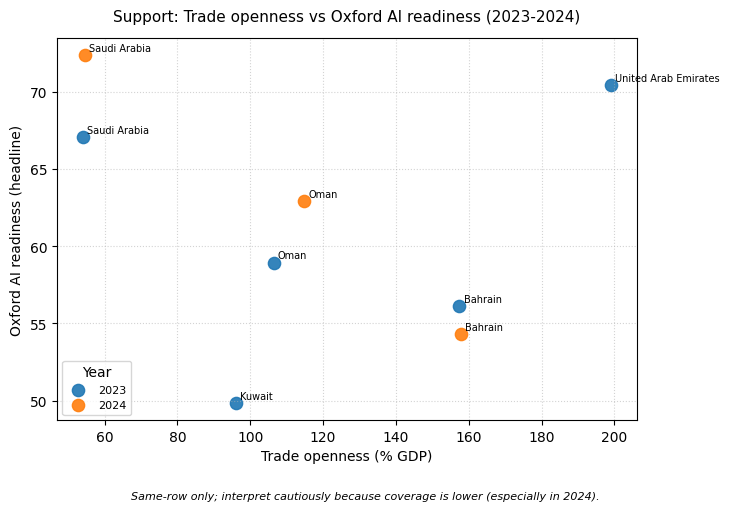

n = 8
skip (n=0): Support: Oil rents (% GDP) vs Oxford AI readiness (2023-2024)


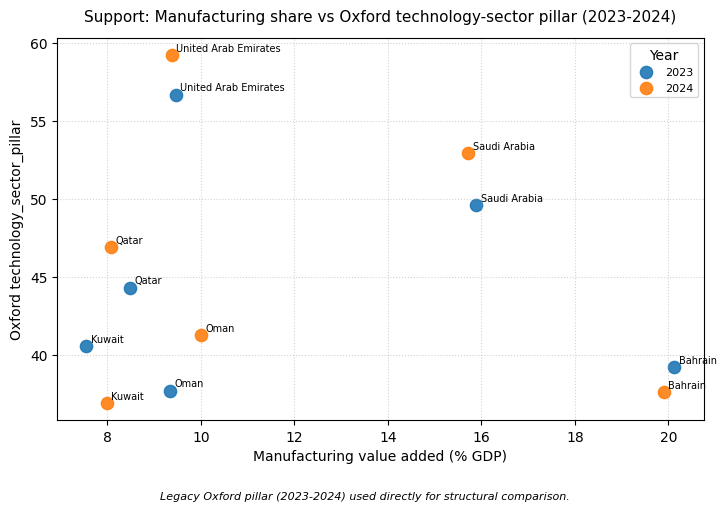

n = 12


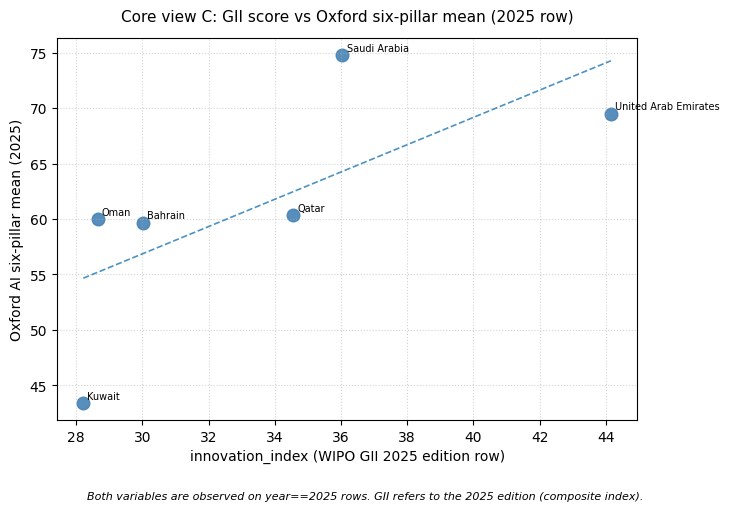

n = 6


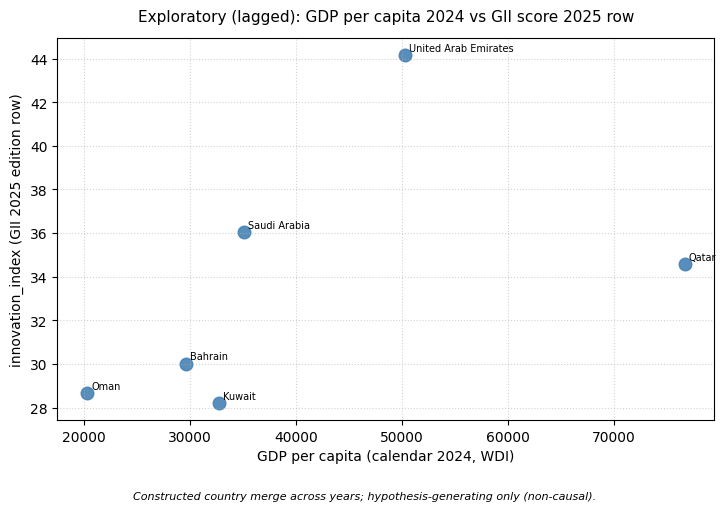

n = 6


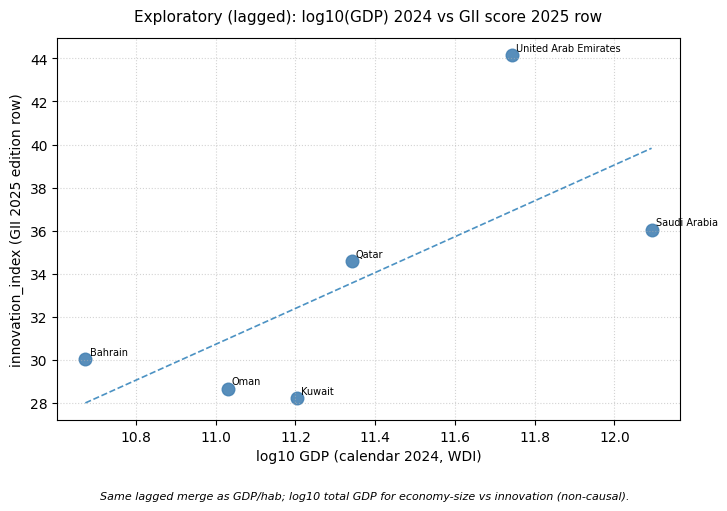

n = 6


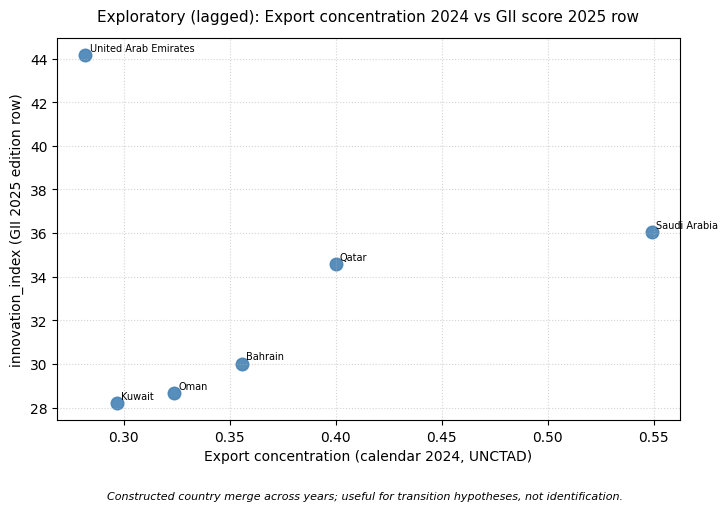

n = 6
skip (n=0): Exploratory (lagged): Oil rents (% GDP) 2024 vs GII score 2025 row


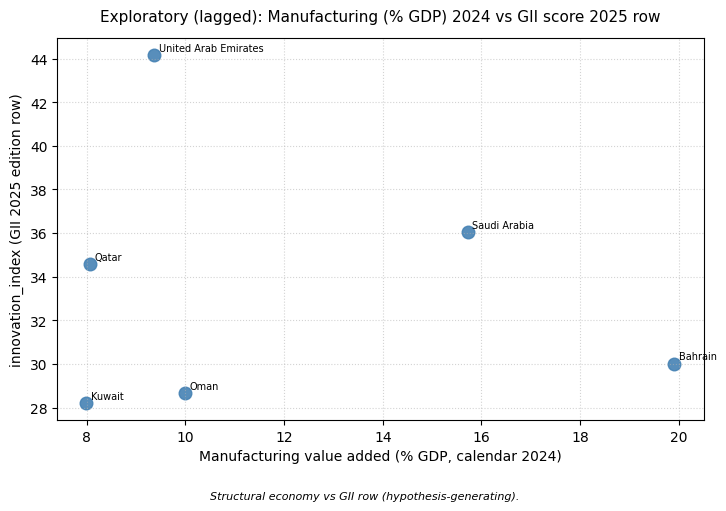

n = 6


In [344]:
# §3.4 — Cross-block plots for GCC transition narrative
GCC_COUNTRIES = [
    "Bahrain", "Kuwait", "Oman", "Qatar", "Saudi Arabia", "United Arab Emirates",
]


def _scatter_cc(df, x, y, title, subtitle, xlabel, ylabel, hue_year=False, min_n=3, trend=False):
    plot_df = df.dropna(subset=[x, y]).copy()
    if len(plot_df) < min_n:
        print(f"skip (n={len(plot_df)}): {title}")
        return

    fig, ax = plt.subplots(figsize=(7.4, 5.1))
    if hue_year and "year" in plot_df.columns:
        for yv in sorted(plot_df["year"].unique()):
            sub = plot_df[plot_df["year"] == yv]
            ax.scatter(sub[x], sub[y], s=78, alpha=0.90, label=str(int(yv)))
        ax.legend(title="Year", fontsize=8, loc="best")
    else:
        ax.scatter(plot_df[x], plot_df[y], s=82, alpha=0.90, color="steelblue")

    if trend and len(plot_df) >= 3:
        xd = plot_df[x].to_numpy(dtype=float)
        yd = plot_df[y].to_numpy(dtype=float)
        slope, intercept = np.polyfit(xd, yd, 1)
        xx = np.linspace(np.nanmin(xd), np.nanmax(xd), 100)
        ax.plot(xx, slope * xx + intercept, linestyle="--", linewidth=1.2, alpha=0.8)

    for _, r in plot_df.iterrows():
        ax.annotate(r["country"], (r[x], r[y]), fontsize=7, xytext=(3, 3), textcoords="offset points")

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=11, pad=12)
    ax.grid(True, ls=":", alpha=0.55)

    if subtitle:
        fig.text(0.5, 0.01, subtitle, ha="center", fontsize=8, style="italic", wrap=True)

    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()
    print(f"n = {len(plot_df)}")


base = data[data["country"].isin(GCC_COUNTRIES)].copy()
base["year"] = base["year"].astype(int)

# -------- Core macro↔AI panels (strict same-row, 2023-2024) --------
m_ai = base[base["year"].isin([2023, 2024])].copy()
m_ai["log10_gdp"] = np.where(m_ai["gdp"] > 0, np.log10(m_ai["gdp"]), np.nan)

_scatter_cc(
    m_ai,
    "gdp_per_capita",
    "ai_readiness",
    "Core view A: GDP per capita vs Oxford AI readiness (2023-2024)",
    "Same-row only. 2025 excluded from macro↔AI because GCC 2025 rows have no WDI macro values in this merge.",
    "GDP per capita (constant prices; WDI)",
    "Oxford AI readiness (headline)",
    hue_year=True,
    trend=True,
)

_scatter_cc(
    m_ai,
    "export_concentration",
    "ai_readiness",
    "Core view B: Export concentration vs Oxford AI readiness (2023-2024)",
    "Transition lens: lower export concentration is visually associated with stronger readiness in this small sample.",
    "Export product concentration (UNCTAD)",
    "Oxford AI readiness (headline)",
    hue_year=True,
    trend=True,
)

# -------- Supporting macro↔AI panels (same-row, 2023-2024) --------
_scatter_cc(
    m_ai,
    "log10_gdp",
    "ai_readiness",
    "Support: log10(GDP) vs Oxford AI readiness (2023-2024)",
    "Log scale improves readability for country size differences.",
    "log10 GDP (constant prices; WDI)",
    "Oxford AI readiness (headline)",
    hue_year=True,
)

_scatter_cc(
    m_ai,
    "trade_openness_gdp",
    "ai_readiness",
    "Support: Trade openness vs Oxford AI readiness (2023-2024)",
    "Same-row only; interpret cautiously because coverage is lower (especially in 2024).",
    "Trade openness (% GDP)",
    "Oxford AI readiness (headline)",
    hue_year=True,
)

_scatter_cc(
    m_ai,
    "oil_rents_gdp",
    "ai_readiness",
    "Support: Oil rents (% GDP) vs Oxford AI readiness (2023-2024)",
    "PostOil lens on hydrocarbon dependence vs digital/capability readiness (same-row).",
    "Oil rents (% GDP, WDI)",
    "Oxford AI readiness (headline)",
    hue_year=True,
)

_scatter_cc(
    m_ai,
    "manufacturing_gdp",
    "technology_sector_pillar",
    "Support: Manufacturing share vs Oxford technology-sector pillar (2023-2024)",
    "Legacy Oxford pillar (2023-2024) used directly for structural comparison.",
    "Manufacturing value added (% GDP)",
    "Oxford technology_sector_pillar",
    hue_year=True,
)

# -------- Core innovation↔AI panel (same-row, 2025) --------
d25 = base[base["year"] == 2025].copy()
if all(c in d25.columns for c in PILLARS_2025_AI):
    d25["ai_pillar_mean_2025"] = d25[PILLARS_2025_AI].mean(axis=1, skipna=True)
    _scatter_cc(
        d25,
        "innovation_index",
        "ai_pillar_mean_2025",
        "Core view C: GII score vs Oxford six-pillar mean (2025 row)",
        "Both variables are observed on year==2025 rows. GII refers to the 2025 edition (composite index).",
        "innovation_index (WIPO GII 2025 edition row)",
        "Oxford AI six-pillar mean (2025)",
        hue_year=False,
        trend=True,
    )
else:
    print("skip 2025 innovation↔AI: required pillar columns missing")

# -------- Exploratory lagged A↔B (constructed; not same-row) --------
macro_2024 = base[base["year"] == 2024][[
    "country",
    "gdp",
    "gdp_per_capita",
    "export_concentration",
    "oil_rents_gdp",
    "manufacturing_gdp",
]].copy()
macro_2024["log10_gdp_2024"] = np.where(macro_2024["gdp"] > 0, np.log10(macro_2024["gdp"]), np.nan)
macro_2024 = macro_2024.drop(columns=["gdp"]).rename(
    columns={
        "gdp_per_capita": "gdp_pc_2024",
        "export_concentration": "conc_2024",
        "oil_rents_gdp": "oil_2024",
        "manufacturing_gdp": "mfg_2024",
    }
)
gii_2025 = base[base["year"] == 2025][["country", "innovation_index"]].copy()
lag = macro_2024.merge(gii_2025, on="country", how="inner")

_scatter_cc(
    lag,
    "gdp_pc_2024",
    "innovation_index",
    "Exploratory (lagged): GDP per capita 2024 vs GII score 2025 row",
    "Constructed country merge across years; hypothesis-generating only (non-causal).",
    "GDP per capita (calendar 2024, WDI)",
    "innovation_index (GII 2025 edition row)",
    hue_year=False,
)

_scatter_cc(
    lag,
    "log10_gdp_2024",
    "innovation_index",
    "Exploratory (lagged): log10(GDP) 2024 vs GII score 2025 row",
    "Same lagged merge as GDP/hab; log10 total GDP for economy-size vs innovation (non-causal).",
    "log10 GDP (calendar 2024, WDI)",
    "innovation_index (GII 2025 edition row)",
    hue_year=False,
    trend=True,
)

_scatter_cc(
    lag,
    "conc_2024",
    "innovation_index",
    "Exploratory (lagged): Export concentration 2024 vs GII score 2025 row",
    "Constructed country merge across years; useful for transition hypotheses, not identification.",
    "Export concentration (calendar 2024, UNCTAD)",
    "innovation_index (GII 2025 edition row)",
    hue_year=False,
)

_scatter_cc(
    lag,
    "oil_2024",
    "innovation_index",
    "Exploratory (lagged): Oil rents (% GDP) 2024 vs GII score 2025 row",
    "PostOil lens: resource dependence vs innovation composite (small n; may skip if too many NaNs).",
    "Oil rents (% GDP, calendar 2024, WDI)",
    "innovation_index (GII 2025 edition row)",
    hue_year=False,
)

_scatter_cc(
    lag,
    "mfg_2024",
    "innovation_index",
    "Exploratory (lagged): Manufacturing (% GDP) 2024 vs GII score 2025 row",
    "Structural economy vs GII row (hypothesis-generating).",
    "Manufacturing value added (% GDP, calendar 2024)",
    "innovation_index (GII 2025 edition row)",
    hue_year=False,
)


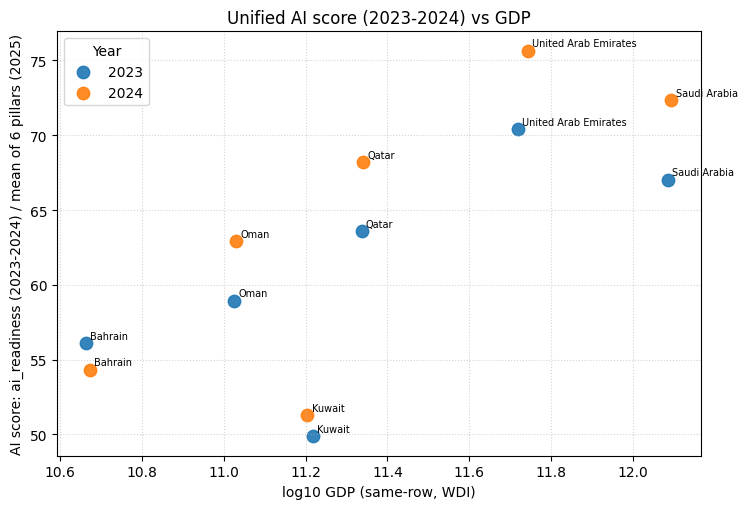

n = 12


In [345]:
# Unified AI score (y) vs GDP (x) for 2023, 2024, 2025
# y rule:
# - 2023-2024: ai_readiness (fallback to legacy pillar mean if missing)
# - 2025: mean of six 2025 pillars

gcc_countries = [
    "Bahrain", "Kuwait", "Oman", "Qatar", "Saudi Arabia", "United Arab Emirates",
]

legacy_pillars = [
    "government_pillar",
    "technology_sector_pillar",
    "data_infrastructure_pillar",
]

pillars_2025 = [
    "policy_capacity",
    "ai_infrastructure",
    "governance",
    "public_sector_adoption",
    "development_diffusion",
    "resilience",
]

df = data.copy()
df = df[df["country"].isin(gcc_countries)].copy()
df["year"] = df["year"].astype(int)
df = df[df["year"].isin([2023, 2024, 2025])].copy()

# Build unified y
df["ai_unified"] = np.nan

# 2023-2024: use ai_readiness when available
mask_2324 = df["year"].isin([2023, 2024])
df.loc[mask_2324, "ai_unified"] = df.loc[mask_2324, "ai_readiness"]

# fallback for 2023-2024 if ai_readiness missing
if all(c in df.columns for c in legacy_pillars):
    miss_2324 = mask_2324 & df["ai_unified"].isna()
    df.loc[miss_2324, "ai_unified"] = df.loc[miss_2324, legacy_pillars].mean(axis=1, skipna=True)

# 2025: mean of six pillars
if all(c in df.columns for c in pillars_2025):
    mask_2025 = df["year"] == 2025
    df.loc[mask_2025, "ai_unified"] = df.loc[mask_2025, pillars_2025].mean(axis=1, skipna=True)

# x = GDP (strict same-row)
plot_df = df.dropna(subset=["gdp", "ai_unified"]).copy()

if plot_df.empty:
    print("No rows with both GDP and unified AI score for 2023-2025.")
else:
    # Optional: log GDP for readability (comment out if you want raw GDP)
    plot_df["log10_gdp"] = np.where(plot_df["gdp"] > 0, np.log10(plot_df["gdp"]), np.nan)
    plot_df = plot_df.dropna(subset=["log10_gdp"])

    fig, ax = plt.subplots(figsize=(7.6, 5.2))
    for yv in sorted(plot_df["year"].unique()):
        sub = plot_df[plot_df["year"] == yv]
        ax.scatter(sub["log10_gdp"], sub["ai_unified"], s=80, alpha=0.9, label=str(int(yv)))

    for _, r in plot_df.iterrows():
        ax.annotate(
            r["country"],
            (r["log10_gdp"], r["ai_unified"]),
            fontsize=7,
            xytext=(3, 3),
            textcoords="offset points",
        )

    ax.set_title("Unified AI score (2023-2024) vs GDP")
    ax.set_xlabel("log10 GDP (same-row, WDI)")
    ax.set_ylabel("AI score: ai_readiness (2023-2024) / mean of 6 pillars (2025)")
    ax.grid(True, ls=":", alpha=0.55)
    ax.legend(title="Year")
    plt.tight_layout()
    plt.show()

    print(f"n = {len(plot_df)}")

#### 3.4 Tourism cross-block lens (latest available tourism × Oxford / GII)

Tourism series end around 2020-2023 in this extract (no GCC value in 2025), while AI readiness starts in 2023 — same-row scatter is therefore impossible. We use a **constructed lens**:

- For each country, take the **latest available** tourism row in 2017-2023 (so the indicator reflects a recent steady-state, not the 2020 pandemic dip alone).
- Pair it with **2023 Oxford AI readiness** (3-pillar mean) and **GII 2025**.
- UAE has no tourism `% of exports` in WDI, so we add a **derived fallback**: `tourism_receipts_usd / exports_usd × 100` to keep all six GCC visible.

This is **lagged and constructed**, so it is **non-causal / hypothesis-generating**, just like other lagged scatters in §3.4.

Cross-block table (tourism latest x AI 2023 x GII 2025):


,country,tourism_year,tourism_pct_exports_eff,tourism_receipts_pct_exports,tourism_receipts_usd,ai_readiness_2023,gii_2025,log10_tourism_usd
0,Qatar,2020,20.185176,20.185176,1.431800e+10,63.59,34.561768,10.155882
1,United Arab Emirates,2020,7.027400,NaN,2.461540e+10,70.42,44.154489,10.391207
2,Saudi Arabia,2020,3.223965,3.223965,5.960000e+09,67.04,36.044819,9.775246
3,Bahrain,2020,2.819280,2.819280,7.240000e+08,56.13,30.015766,8.859739
4,Oman,2020,1.874404,1.874404,6.690000e+08,58.94,28.649098,8.825426
5,Kuwait,2020,1.105103,1.105103,5.240000e+08,49.86,28.214302,8.719331


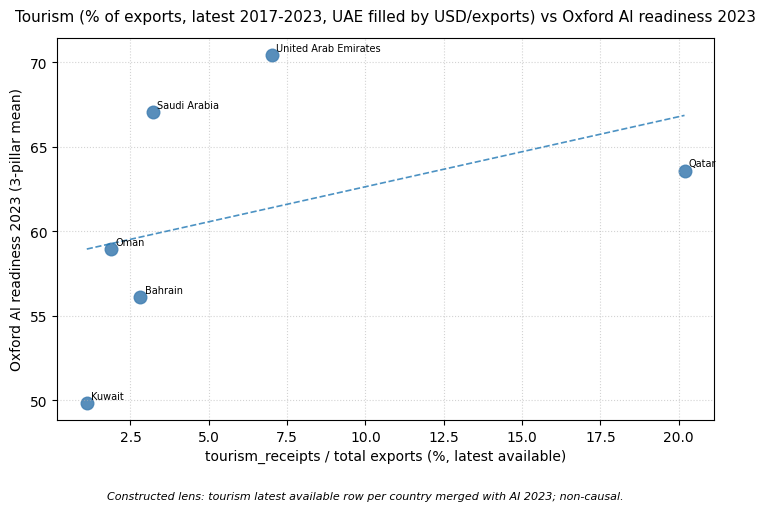

n = 6


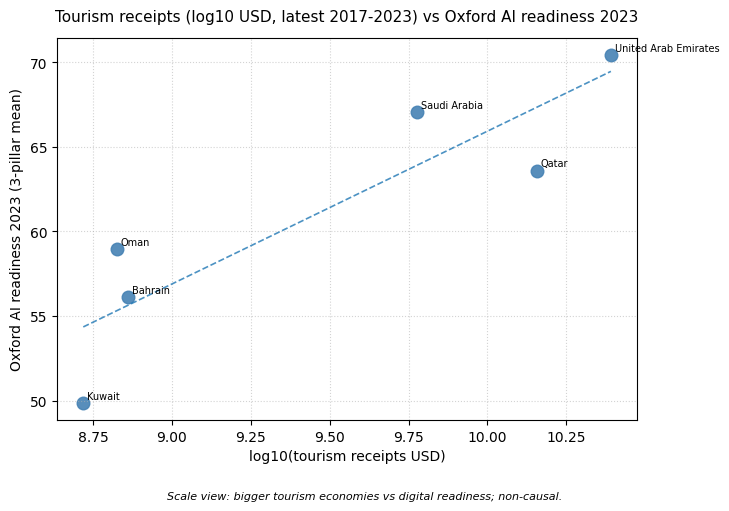

n = 6


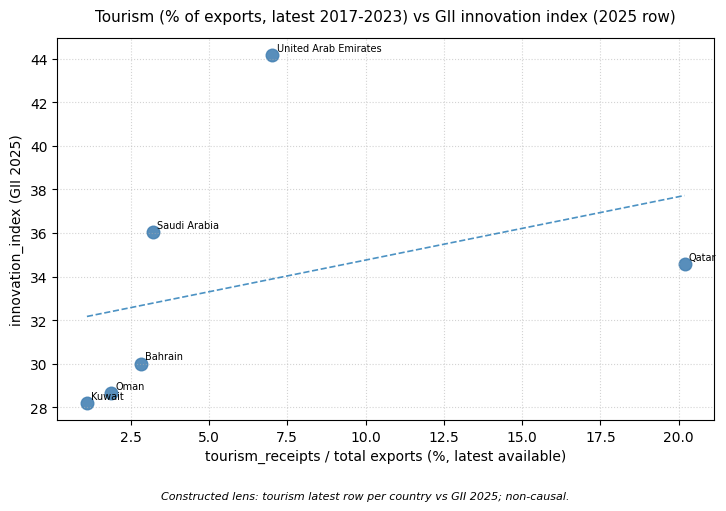

n = 6


In [346]:
# §3.4 — Tourism cross-block lens
TOURISM_LATEST_RANGE = (2017, 2023)

tourism_panel = data[data["country"].isin(GCC_COUNTRIES)].copy()
tourism_panel["year"] = tourism_panel["year"].astype(int)

tourism_panel["tourism_pct_eff"] = tourism_panel["tourism_receipts_pct_exports"].copy()
fallback_mask = (
    tourism_panel["tourism_pct_eff"].isna()
    & tourism_panel["tourism_receipts_usd"].notna()
    & tourism_panel["exports_usd"].notna()
    & (tourism_panel["exports_usd"] > 0)
)
tourism_panel.loc[fallback_mask, "tourism_pct_eff"] = (
    tourism_panel.loc[fallback_mask, "tourism_receipts_usd"]
    / tourism_panel.loc[fallback_mask, "exports_usd"]
    * 100.0
)

# Latest available tourism row per country in [2017, 2023]
window_lo, window_hi = TOURISM_LATEST_RANGE
window = tourism_panel[
    tourism_panel["year"].between(window_lo, window_hi)
    & tourism_panel[["tourism_pct_eff", "tourism_receipts_usd"]].notna().any(axis=1)
].copy()

idx = window.groupby("country")["year"].idxmax()
tourism_latest = window.loc[idx, [
    "country", "year", "tourism_pct_eff", "tourism_receipts_pct_exports", "tourism_receipts_usd",
]].rename(columns={
    "year": "tourism_year",
    "tourism_pct_eff": "tourism_pct_exports_eff",
})

# Pair with AI 2023 (3-pillar mean already in ai_readiness column) and GII 2025
ai_2023 = data[(data["country"].isin(GCC_COUNTRIES)) & (data["year"] == 2023)][
    ["country", "ai_readiness"]
].rename(columns={"ai_readiness": "ai_readiness_2023"})

gii_2025 = data[(data["country"].isin(GCC_COUNTRIES)) & (data["year"] == 2025)][
    ["country", "innovation_index"]
].rename(columns={"innovation_index": "gii_2025"})

cross = tourism_latest.merge(ai_2023, on="country", how="left").merge(gii_2025, on="country", how="left")
cross["log10_tourism_usd"] = np.log10(cross["tourism_receipts_usd"].where(cross["tourism_receipts_usd"] > 0))

print("Cross-block table (tourism latest x AI 2023 x GII 2025):")
display(
    cross.sort_values("tourism_pct_exports_eff", ascending=False)
        .reset_index(drop=True)
)

_scatter_cc(
    cross,
    "tourism_pct_exports_eff",
    "ai_readiness_2023",
    "Tourism (% of exports, latest 2017-2023, UAE filled by USD/exports) vs Oxford AI readiness 2023",
    "Constructed lens: tourism latest available row per country merged with AI 2023; non-causal.",
    "tourism_receipts / total exports (%, latest available)",
    "Oxford AI readiness 2023 (3-pillar mean)",
    hue_year=False,
    trend=True,
)

_scatter_cc(
    cross,
    "log10_tourism_usd",
    "ai_readiness_2023",
    "Tourism receipts (log10 USD, latest 2017-2023) vs Oxford AI readiness 2023",
    "Scale view: bigger tourism economies vs digital readiness; non-causal.",
    "log10(tourism receipts USD)",
    "Oxford AI readiness 2023 (3-pillar mean)",
    hue_year=False,
    trend=True,
)

_scatter_cc(
    cross,
    "tourism_pct_exports_eff",
    "gii_2025",
    "Tourism (% of exports, latest 2017-2023) vs GII innovation index (2025 row)",
    "Constructed lens: tourism latest row per country vs GII 2025; non-causal.",
    "tourism_receipts / total exports (%, latest available)",
    "innovation_index (GII 2025)",
    hue_year=False,
    trend=True,
)

### 3.4 Summary — GCC transition story from cross-block evidence

**Bottom line.** GCC transition readiness is **not income-only**: countries that pair stronger capability pillars with more diversified external structure appear better positioned to convert resources into innovation outcomes.

**Three strongest conclusions.**
1. **Capacity gradient:** UAE and Saudi Arabia remain the clearest high-readiness cases; Kuwait and Qatar illustrate that high income does not automatically translate into top readiness.
2. **Diversification channel:** The concentration view is the strongest PostOil signal; lower export concentration aligns with stronger AI-readiness positions in 2023-2024.
3. **Capability-to-innovation alignment:** In 2025 same-row data, higher Oxford six-pillar means co-move with higher GII scores, consistent with a **descriptive** capability–innovation pattern (not a causal mechanism).

**Tourism lens (§3.4 cross-block).** Latest available tourism position (2017-2023) — with a USD/exports fallback for UAE — paired with AI readiness 2023 and GII 2025:
- **log10(tourism receipts USD) vs AI 2023** is the **tightest** alignment: bigger tourism economies (UAE, then Saudi Arabia, Qatar) sit higher on AI readiness than the smaller ones (Oman, Bahrain, Kuwait).
- **Tourism share vs AI / GII** is **noisier**: Qatar shows a very high tourism share (~20%) but only mid AI/GII; UAE has a moderate effective share (~7%) yet leads AI and GII. Bahrain's structurally high share does not lift it on AI/GII either.
- Read tourism **share** as one diversification angle and tourism **scale** as a separate signal of integrated services capacity — neither is a substitute for AI/GII; merge is constructed and small-N (suggestive, not conclusive).

**Next steps:** Prioritize country-specific pillar gaps (policy capacity, infrastructure, governance, diffusion) and track whether diversification progress is accompanied by capability gains.

**Lagged macro scale.** Alongside GDP per capita, **log10(GDP) in 2024** vs the GII 2025 row checks whether **economy size** lines up with innovation performance under the same non-causal merge rules.

#### 3.4b Year-by-year diversification dashboard (2000→2024, multi-indicator)

The code cell below builds **paginated** heatmaps over **consecutive annual pairs** from **2000→2001** through **2023→2024** (the final pair matches the short two-year window used elsewhere in §3.4). Indicators cover diversification from several angles (not only export concentration):

- `export_concentration` (lower is better),
- `fuel_exports_pct` (lower is better),
- `manufacturing_gdp` (higher is better),
- `services_gdp` (higher is better),
- `tourism_receipts_pct_exports` (higher is better) — added; **UAE is structurally missing** in WDI for this column, so UAE will appear gray here.

Each cell encodes **direction** from year *t* to *t*+1: `+1` improvement, `-1` deterioration, gray = missing. A simple **net score** sums those signs across indicators (missing values ignored).


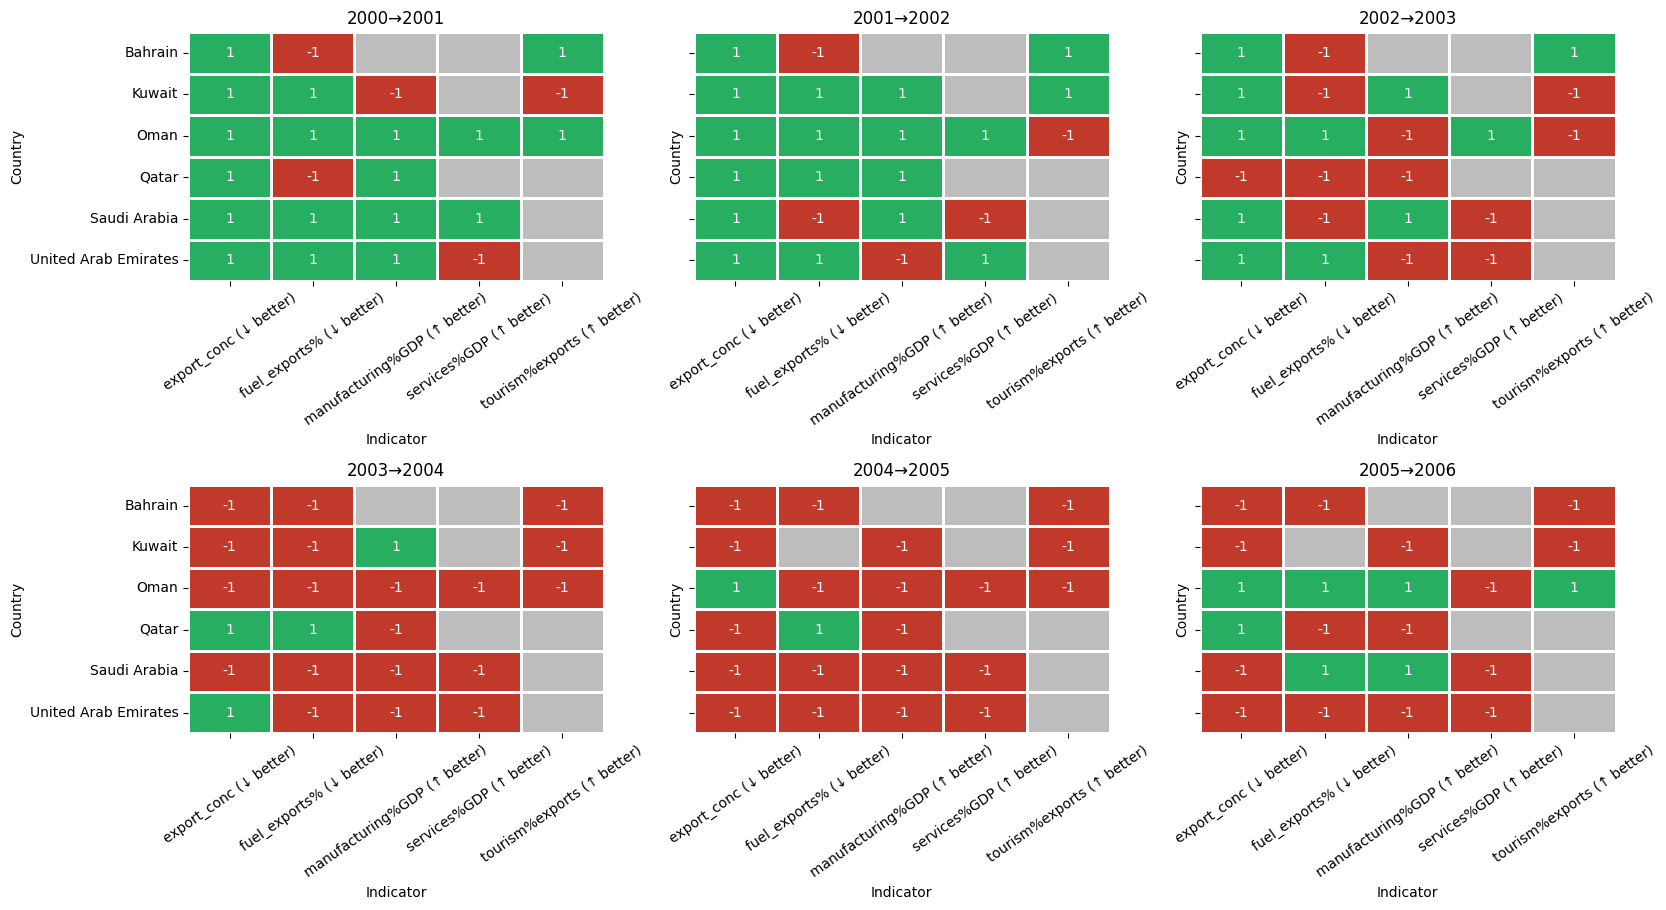

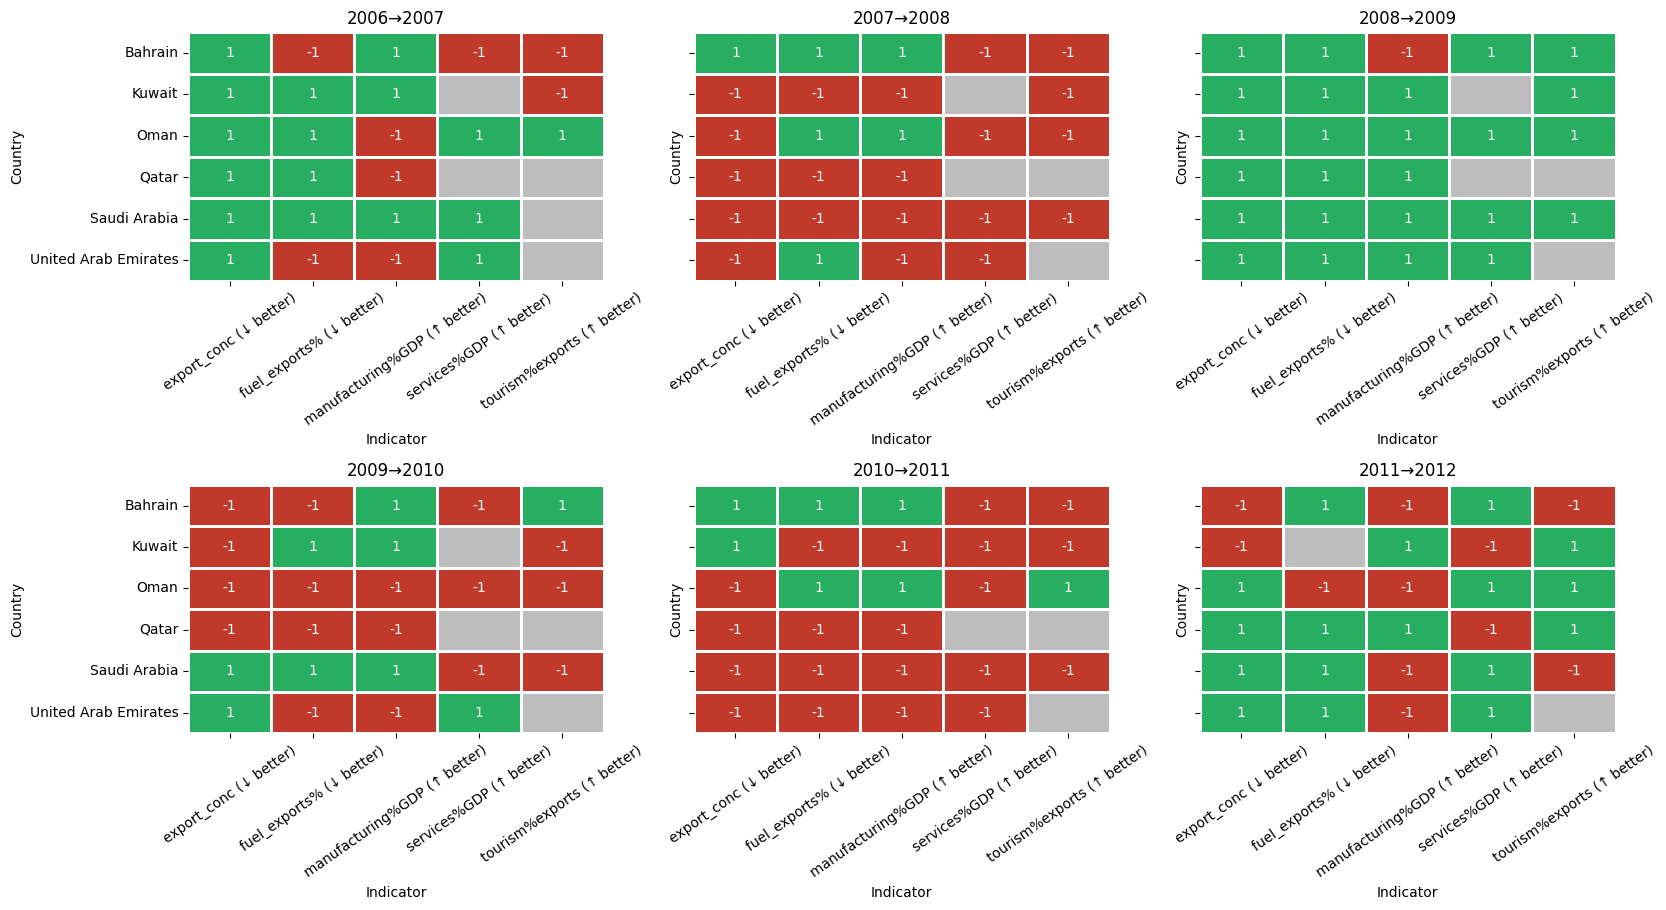

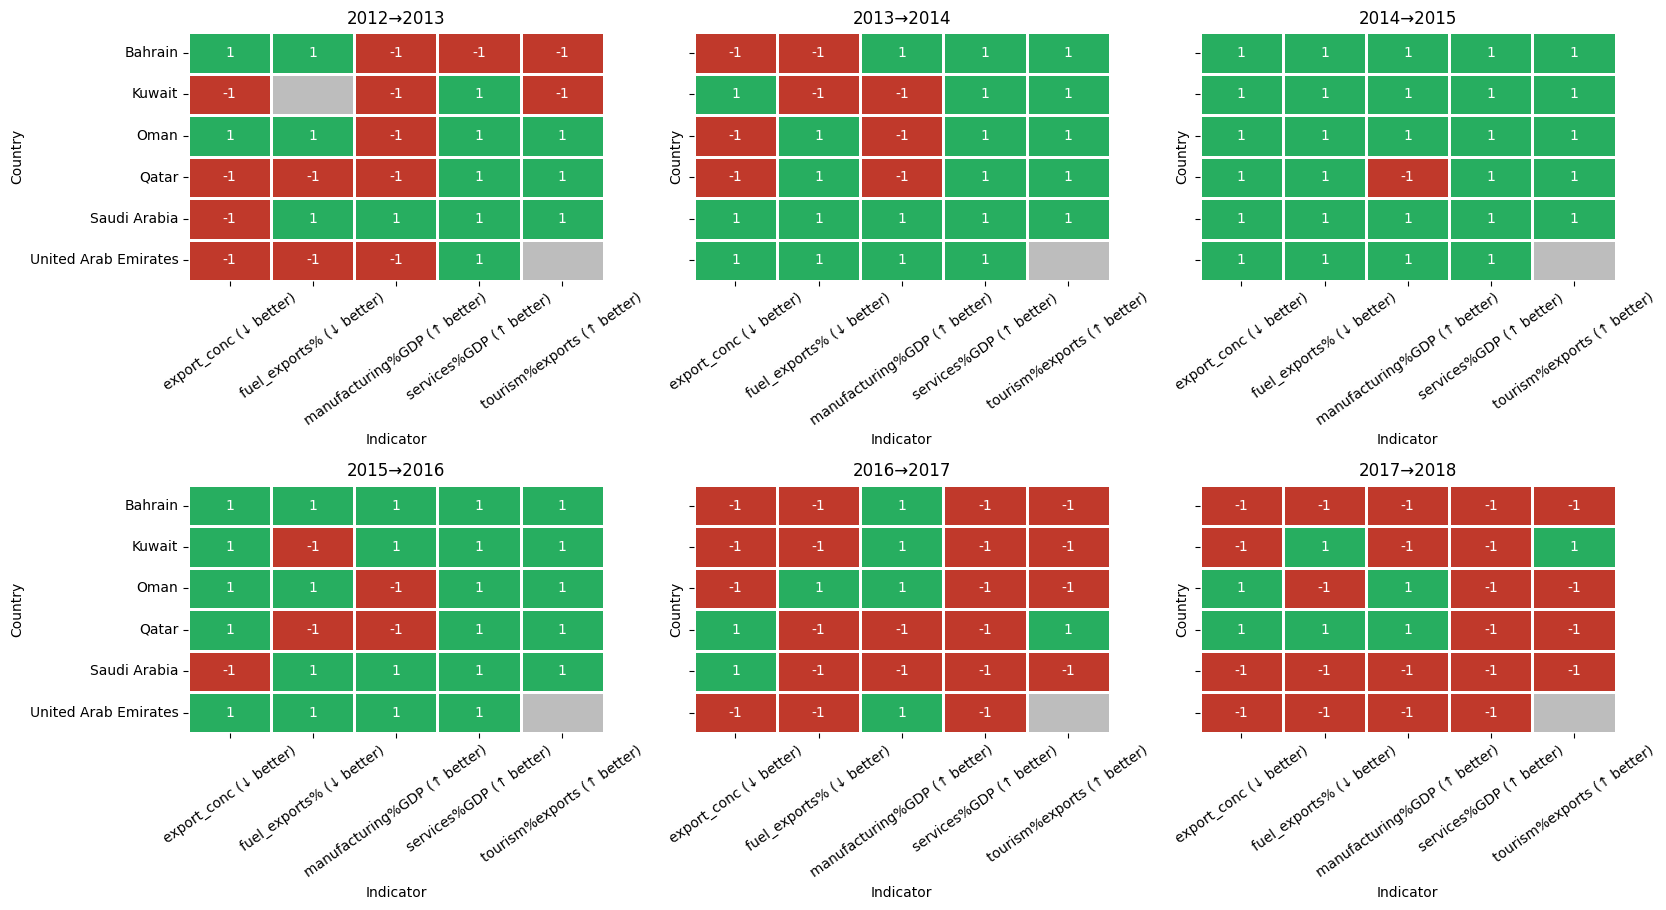

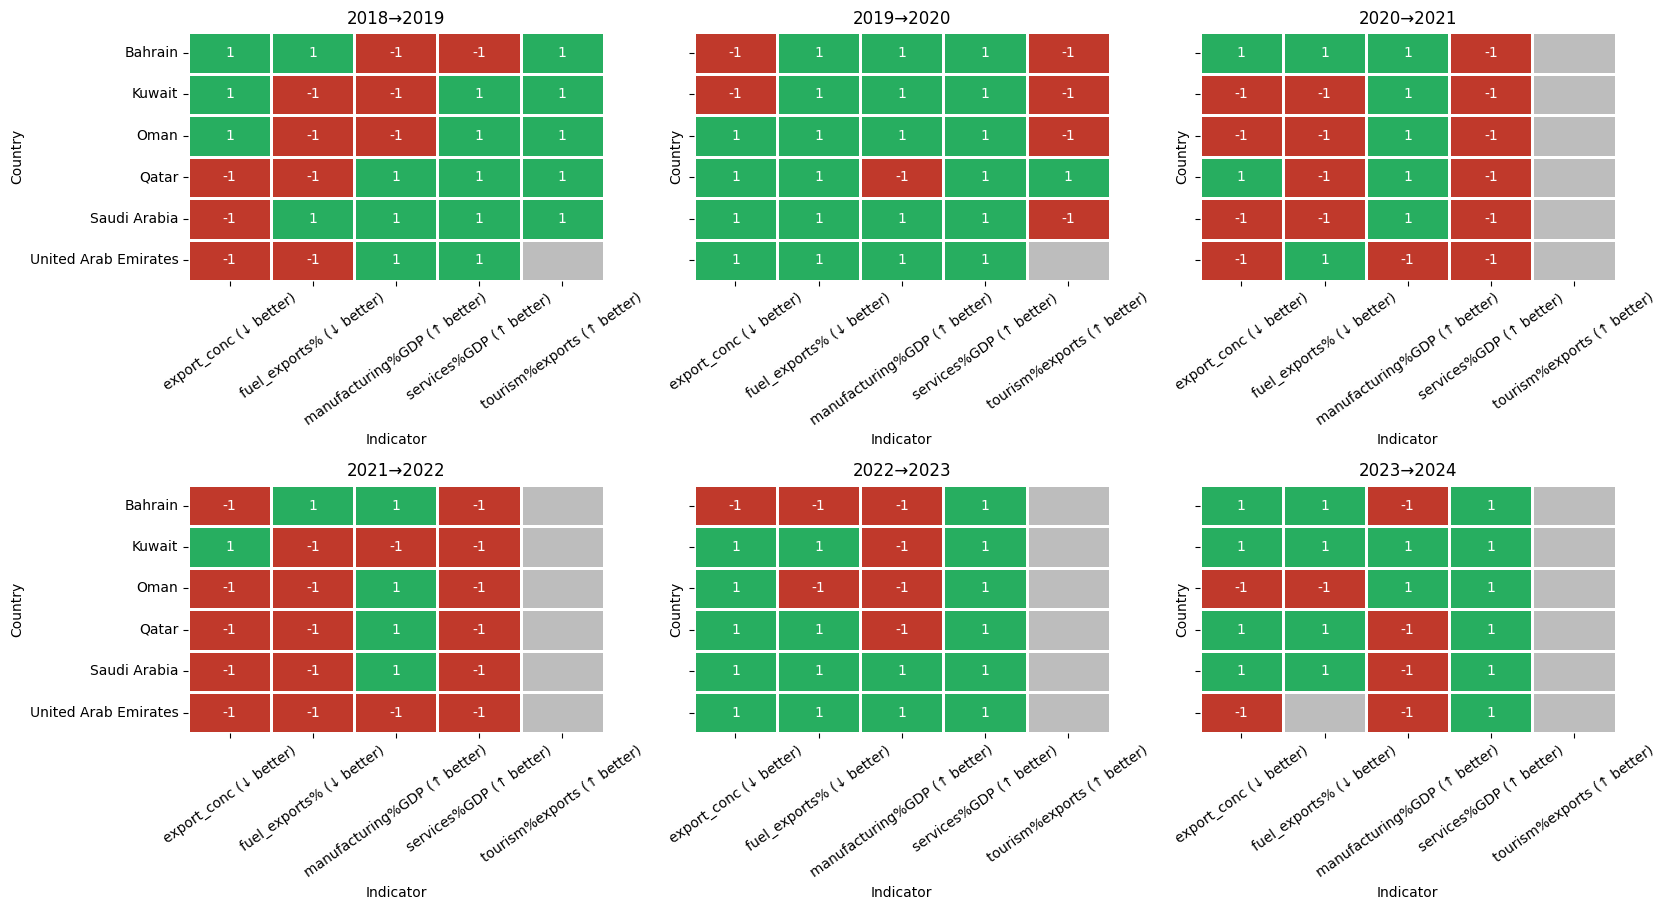

In [347]:
# Year-by-year diversification dashboard (discrete classes, paginated subplots)

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm


dashboard_countries = [
    "Bahrain", "Kuwait", "Oman", "Qatar", "Saudi Arabia", "United Arab Emirates"
]

indicators = [
    "export_concentration",          # lower is better
    "fuel_exports_pct",              # lower is better
    "manufacturing_gdp",             # higher is better
    "services_gdp",                  # higher is better
    "tourism_receipts_pct_exports",  # higher is better (UAE structurally missing in WDI)
]
lower_better = {"export_concentration", "fuel_exports_pct"}

years = list(range(2000, 2025))
pairs = list(zip(years[:-1], years[1:]))

df = data.copy()
df = df[df["country"].isin(dashboard_countries)].copy()
df["year"] = df["year"].astype(int)
df = df[df["year"].isin(years)][["country", "year"] + indicators].copy()

# Discrete colormap: -1 red, 0 yellow, +1 green ; NaN gray
cmap = ListedColormap(["#c0392b", "#f1c40f", "#27ae60"])
cmap.set_bad("#BDBDBD")
norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)

# Show several compact figures instead of one very wide chart
panels_per_figure = 6  # tweak to 4 if you want even larger panels

for start in range(0, len(pairs), panels_per_figure):
    chunk = pairs[start:start + panels_per_figure]
    n = len(chunk)

    ncols = min(3, n)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(5.6 * ncols, 4.6 * nrows),
        sharey=True,
    )

    if nrows == 1 and ncols == 1:
        axes = [axes]
    else:
        axes = np.array(axes).reshape(-1)

    for ax, (y0, y1) in zip(axes, chunk):
        sub = df[df["year"].isin([y0, y1])].copy()

        wide = sub.pivot(index="country", columns="year", values=indicators)
        wide.columns = [f"{v}_{y}" for v, y in wide.columns]
        wide = wide.reset_index()

        for v in indicators:
            for y in [y0, y1]:
                col = f"{v}_{y}"
                if col not in wide.columns:
                    wide[col] = np.nan

        out = pd.DataFrame({"country": wide["country"]})

        for v in indicators:
            d = wide[f"{v}_{y1}"] - wide[f"{v}_{y0}"]
            if v in lower_better:
                direction = np.where(d.isna(), np.nan, np.where(d < 0, 1, np.where(d > 0, -1, 0)))
            else:
                direction = np.where(d.isna(), np.nan, np.where(d > 0, 1, np.where(d < 0, -1, 0)))
            out[v] = direction

        heat = out.set_index("country")
        heat = heat.rename(columns={
            "export_concentration": "export_conc (↓ better)",
            "fuel_exports_pct": "fuel_exports% (↓ better)",
            "manufacturing_gdp": "manufacturing%GDP (↑ better)",
            "services_gdp": "services%GDP (↑ better)",
            "tourism_receipts_pct_exports": "tourism%exports (↑ better)",
        })
        heat = heat.reindex(dashboard_countries)

        sns.heatmap(
            heat,
            ax=ax,
            cmap=cmap,
            norm=norm,
            annot=True,
            fmt=".0f",
            cbar=False,
            linewidths=0.8,
            linecolor="white",
        )
        ax.set_title(f"{y0}→{y1}")
        ax.set_xlabel("Indicator")
        ax.set_ylabel("Country")
        ax.tick_params(axis="x", rotation=35)

    for ax in axes[len(chunk):]:
        ax.axis("off")

    # ERROR: The following fig.suptitle call contains an unterminated string (missing end quote).
    # Uncommenting will cause a SyntaxError.
    # fig.suptitle(
    #     "Year-by-year diversification direction dashboard
    #     (+1 improvement / 0 no-change / -1 deterioration / gray = missing)",
    #     y=1.02,
    # )
    plt.tight_layout()
    plt.show()


#### 3.4c Interpretation note — year-by-year diversification dashboard

**What this panel adds.** Unlike level plots, this dashboard tracks annual **direction** of structural change by country and indicator (`+1` improvement, `-1` deterioration, gray = missing).

**Time pattern is non-linear.** The GCC path is not monotonic: some intervals show broad deterioration while others show broad improvement, consistent with a regime-like transition process rather than a smooth trend.

**Recent signal.** The latest intervals (especially **2022→2023** and **2023→2024**) are more positive overall than several preceding intervals.

**Country heterogeneity remains central.** Country trajectories differ across years and indicators, reinforcing that transition is uneven and path-dependent.

**How to use with §3.4 core views.** Use this as a trajectory diagnostic (direction only), and keep scatter plots for levels/magnitude. Together they support the main conclusion: transition progress is structurally differentiated across GCC economies.

**Method caution.** Scores are discrete and unweighted across indicators; they are descriptive and non-causal.


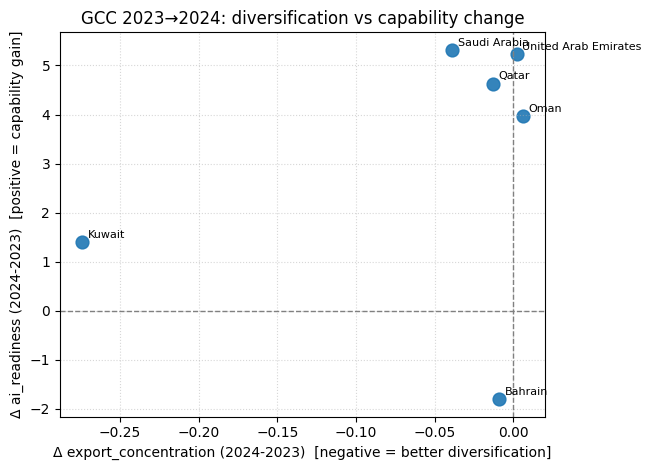

,country,d_conc_24_23,d_ai_24_23
4,Saudi Arabia,-0.039,5.32
5,United Arab Emirates,0.002,5.24
3,Qatar,-0.013,4.63
2,Oman,0.006,3.97
1,Kuwait,-0.274,1.40
0,Bahrain,-0.009,-1.80


In [348]:
# Small tracker after §3.4 summary: diversification vs capability change (2023→2024)
delta_df = (
    data[data["country"].isin(["Bahrain", "Kuwait", "Oman", "Qatar", "Saudi Arabia", "United Arab Emirates"])
         & data["year"].isin([2023, 2024])]
    [["country", "year", "export_concentration", "ai_readiness"]]
    .pivot(index="country", columns="year", values=["export_concentration", "ai_readiness"])
)

delta_df.columns = [f"{a}_{b}" for a, b in delta_df.columns]
delta_df = delta_df.reset_index()
delta_df["d_conc_24_23"] = delta_df["export_concentration_2024"] - delta_df["export_concentration_2023"]
delta_df["d_ai_24_23"] = delta_df["ai_readiness_2024"] - delta_df["ai_readiness_2023"]
plot_df = delta_df.dropna(subset=["d_conc_24_23", "d_ai_24_23"]).copy()

fig, ax = plt.subplots(figsize=(6.6, 4.8))
ax.scatter(plot_df["d_conc_24_23"], plot_df["d_ai_24_23"], s=85, alpha=0.9)
for _, r in plot_df.iterrows():
    ax.annotate(r["country"], (r["d_conc_24_23"], r["d_ai_24_23"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="gray", ls="--", lw=1)
ax.axvline(0, color="gray", ls="--", lw=1)
ax.set_title("GCC 2023→2024: diversification vs capability change")
ax.set_xlabel("Δ export_concentration (2024-2023)  [negative = better diversification]")
ax.set_ylabel("Δ ai_readiness (2024-2023)  [positive = capability gain]")
ax.grid(True, ls=":", alpha=0.5)
plt.tight_layout()
plt.show()

display(plot_df[["country", "d_conc_24_23", "d_ai_24_23"]].sort_values("d_ai_24_23", ascending=False))


#### Reading — diversification vs AI readiness (2023→2024)

This delta view ties the diversification–capability tracking idea to one chart: countries in the **upper-left** quadrant improve both diversification (lower concentration) and AI readiness.

**Country reads (illustrative).**

- **Kuwait:** largest diversification improvement (strong negative Δconcentration) with a positive AI-readiness gain, but from a low readiness base.
- **Saudi Arabia:** positive AI-readiness gain with moderate diversification improvement, consistent with a strengthening transition profile.
- **Bahrain:** slight diversification improvement but a decline in AI readiness, indicating short-run divergence between structure and capability.

Results are descriptive with a short window (2023→2024, n=6), so this is trajectory evidence, not causal proof.

#### 3.4d Composite diversification scores (0–100, GCC, 2013→2023)

**Placement in notebook.** This section sits **after §3.4c** and **before §3.5** so composite diversification summaries precede final strategic conclusions.

**Method (descriptive, non-causal).**
- Scope: GCC only (`Bahrain`, `Kuwait`, `Oman`, `Qatar`, `Saudi Arabia`, `United Arab Emirates`), years **2013–2023**.
- Indicators: `export_concentration`, `fuel_exports_pct`, `manufacturing_gdp`, `services_gdp`.
- Direction: lower is better for concentration + fuel; higher is better for manufacturing + services shares.
- Missingness: both scores require **all four** indicators on the row (`k=4`).

**Two composites (why two).**
1. **`diversification_score_intra_gcc_0_100` (intra‑GCC, by year).** Each indicator is min–max scaled to 0–100 **within the six countries in that year**, then averaged (equal weights). Answers: *“Who looks strongest **relative to GCC peers** this year?”* A country can fall if peers improve faster, even if its raw levels improve.
2. **`diversification_score_abs_panel_0_100` (panel‑fixed “absolute”).** Each indicator uses **one** min and max taken over **all GCC country–year rows in 2013–2023**, then scaled to 0–100 with the same directional rule, then averaged. Answers: *“How high are raw levels on a **stable scale** for this dataset window?”* Better for **country trajectories over time** than the intra‑year score.

**Why tourism is *not* in the primary 4-indicator score.** `tourism_receipts_pct_exports` is **structurally missing for UAE** in the WDI extract; including it strictly would force UAE to drop, biasing the GCC story. We therefore keep tourism **outside** the primary score and add an **optional 5-indicator sensitivity score** below, using a derived `tourism_pct_exports_eff` (USD/exports fallback) so all six countries stay comparable.

**Presentation.**
1. Side‑by‑side heatmaps (intra vs panel‑fixed) — **primary 4-indicator score**.
2. Two trajectory panels (same y‑scale 0–100) — primary score.
3. 2023 snapshot table with **both** primary scores, sorted by panel‑fixed score.
4. **Sensitivity:** 5-indicator panel-fixed score (with derived tourism share) — single heatmap + 2023 table.

Rows scored: 66
Countries: ['Bahrain', 'Kuwait', 'Oman', 'Qatar', 'Saudi Arabia', 'United Arab Emirates']
Years: 2013 to 2023


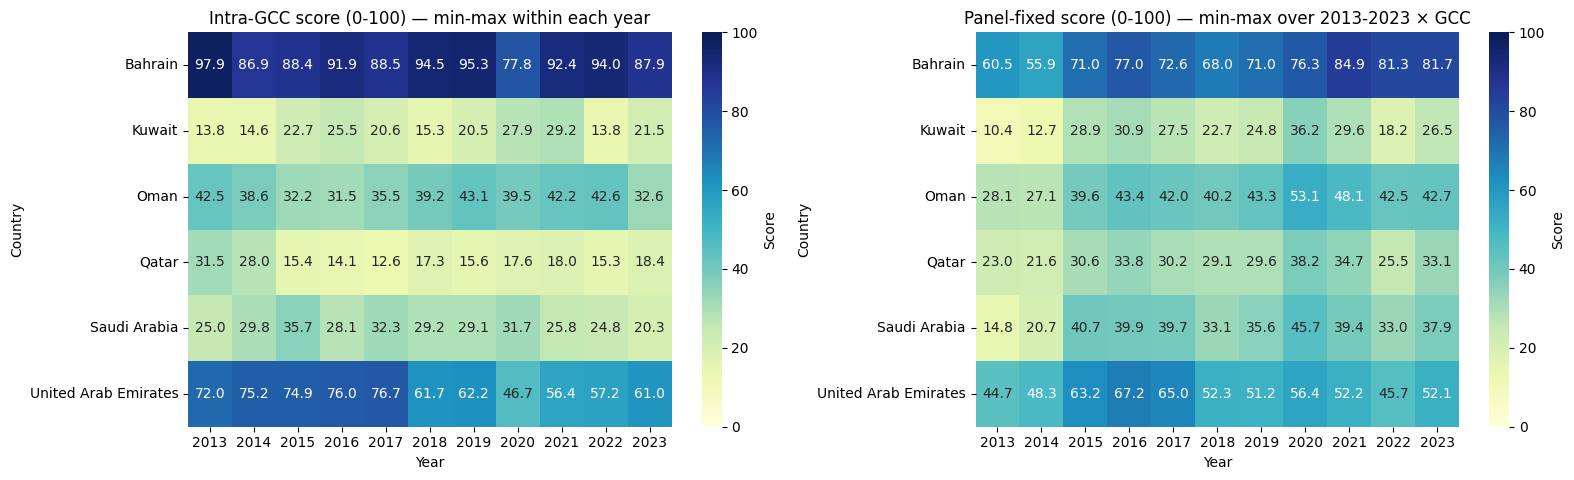

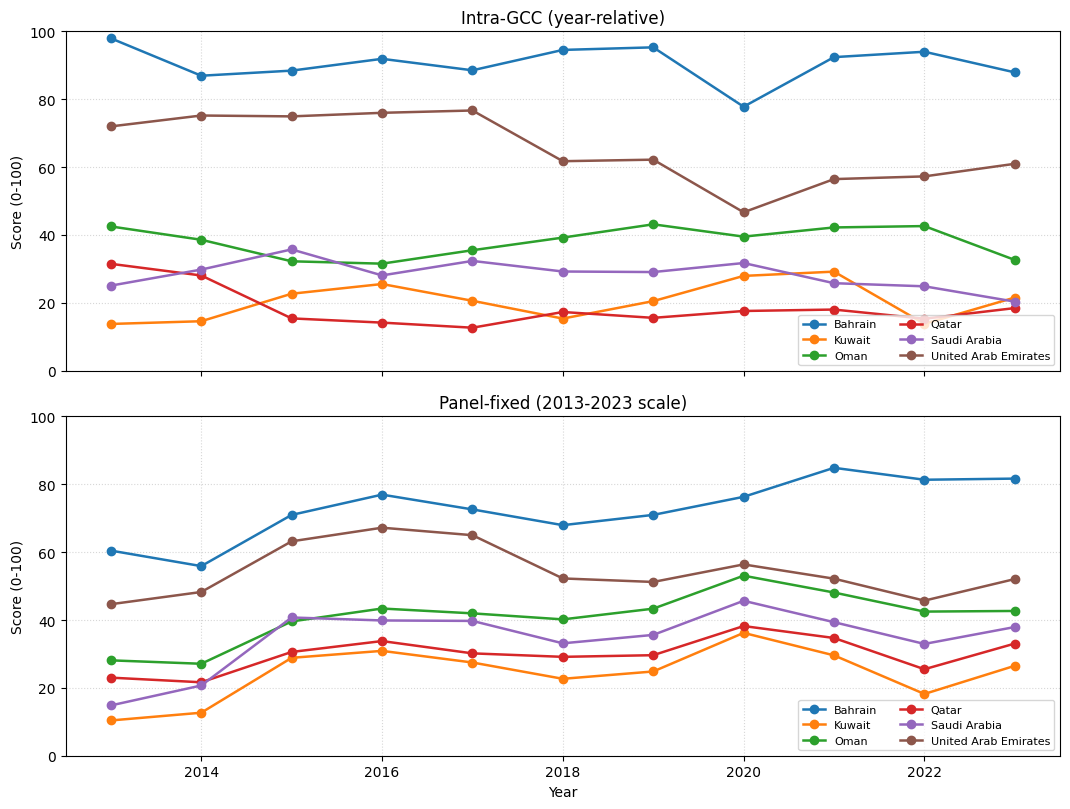

,country,diversification_score_intra_gcc_0_100,diversification_score_abs_panel_0_100
0,Bahrain,87.90,81.68
1,United Arab Emirates,60.96,52.08
2,Oman,32.62,42.67
3,Saudi Arabia,20.33,37.93
4,Qatar,18.43,33.06
5,Kuwait,21.54,26.51


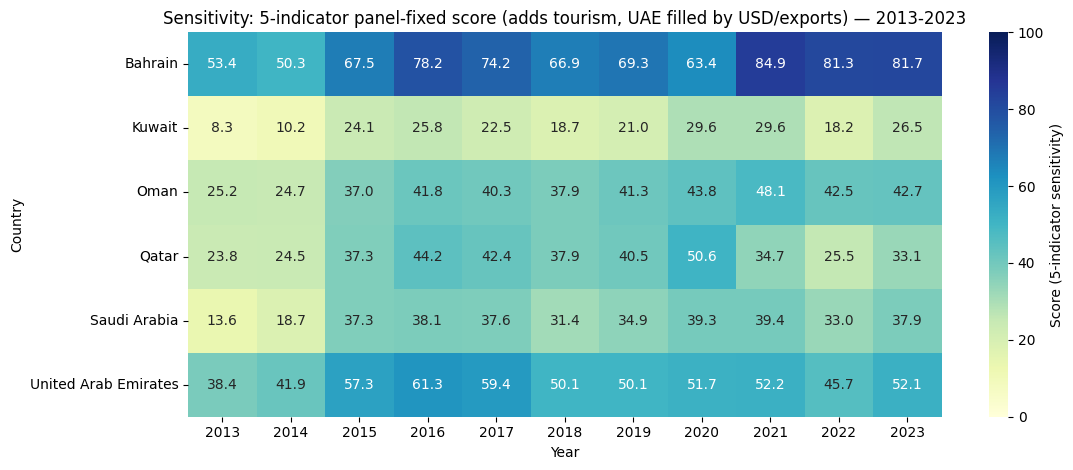

,country,diversification_score_5ind_panel_0_100
0,Bahrain,81.68
1,United Arab Emirates,52.08
2,Oman,42.67
3,Saudi Arabia,37.93
4,Qatar,33.06
5,Kuwait,26.51


In [349]:
# §3.4d — Composite diversification scores (0-100), GCC 2013-2023
# Two composites: (1) intra-GCC per year, (2) panel-fixed min-max over 2013-2023 × GCC.

gcc_countries = [
    "Bahrain", "Kuwait", "Oman", "Qatar", "Saudi Arabia", "United Arab Emirates",
]

score_cols = [
    "export_concentration",   # lower is better
    "fuel_exports_pct",       # lower is better
    "manufacturing_gdp",      # higher is better
    "services_gdp",           # higher is better
]
lower_better = {"export_concentration", "fuel_exports_pct"}

score_year_start, score_year_end = 2013, 2023

score_df = data[
    data["country"].isin(gcc_countries)
    & data["year"].between(score_year_start, score_year_end)
][["country", "year"] + score_cols].copy()

score_df["k_non_missing"] = score_df[score_cols].notna().sum(axis=1)
score_df = score_df[score_df["k_non_missing"] == len(score_cols)].copy()


def _minmax_0_100(values, lower_is_better: bool):
    """Vector scaling to 0-100; returns Series aligned to values.index."""
    s = values.astype(float)
    lo, hi = s.min(), s.max()
    if pd.isna(lo) or pd.isna(hi) or hi == lo:
        return pd.Series(50.0, index=s.index)
    if lower_is_better:
        return 100.0 * (hi - s) / (hi - lo)
    return 100.0 * (s - lo) / (hi - lo)


# --- (1) Intra-GCC: min-max within each year across the six countries ---
intra_sub_cols = []
for col in score_cols:
    lb = col in lower_better
    out = f"_intra_sub_{col}"
    score_df[out] = score_df.groupby("year", group_keys=False)[col].transform(
        lambda ser, lb=lb: _minmax_0_100(ser, lb)
    )
    intra_sub_cols.append(out)

score_df["diversification_score_intra_gcc_0_100"] = score_df[intra_sub_cols].mean(axis=1)

# --- (2) Panel-fixed: min-max across all country-year rows in this window ---
abs_sub_cols = []
for col in score_cols:
    lb = col in lower_better
    out = f"_abs_sub_{col}"
    score_df[out] = _minmax_0_100(score_df[col], lb)
    abs_sub_cols.append(out)

score_df["diversification_score_abs_panel_0_100"] = score_df[abs_sub_cols].mean(axis=1)

score_out = score_df[
    [
        "country",
        "year",
        "diversification_score_intra_gcc_0_100",
        "diversification_score_abs_panel_0_100",
    ]
].copy()
score_out = score_out.sort_values(
    ["year", "diversification_score_abs_panel_0_100"], ascending=[True, False]
)

print("Rows scored:", len(score_out))
print("Countries:", sorted(score_out["country"].unique()))
print("Years:", int(score_out["year"].min()), "to", int(score_out["year"].max()))

# 1) Heatmaps: intra vs panel-fixed
heat_intra = score_out.pivot(
    index="country", columns="year", values="diversification_score_intra_gcc_0_100"
).reindex(gcc_countries)
heat_abs = score_out.pivot(
    index="country", columns="year", values="diversification_score_abs_panel_0_100"
).reindex(gcc_countries)

fig, axes = plt.subplots(1, 2, figsize=(16.0, 4.9))
for ax, heat, title in zip(
    axes,
    [heat_intra, heat_abs],
    [
        "Intra-GCC score (0-100) — min-max within each year",
        "Panel-fixed score (0-100) — min-max over 2013-2023 × GCC",
    ],
):
    sns.heatmap(
        heat,
        ax=ax,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        cbar_kws={"label": "Score"},
    )
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel("Country")
plt.tight_layout()
plt.show()

# 2) Trajectories: two stacked panels (same y-scale)
line_df = score_out.sort_values(["country", "year"]).copy()
fig, axes = plt.subplots(2, 1, figsize=(10.8, 8.2), sharex=True)
for ax, col, title in zip(
    axes,
    ["diversification_score_intra_gcc_0_100", "diversification_score_abs_panel_0_100"],
    ["Intra-GCC (year-relative)", "Panel-fixed (2013-2023 scale)"],
):
    for c in gcc_countries:
        sub = line_df[line_df["country"] == c]
        if sub.empty:
            continue
        ax.plot(sub["year"], sub[col], marker="o", linewidth=1.8, label=c)
    ax.set_title(title)
    ax.set_ylabel("Score (0-100)")
    ax.set_ylim(0, 100)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(ncol=2, fontsize=8, loc="lower right")

axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

# 3) 2023 snapshot: both scores (sort by panel-fixed)
rank_2023 = (
    score_out[score_out["year"] == score_year_end][
        ["country", "diversification_score_intra_gcc_0_100", "diversification_score_abs_panel_0_100"]
    ]
    .sort_values("diversification_score_abs_panel_0_100", ascending=False)
    .reset_index(drop=True)
)

display(
    rank_2023.style.format(
        {
            "diversification_score_intra_gcc_0_100": "{:.2f}",
            "diversification_score_abs_panel_0_100": "{:.2f}",
        }
    )
)

# --- 5-indicator sensitivity score (adds tourism with USD/exports fallback for UAE) ---
sens_cols = score_cols + ["tourism_pct_exports_eff"]  # higher is better for tourism
sens_lower_better = lower_better  # tourism is not in lower_better (higher better)

sens_df = data[
    data["country"].isin(gcc_countries)
    & data["year"].between(score_year_start, score_year_end)
][["country", "year"] + score_cols + ["tourism_receipts_pct_exports", "tourism_receipts_usd", "exports_usd"]].copy()

# Build tourism_pct_exports_eff with USD/exports fallback (so UAE is filled)
sens_df["tourism_pct_exports_eff"] = sens_df["tourism_receipts_pct_exports"]
mask = (
    sens_df["tourism_pct_exports_eff"].isna()
    & sens_df["tourism_receipts_usd"].notna()
    & sens_df["exports_usd"].notna()
    & (sens_df["exports_usd"] > 0)
)
sens_df.loc[mask, "tourism_pct_exports_eff"] = (
    sens_df.loc[mask, "tourism_receipts_usd"] / sens_df.loc[mask, "exports_usd"] * 100.0
)

# Soft completeness rule: keep rows with at least 4 of 5 indicators present.
sens_df["k_non_missing"] = sens_df[sens_cols].notna().sum(axis=1)
sens_df = sens_df[sens_df["k_non_missing"] >= len(sens_cols) - 1].copy()

abs_sub_cols_sens = []
for col in sens_cols:
    lb = col in sens_lower_better
    out = f"_abs_sub_sens_{col}"
    sens_df[out] = _minmax_0_100(sens_df[col], lb)
    abs_sub_cols_sens.append(out)

sens_df["diversification_score_5ind_panel_0_100"] = sens_df[abs_sub_cols_sens].mean(axis=1, skipna=True)

heat_sens = (
    sens_df.pivot(index="country", columns="year", values="diversification_score_5ind_panel_0_100")
    .reindex(gcc_countries)
)

plt.figure(figsize=(11.5, 4.8))
sns.heatmap(
    heat_sens,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Score (5-indicator sensitivity)"},
)
plt.title("Sensitivity: 5-indicator panel-fixed score (adds tourism, UAE filled by USD/exports) — 2013-2023")
plt.xlabel("Year")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

rank_sens_2023 = (
    sens_df[sens_df["year"] == score_year_end][["country", "diversification_score_5ind_panel_0_100"]]
    .sort_values("diversification_score_5ind_panel_0_100", ascending=False)
    .reset_index(drop=True)
)
display(rank_sens_2023.style.format({"diversification_score_5ind_panel_0_100": "{:.2f}"}))


This is only based on those 4 columns (5 in the sensitivity view, with tourism added) and does not represent the actual diversification of those countries which depends on many other factors we didn't go through (employment composition, non-oil fiscal revenues, export complexity, FDI, etc.). It is therefore an **internal synthesis**, not an authoritative metric — we won't display this score on the frontend as a headline indicator. The sensitivity score is shown for transparency on how the picture moves once tourism is included with the WDI gap filled.

### 3.5 Consolidated strategic insights (interpretation phase)

The analysis is now in an **interpretation and storytelling** phase: the merge and EDA are sufficient to support a focused set of defensible claims.

**Dominant conclusion (project punchline).** The GCC transition story is fundamentally a **divergence story**: a subset of countries is structurally and institutionally progressing toward post-oil readiness, while others remain closer to resource-dependent equilibria.

1. **Structural divergence is observable, not abstract.** The UAE follows the clearest diversified trajectory, while Kuwait remains comparatively resource-dependent with weaker transition signals.

2. **Income is not a transition proxy.** High GDP per capita does not systematically translate into top AI-readiness or innovation positions across GCC countries.

3. **Export concentration is the dominant external-structure signal, but diversification is multi-dimensional.** Lower export concentration aligns with stronger AI-readiness profiles in cross-block comparisons, while complementary indicators (fuel export exposure, manufacturing and services shares, **international tourism receipts**) show heterogeneous year-to-year directional shifts across countries.

4. **Capability aligns with innovation performance (non-causal).** Stronger AI capability pillars co-move with stronger innovation outcomes in the 2025 same-row composite view, consistent with a capability-led conversion story—without claiming a causal mechanism.

5. **Resource wealth alone does not explain outcomes.** Capability-building and diversification, not rents alone, differentiate countries that translate economic strength into transition performance.

6. **Differences are persistent and path-dependent.** Cross-country gaps are larger than short-run year-to-year movement in the focus windows, indicating structural rather than cyclical divergence.

7. **Policy implication: focus on bottlenecks by pillar.** The most actionable path is to close country-specific gaps in policy capacity, infrastructure, governance, and diffusion while reducing export concentration risk.

8. **Tourism is a meaningful but partial diversification signal.** International tourism receipts (`% of exports` and `USD level`) confirm a non-hydrocarbon export channel: **Qatar** shows the steepest pre-2020 climb (≈3.6% → 20%), **Bahrain** is structurally high but volatile, **Saudi Arabia** ramps gradually (~2% → 7%), **Oman** stays moderate, **Kuwait** is structurally lowest (~1%), and **UAE** is the **clear leader in absolute USD level** while its WDI `% of exports` is missing (filled here by a documented `USD/exports` fallback). Pandemic 2020 is a sharp common dip and post-2023 GCC tourism is not in this extract — read tourism **share** as a diversification angle and tourism **scale** as a separate services-capacity signal, not as a proxy for AI/GII.

9. **Evidence scope.** Claims are descriptive, comparative, and **not causal** (small N, mixed-vintage sources, composite indices, plus indicators we did *not* explore such as employment composition, non-oil fiscal revenues, export complexity, FDI), but strong enough to support strategic positioning and **follow-on research** (clearer indicators, longer panels, or formal designs where data allow).